# 02 — Market Distributions

**Purpose:** characterize the empirical distributions, tails, cross-asset heterogeneity, and temporal persistence of the **futures / market-state feature block** before any regime model is fitted.

This notebook is deliberately diagnostic. It:

- opens `research.duckdb` in **read-only** mode;
- uses `time_series_feature_state` as the primary research table;
- analyzes returns, realized volatility, activity/flow, price-bar structure, open interest, basis/spreads, and the standard L2 state;
- compares pooled distributions with **per-underlying** distributions;
- separates **full-range** views from **central-range** views instead of clipping or winsorizing observations;
- inspects extreme observations in their original timestamp / asset context;
- studies autocorrelation and session-to-session variation;
- evaluates candidate transforms only as **research hypotheses**;
- audits futures quote integrity and open-interest jumps on raw collector fields (Part I).

It does **not**:

- impute missing values;
- winsorize or delete tail events (integrity flags describe suspect states; they do not remove them);
- globally standardize across assets;
- fit HMMs / HSMMs;
- fit the Clean/Noisy latent chain;
- analyze the newly collected L2-instability block in depth (reserved for Notebook 04);
- analyze option-surface distributions (reserved for Notebook 03).

> Research rule: distribution diagnostics should reveal the data-generating structure, not force every feature to look Gaussian.

## 1. Environment and read-only database connection

The notebook follows the same database discipline as `01_feature_inventory.ipynb`: the research database is opened read-only and no production relation is modified.

The DuckDB session time zone is set to **UTC**. Without it, `TIMESTAMPTZ` values come back in the PC's local zone (Europe/Madrid, which also changes at DST), and every hour-of-day result would be shifted.


In [141]:
from pathlib import Path
import os
import math
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 220)
pd.set_option("display.max_rows", 220)
pd.set_option("display.width", 200)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError(
        "DERIBIT_DATA_ROOT is not defined in the environment/.env file."
    )

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"

if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")

print(f"Research DB: {DB_PATH}")
print("Connection mode: read-only")
print("Session time zone:", con.execute("SELECT current_setting('TimeZone')").fetchone()[0])

Research DB: D:\MarketData\Deribit\database\research.duckdb
Connection mode: read-only
Session time zone: UTC


## 2. Load the market-facing state table

The table grain is expected to remain:

**one row = one underlying × one five-minute state**

Unlike Notebook 01, this notebook does **not** apply one global readiness filter. Each feature family is analyzed using its own valid observations and, where appropriate, its component-specific readiness flag. This avoids discarding valid futures observations merely because an unrelated options component was unavailable.

In [142]:
features = con.execute(
    """
    SELECT *
    FROM time_series_feature_state
    ORDER BY state_time, underlying
    """
).df()

features["state_time"] = pd.to_datetime(features["state_time"], utc=True)

print(f"Rows:        {len(features):,}")
print(f"Columns:     {features.shape[1]:,}")
print(f"Underlyings: {features['underlying'].nunique(dropna=True):,}")
print(f"First state: {features['state_time'].min()}")
print(f"Last state:  {features['state_time'].max()}")

assert features["state_id"].duplicated().sum() == 0
assert features.duplicated(subset=["underlying", "state_time"]).sum() == 0

Rows:        34,272
Columns:     223
Underlyings: 7
First state: 2026-09-19 08:00:00+00:00
Last state:  2026-10-06 07:55:00+00:00


## 3. Analysis feature families

The groups below are intentionally narrower than the full feature inventory.

The aim is to understand the **market-state block** that may later contribute to:

- structural HSMM emissions;
- persistence / transition predictors;
- model-time normalization decisions.

Option-surface features are deferred to Notebook 03. The new L2-instability scalars are intentionally not a main subject here because their history is still short.

In [143]:
FEATURE_GROUPS = {
    "returns": [
        "return_5m",
        "return_15m",
        "return_30m",
        "return_1h",
    ],
    "realized_volatility": [
        "realized_vol_30m",
        "realized_vol_1h",
        "realized_vol_4h",
        "realized_vol_30m_annualized",
        "realized_vol_1h_annualized",
        "realized_vol_4h_annualized",
    ],
    "activity_flow": [
        "volume_usd",
        "log1p_volume_usd",
        "signed_volume_usd",
        "trade_flow_imbalance",
        "buy_volume_share",
        "average_trade_size_usd",
        "trade_count",
    ],
    "bar_structure_open_interest": [
        "intrabar_range_bps",
        "close_vs_vwap_bps",
        "open_interest",
        "open_interest_change_5m",
        "open_interest_return_5m",
    ],
    "basis_spread_microprice": [
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "perpetual_mark_vs_index_bps",
        "microprice_vs_mid_bps",
        "book_twa_spread_bps",
        "book_twa_microprice_vs_reference_bps",
    ],
    "standard_l2": [
        "book_twa_obi_5",
        "book_twa_obi_10",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
        "book_twa_bid_depth_20",
        "book_twa_ask_depth_20",
        "book_twa_spread",
        "book_twa_microprice",
    ],
}

available_groups = {
    group: [c for c in cols if c in features.columns]
    for group, cols in FEATURE_GROUPS.items()
}

for group, cols in available_groups.items():
    print(f"{group:<30} {len(cols):>2} / {len(FEATURE_GROUPS[group]):>2} available")
    missing = [c for c in FEATURE_GROUPS[group] if c not in features.columns]
    if missing:
        print("  missing:", missing)

returns                         4 /  4 available
realized_volatility             6 /  6 available
activity_flow                   7 /  7 available
bar_structure_open_interest     5 /  5 available
basis_spread_microprice         6 /  6 available
standard_l2                     8 /  8 available


## 4. Generic diagnostic helpers

Two principles are built into these helpers:

1. **Full range and central range are different questions.** Full-range plots show the existence of tail events; central-range plots show ordinary-state structure.
2. **Pooled crypto data can be misleading.** Per-underlying summaries remain first-class outputs throughout this notebook.

In [144]:
CENTRAL_LOWER_Q = 0.005
CENTRAL_UPPER_Q = 0.995
TAIL_QS = [0.001, 0.01, 0.05, 0.50, 0.95, 0.99, 0.999]

def clean_numeric(df, column):
    return (
        pd.to_numeric(df[column], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

def feature_summary(df, columns, group_col=None):
    rows = []
    iterator = [("ALL", df)] if group_col is None else df.groupby(group_col, dropna=False)

    for group_name, group in iterator:
        for col in columns:
            if col not in group.columns:
                continue

            s = clean_numeric(group, col)
            if s.empty:
                continue

            q = s.quantile(TAIL_QS)
            rows.append({
                "group": group_name,
                "feature": col,
                "n": len(s),
                "missing_pct": 100.0 * (len(group) - len(s)) / len(group),
                "mean": s.mean(),
                "std": s.std(),
                "skew": s.skew(),
                "excess_kurtosis": s.kurt(),
                "min": s.min(),
                "q001": q.loc[0.001],
                "q01": q.loc[0.01],
                "q05": q.loc[0.05],
                "median": q.loc[0.50],
                "q95": q.loc[0.95],
                "q99": q.loc[0.99],
                "q999": q.loc[0.999],
                "max": s.max(),
            })

    return pd.DataFrame(rows)

def plot_full_and_central(df, column, bins=100):
    s = clean_numeric(df, column)
    if s.empty:
        print(f"{column}: no observations")
        return

    lo = s.quantile(CENTRAL_LOWER_Q)
    hi = s.quantile(CENTRAL_UPPER_Q)
    central = s[(s >= lo) & (s <= hi)]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    axes[0].hist(s, bins=bins)
    axes[0].set_title(f"{column} — full range")
    axes[0].set_ylabel("Count")

    axes[1].hist(central, bins=bins)
    axes[1].set_title(
        f"{column} — central {100*(CENTRAL_UPPER_Q-CENTRAL_LOWER_Q):.1f}%"
    )
    axes[1].set_ylabel("Count")

    plt.tight_layout()
    plt.show()

    print(
        f"n={len(s):,} | "
        f"central bounds [{lo:.6g}, {hi:.6g}] | "
        f"min={s.min():.6g} | max={s.max():.6g}"
    )

def plot_asset_histograms(df, column, bins=70):
    assets = sorted(df["underlying"].dropna().unique().tolist())
    if not assets:
        return

    ncols = 2
    nrows = math.ceil(len(assets) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.7 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, asset in zip(axes, assets):
        s = clean_numeric(df[df["underlying"] == asset], column)
        if s.empty:
            ax.text(0.5, 0.5, "No observations", ha="center", va="center")
        else:
            lo = s.quantile(CENTRAL_LOWER_Q)
            hi = s.quantile(CENTRAL_UPPER_Q)
            central = s[(s >= lo) & (s <= hi)]
            ax.hist(central, bins=bins)
        ax.set_title(str(asset))

    for ax in axes[len(assets):]:
        ax.axis("off")

    fig.suptitle(f"{column} — per-asset central distributions", y=1.01)
    plt.tight_layout()
    plt.show()

def plot_ecdf_by_asset(df, column):
    fig, ax = plt.subplots(figsize=(10, 6))

    plotted = 0
    for asset, group in df.groupby("underlying"):
        s = clean_numeric(group, column).sort_values()
        if s.empty:
            continue

        y = np.arange(1, len(s) + 1) / len(s)
        ax.plot(s.to_numpy(), y, label=str(asset), linewidth=1.3)
        plotted += 1

    if plotted:
        ax.set_title(f"ECDF by underlying — {column}")
        ax.set_xlabel(column)
        ax.set_ylabel("Empirical CDF")
        ax.legend()
        plt.tight_layout()
        plt.show()

def contiguous_acf(df, column, max_lag=24):
    rows = []

    for asset, group in df.groupby("underlying"):
        g = group.sort_values("state_time").copy()
        x = pd.to_numeric(g[column], errors="coerce")

        for lag in range(1, max_lag + 1):
            lagged_x = x.shift(lag)
            lagged_time = g["state_time"].shift(lag)

            expected_minutes = 5 * lag
            valid = (
                x.notna()
                & lagged_x.notna()
                & (
                    (g["state_time"] - lagged_time)
                    .dt.total_seconds()
                    .div(60.0)
                    == expected_minutes
                )
            )

            n_pairs = int(valid.sum())
            corr = np.nan

            if n_pairs >= 20:
                corr = x[valid].corr(lagged_x[valid])

            rows.append({
                "underlying": asset,
                "feature": column,
                "lag": lag,
                "lag_minutes": expected_minutes,
                "n_pairs": n_pairs,
                "acf": corr,
            })

    return pd.DataFrame(rows)

def plot_acf_by_asset(df, column, max_lag=24):
    acf = contiguous_acf(df, column, max_lag=max_lag)

    fig, ax = plt.subplots(figsize=(11, 6))
    for asset, group in acf.groupby("underlying"):
        ax.plot(group["lag_minutes"], group["acf"], marker="o", ms=3, label=str(asset))

    ax.axhline(0.0, linewidth=1)
    ax.set_title(f"Autocorrelation by underlying — {column}")
    ax.set_xlabel("Lag (minutes)")
    ax.set_ylabel("Autocorrelation")
    ax.legend()
    plt.tight_layout()
    plt.show()

    return acf

def contextual_extremes(df, column, n=12, absolute=False):
    context = [
        "state_id",
        "state_time",
        "underlying",
        "expiry_date",
        "minutes_to_expiry",
        column,
        "return_5m",
        "realized_vol_1h_annualized",
        "volume_usd",
        "trade_flow_imbalance",
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "book_twa_obi_20",
        "book_twa_spread_bps",
    ]
    context = list(dict.fromkeys(c for c in context if c in df.columns))

    work = df[context].copy()
    work[column] = pd.to_numeric(work[column], errors="coerce")
    work = work.dropna(subset=[column])

    if absolute:
        work["_rank_value"] = work[column].abs()
        result = work.nlargest(n, "_rank_value").drop(columns="_rank_value")
    else:
        high = work.nlargest(n, column).assign(tail="high")
        low = work.nsmallest(n, column).assign(tail="low")
        result = pd.concat([low, high], ignore_index=True)

    return result.sort_values(
        ["state_time", "underlying"],
        kind="stable"
    ).reset_index(drop=True)

def signed_log1p(s):
    s = pd.to_numeric(s, errors="coerce")
    return np.sign(s) * np.log1p(np.abs(s))

## 5. Feature availability by asset

Notebook 01 established overall integrity. Here we verify that the effective sample size of each **market** feature is understood before comparing distribution shape.

A feature with a smaller sample is not automatically defective; rolling windows and component readiness naturally reduce coverage.

In [145]:
market_feature_columns = sorted({
    c
    for cols in available_groups.values()
    for c in cols
})

availability_rows = []

for asset, group in features.groupby("underlying"):
    row = {
        "underlying": asset,
        "states": len(group),
    }

    for col in market_feature_columns:
        row[f"{col}_n"] = int(group[col].notna().sum())
        row[f"{col}_pct"] = 100.0 * group[col].notna().mean()

    availability_rows.append(row)

availability_by_asset = pd.DataFrame(availability_rows).sort_values("underlying")
display(availability_by_asset)

overall_availability = pd.DataFrame({
    "feature": market_feature_columns,
    "n": [int(features[c].notna().sum()) for c in market_feature_columns],
    "coverage_pct": [100.0 * features[c].notna().mean() for c in market_feature_columns],
}).sort_values("coverage_pct")

display(overall_availability.reset_index(drop=True))

,underlying,states,average_trade_size_usd_n,average_trade_size_usd_pct,book_twa_ask_depth_20_n,book_twa_ask_depth_20_pct,book_twa_bid_depth_20_n,book_twa_bid_depth_20_pct,book_twa_microprice_n,book_twa_microprice_pct,book_twa_microprice_vs_reference_bps_n,book_twa_microprice_vs_reference_bps_pct,book_twa_obi_10_n,book_twa_obi_10_pct,book_twa_obi_20_n,book_twa_obi_20_pct,book_twa_obi_20_change_5m_n,book_twa_obi_20_change_5m_pct,book_twa_obi_5_n,book_twa_obi_5_pct,book_twa_spread_n,book_twa_spread_pct,book_twa_spread_bps_n,book_twa_spread_bps_pct,buy_volume_share_n,buy_volume_share_pct,close_vs_vwap_bps_n,close_vs_vwap_bps_pct,futures_spread_bps_n,futures_spread_bps_pct,intrabar_range_bps_n,intrabar_range_bps_pct,log1p_volume_usd_n,log1p_volume_usd_pct,microprice_vs_mid_bps_n,microprice_vs_mid_bps_pct,open_interest_n,open_interest_pct,open_interest_change_5m_n,open_interest_change_5m_pct,open_interest_return_5m_n,open_interest_return_5m_pct,perpetual_mark_vs_index_bps_n,perpetual_mark_vs_index_bps_pct,perpetual_mid_vs_index_bps_n,perpetual_mid_vs_index_bps_pct,realized_vol_1h_n,realized_vol_1h_pct,realized_vol_1h_annualized_n,realized_vol_1h_annualized_pct,realized_vol_30m_n,realized_vol_30m_pct,realized_vol_30m_annualized_n,realized_vol_30m_annualized_pct,realized_vol_4h_n,realized_vol_4h_pct,realized_vol_4h_annualized_n,realized_vol_4h_annualized_pct,return_15m_n,return_15m_pct,return_1h_n,return_1h_pct,return_30m_n,return_30m_pct,return_5m_n,return_5m_pct,signed_volume_usd_n,signed_volume_usd_pct,trade_count_n,trade_count_pct,trade_flow_imbalance_n,trade_flow_imbalance_pct,volume_usd_n,volume_usd_pct
0,AVAX,4896,3942,80.514706,4017,82.046569,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,3942,80.514706,3942,80.514706,4283,87.479575,3941,80.494281,4287,87.561275,4015,82.005719,4283,87.479575,4278,87.377451,4278,87.377451,4283,87.479575,4283,87.479575,3639,74.325980,3639,74.325980,3899,79.636438,3899,79.636438,2509,51.245915,2509,51.245915,4159,84.946895,4146,84.681373,4151,84.783497,4163,85.028595,4287,87.561275,4287,87.561275,3942,80.514706,4287,87.561275
1,BTC,4896,4281,87.438725,4017,82.046569,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,4281,87.438725,4281,87.438725,4283,87.479575,4279,87.397876,4287,87.561275,4015,82.005719,4283,87.479575,4278,87.377451,4278,87.377451,4283,87.479575,4283,87.479575,3639,74.325980,3639,74.325980,3899,79.636438,3899,79.636438,2509,51.245915,2509,51.245915,4159,84.946895,4146,84.681373,4151,84.783497,4163,85.028595,4287,87.561275,4287,87.561275,4281,87.438725,4287,87.561275
2,ETH,4896,4280,87.418301,4017,82.046569,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,4280,87.418301,4280,87.418301,4283,87.479575,4278,87.377451,4287,87.561275,4015,82.005719,4283,87.479575,4278,87.377451,4278,87.377451,4283,87.479575,4283,87.479575,3639,74.325980,3639,74.325980,3899,79.636438,3899,79.636438,2509,51.245915,2509,51.245915,4159,84.946895,4146,84.681373,4151,84.783497,4163,85.028595,4287,87.561275,4287,87.561275,4280,87.418301,4287,87.561275
3,HYPE,4896,3499,71.466503,4017,82.046569,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,3499,71.466503,3499,71.466503,4283,87.479575,3497,71.425654,4287,87.561275,4015,82.005719,4283,87.479575,4278,87.377451,4278,87.377451,4283,87.479575,4283,87.479575,3639,74.325980,3639,74.325980,3899,79.636438,3899,79.636438,2509,51.245915,2509,51.245915,4159,84.946895,4146,84.681373,4151,84.783497,4163,85.028595,4287,87.561275,4287,87.561275,3499,71.466503,4287,87.561275
4,SOL,4896,4280,87.418301,4017,82.046569,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015,82.005719,4017,82.046569,4017,82.046569,4015

,feature,n,coverage_pct
0,realized_vol_4h_annualized,17514,51.102941
1,realized_vol_4h,17514,51.102941
2,realized_vol_1h_annualized,25460,74.288049
3,realized_vol_1h,25460,74.288049
4,intrabar_range_bps,25671,74.903711
5,average_trade_size_usd,25682,74.935808
6,buy_volume_share,25682,74.935808
7,close_vs_vwap_bps,25682,74.935808
8,trade_flow_imbalance,25682,74.935808
9,realized_vol_30m_annualized,27286,79.616013


# Part A — Returns

## 6. Return distributions

**Source.** From market feature v0.2.0, `return_5m`–`return_1h` and all realized-volatility columns are computed from the **Deribit index** (`return_source = 'deribit_index'`), the settlement reference of the options. The perpetual-mid return survives only as the diagnostic `perp_mid_return_5m` (Section 30 shows why).

The return block is examined without forcing normality. Heavy tails, asymmetry, and asset-specific scale are economically meaningful diagnostics for later emission-family choices.

The four return horizons overlap heavily, so they should not be interpreted as independent observations.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,return_5m,29139,14.977241,1.945424e-06,0.001841,-0.058507,12.324174,-0.023029,-0.011024,-0.005399,-0.002727,0.000000,0.002785,0.005355,0.010526,0.021486
1,ALL,return_15m,29111,15.058940,2.121500e-06,0.003120,-0.429734,10.040756,-0.041023,-0.017549,-0.009445,-0.004705,0.000021,0.004720,0.009121,0.016351,0.025244
2,ALL,return_30m,29055,15.222339,-5.624094e-07,0.004276,-0.437778,7.640966,-0.044089,-0.024711,-0.013042,-0.006693,0.000020,0.006533,0.012345,0.020565,0.030986
3,ALL,return_1h,29020,15.324463,-6.771432e-06,0.005928,-0.160040,6.214475,-0.049058,-0.033142,-0.017724,-0.009514,0.000043,0.009130,0.017345,0.030403,0.049225


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,return_5m,4163,14.971405,1.159299e-06,0.002926,-0.161504,6.104362,-0.023029,-0.016054,-0.008028,-0.004487,0.000000,0.004574,0.007612,0.014251,0.021486
1,AVAX,return_15m,4159,15.053105,-4.136791e-06,0.004932,-0.419901,4.386367,-0.038776,-0.028230,-0.013556,-0.008044,0.000000,0.007470,0.013316,0.018643,0.025244
2,AVAX,return_30m,4151,15.216503,-1.461156e-05,0.006744,-0.457684,3.335881,-0.044089,-0.036652,-0.019481,-0.010559,0.000000,0.010713,0.016830,0.023894,0.030986
3,AVAX,return_1h,4146,15.318627,-5.613184e-05,0.009527,-0.194523,2.574487,-0.049058,-0.042035,-0.029150,-0.014968,-0.000229,0.015582,0.023732,0.040591,0.049225
4,BTC,return_5m,4163,14.971405,6.139095e-06,0.001063,-0.335766,9.095400,-0.011205,-0.005971,-0.002899,-0.001562,0.000006,0.001614,0.003076,0.005295,0.007863
5,BTC,return_15m,4159,15.053105,1.497494e-05,0.001780,-0.359445,8.514357,-0.016329,-0.010654,-0.004888,-0.002628,0.000041,0.002698,0.004749,0.008426,0.015194
6,BTC,return_30m,4151,15.216503,2.398951e-05,0.002466,-0.316784,7.322415,-0.020800,-0.015266,-0.007514,-0.003772,0.000076,0.003729,0.006667,0.012264,0.018802
7,BTC,return_1h,4146,15.318627,3.865235e-05,0.003416,-0.177398,4.326099,-0.021211,-0.015820,-0.010394,-0.005625,0.000145,0.005138,0.008781,0.017438,0.021399
8,ETH,return_5m,4163,14.971405,2.391858e-06,0.001288,0.085831,9.190147,-0.009221,-0.007612,-0.003754,-0.001975,0.000007,0.001935,0.003507,0.006451,0.013667
9,ETH,return_15m,4159,15.053105,7.798213e-07,0.002158,-0.445341,7.915939,-0.022526,-0.011886,-0.006159,-0.003369,0.000011,0.003302,0.005810,0.010796,0.011945


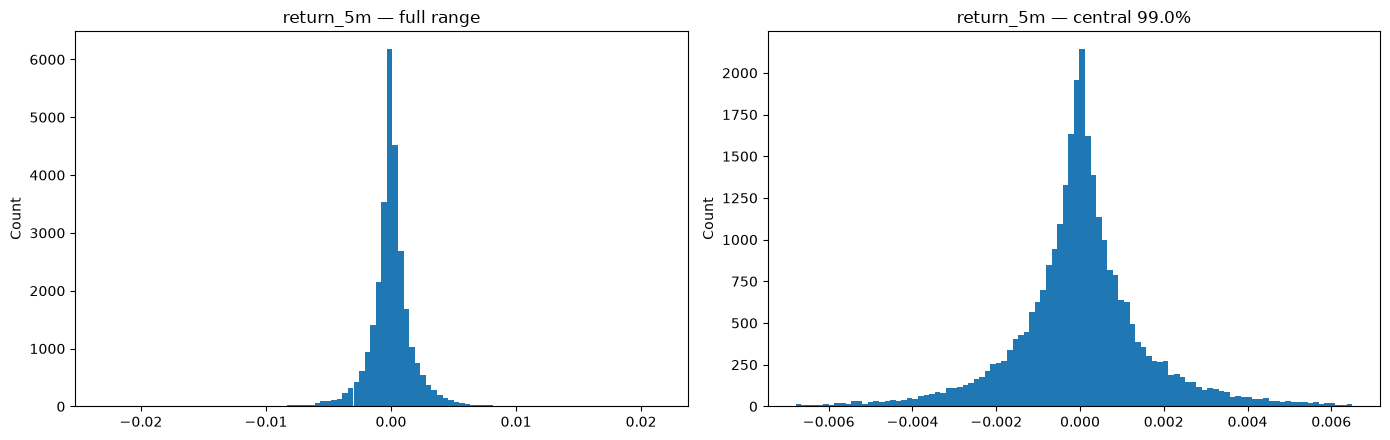

n=29,139 | central bounds [-0.00679453, 0.00650467] | min=-0.0230293 | max=0.0214857


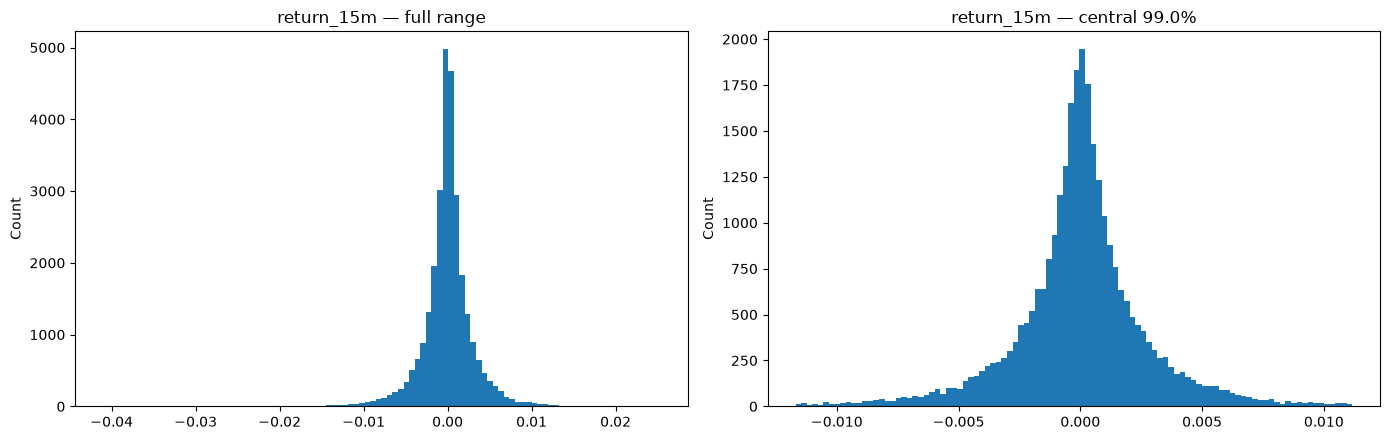

n=29,111 | central bounds [-0.0116954, 0.011163] | min=-0.0410228 | max=0.0252443


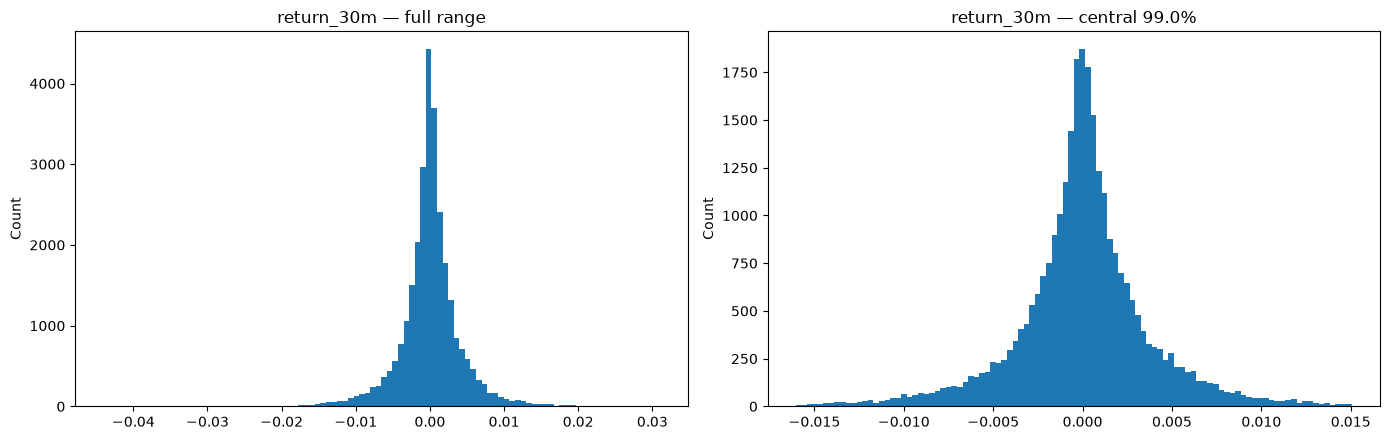

n=29,055 | central bounds [-0.0160582, 0.0150909] | min=-0.0440894 | max=0.0309864


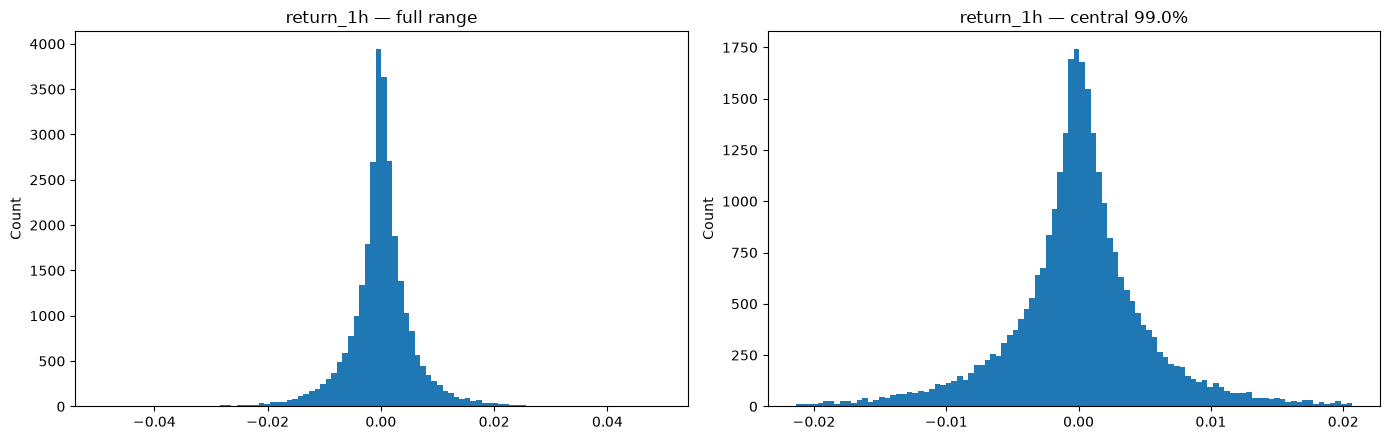

n=29,020 | central bounds [-0.0214023, 0.0208328] | min=-0.0490577 | max=0.0492246


In [146]:
return_cols = available_groups["returns"]

return_pooled = feature_summary(features, return_cols)
return_by_asset = feature_summary(features, return_cols, group_col="underlying")

display(return_pooled)
display(return_by_asset)

for col in return_cols:
    plot_full_and_central(features, col)

## 7. Per-asset return shape and empirical CDF

Pooled returns can hide substantial differences between BTC, ETH, and smaller underlyings. The ECDF provides a distribution comparison that does not depend on histogram bin choices.

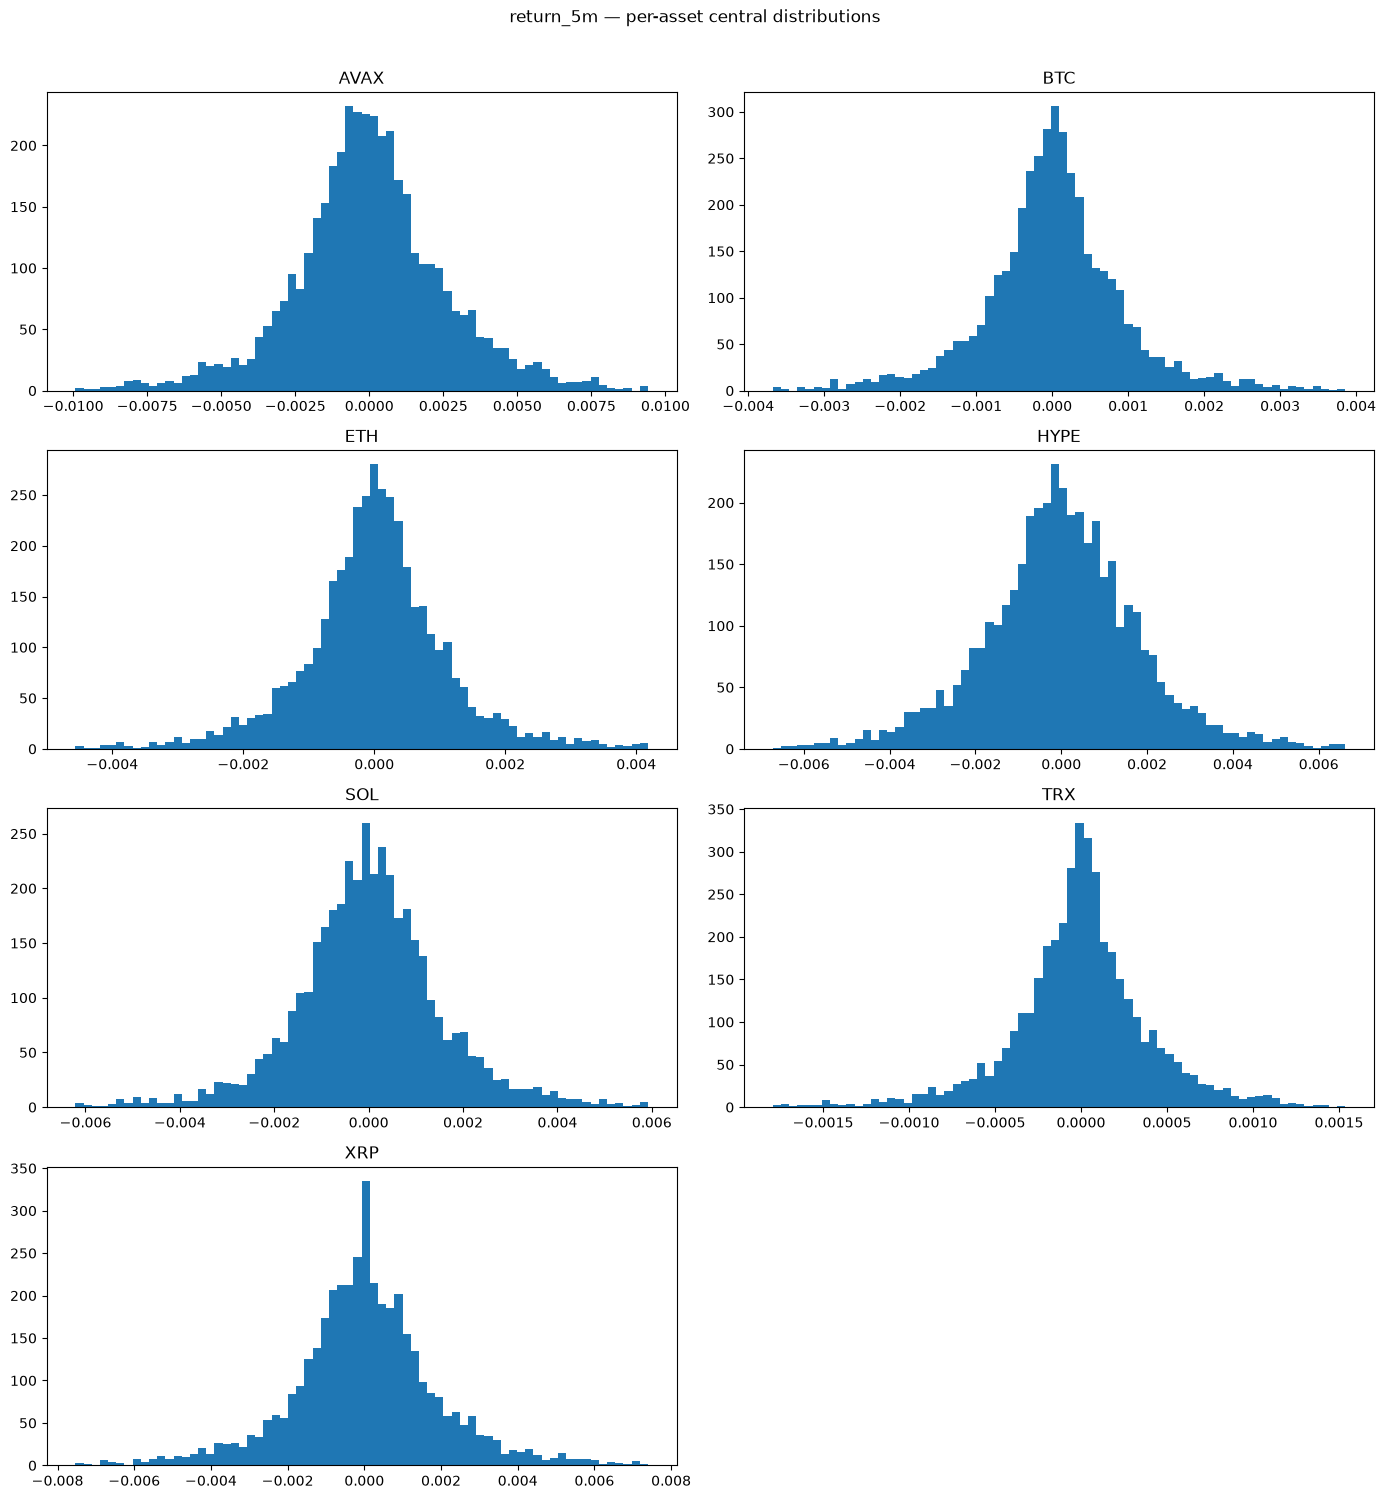

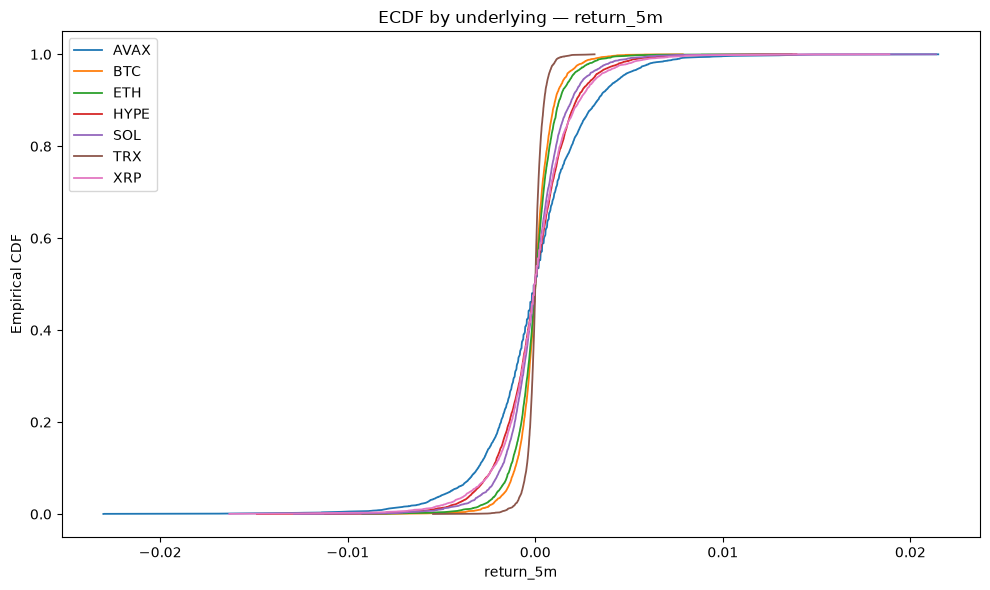

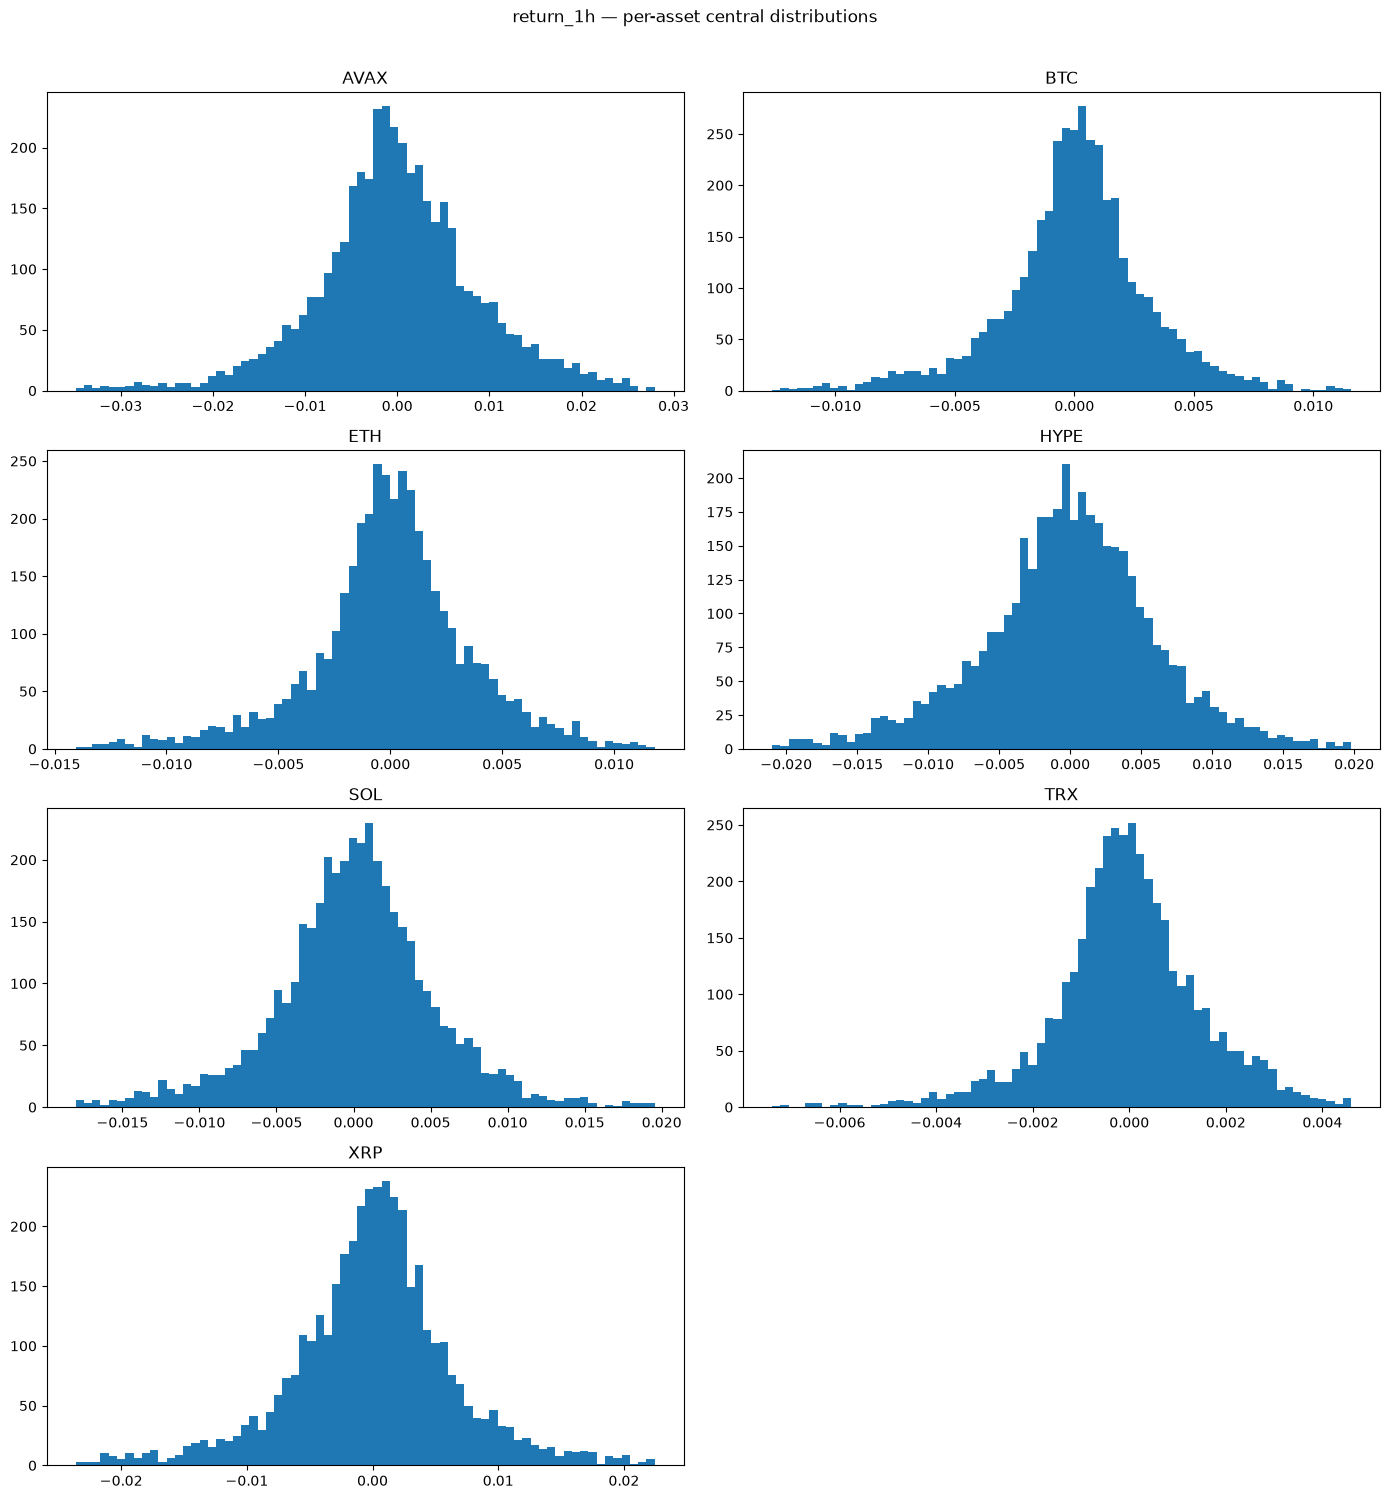

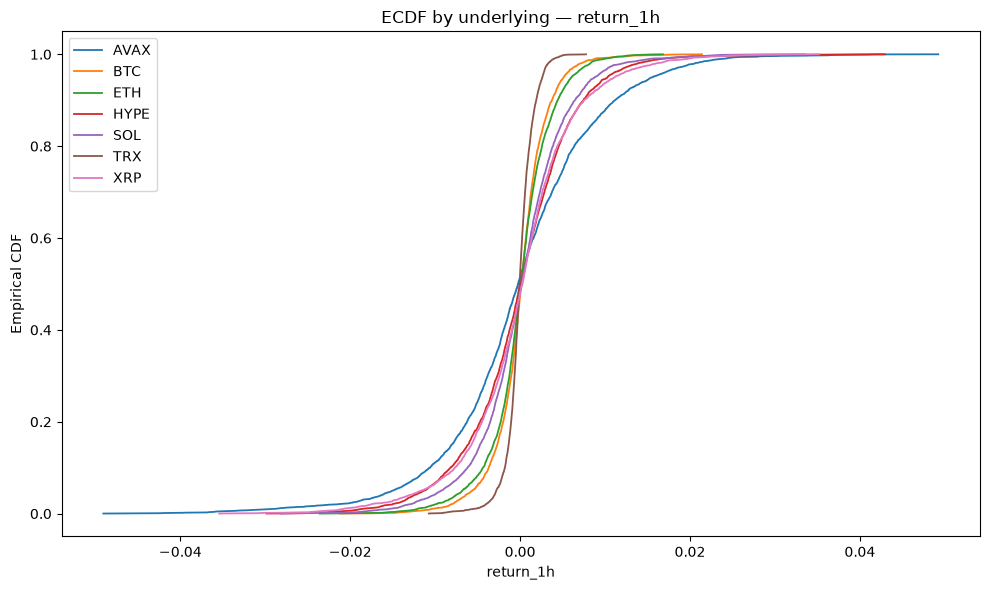

In [147]:
if "return_5m" in features.columns:
    plot_asset_histograms(features, "return_5m")
    plot_ecdf_by_asset(features, "return_5m")

if "return_1h" in features.columns:
    plot_asset_histograms(features, "return_1h")
    plot_ecdf_by_asset(features, "return_1h")

## 8. Absolute-return tails

For structural-regime research, the magnitude process can be as important as the signed return itself.

This section compares absolute 5-minute returns by underlying and lists the largest observed events without removing them.

In [148]:
if "return_5m" in features.columns:
    abs_return_rows = []

    for asset, group in features.groupby("underlying"):
        s = clean_numeric(group, "return_5m").abs()
        if s.empty:
            continue

        q = s.quantile([0.50, 0.90, 0.95, 0.99, 0.999])

        abs_return_rows.append({
            "underlying": asset,
            "n": len(s),
            "median_abs_return": q.loc[0.50],
            "q90_abs_return": q.loc[0.90],
            "q95_abs_return": q.loc[0.95],
            "q99_abs_return": q.loc[0.99],
            "q999_abs_return": q.loc[0.999],
            "max_abs_return": s.max(),
        })

    display(pd.DataFrame(abs_return_rows).sort_values("q99_abs_return", ascending=False))

    print("Largest absolute 5-minute returns:")
    display(contextual_extremes(features, "return_5m", n=25, absolute=True))

,underlying,n,median_abs_return,q90_abs_return,q95_abs_return,q99_abs_return,q999_abs_return,max_abs_return
0,AVAX,4163,0.001428,0.004538,0.005799,0.009924,0.017939,0.023029
6,XRP,4163,0.001004,0.003358,0.004447,0.007492,0.015201,0.018879
3,HYPE,4163,0.001070,0.003175,0.004103,0.006643,0.010827,0.014843
4,SOL,4163,0.000873,0.002629,0.003580,0.006060,0.011528,0.021375
2,ETH,4163,0.000578,0.001942,0.002610,0.004404,0.008562,0.013667
1,BTC,4163,0.000462,0.001578,0.002196,0.003714,0.006935,0.011205
5,TRX,4161,0.000201,0.000698,0.000947,0.001719,0.002974,0.005450


Largest absolute 5-minute returns:


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps
0,AVAX|2026-09-21T17:55:00Z,2026-09-21 17:55:00+00:00,AVAX,2026-09-22,845,-0.014510,1.669168,1.291605e+05,-0.106806,1.851338,-6.475486,NaN,NaN
1,AVAX|2026-09-23T03:50:00Z,2026-09-23 03:50:00+00:00,AVAX,2026-09-23,250,-0.014280,1.499779,6.064122e+04,-0.342003,5.357621,4.466679,0.321311,4.317502
2,AVAX|2026-09-23T12:05:00Z,2026-09-23 12:05:00+00:00,AVAX,2026-09-24,1195,-0.023029,2.397823,5.771174e+05,-0.050456,5.522319,4.604052,0.453480,11.740181
3,AVAX|2026-09-23T14:15:00Z,2026-09-23 14:15:00+00:00,AVAX,2026-09-24,1065,-0.016858,NaN,5.705784e+05,-0.322056,274.875271,146.131805,0.654582,66.176412
4,XRP|2026-09-23T14:15:00Z,2026-09-23 14:15:00+00:00,XRP,2026-09-24,1065,-0.016179,NaN,2.537395e+06,-0.053173,5.196155,4.548704,0.007671,7.154034
5,XRP|2026-09-23T14:20:00Z,2026-09-23 14:20:00+00:00,XRP,2026-09-24,1060,-0.016313,NaN,5.666636e+05,0.115584,3.302183,0.990753,0.051252,5.845055
6,HYPE|2026-09-24T07:35:00Z,2026-09-24 07:35:00+00:00,HYPE,2026-09-24,25,0.013925,1.394862,2.734572e+05,0.388283,5.401942,4.079600,0.004959,5.345528
7,XRP|2026-09-24T14:50:00Z,2026-09-24 14:50:00+00:00,XRP,2026-09-25,1030,-0.013861,1.652901,2.685651e+05,-0.194641,4.005608,3.339121,0.083320,3.828006
8,SOL|2026-09-25T11:10:00Z,2026-09-25 11:10:00+00:00,SOL,2026-09-26,1250,0.021375,NaN,1.025624e+06,0.285443,2.945846,2.357232,0.034966,2.464989
9,AVAX|2026-09-25T12:05:00Z,2026-09-25 12:05:00+00:00,AVAX,2026-09-26,1195,0.013980,1.923918,4.818475e+04,-0.082776,1.862024,7.453648,-0.216314,3.573500


## 9. Return autocorrelation

Short-horizon return autocorrelation is checked per asset on the actual five-minute grid.

This diagnostic can later help distinguish low directional persistence, momentum-like persistence, anti-persistence / mean-reversion signatures, and microstructure effects. It is **not** yet a regime label.

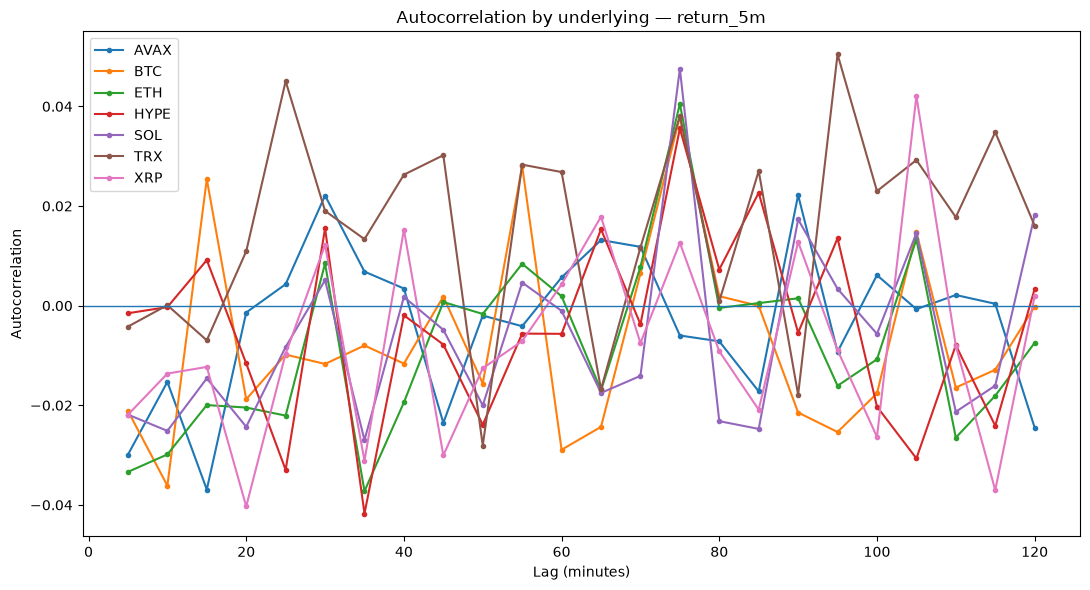

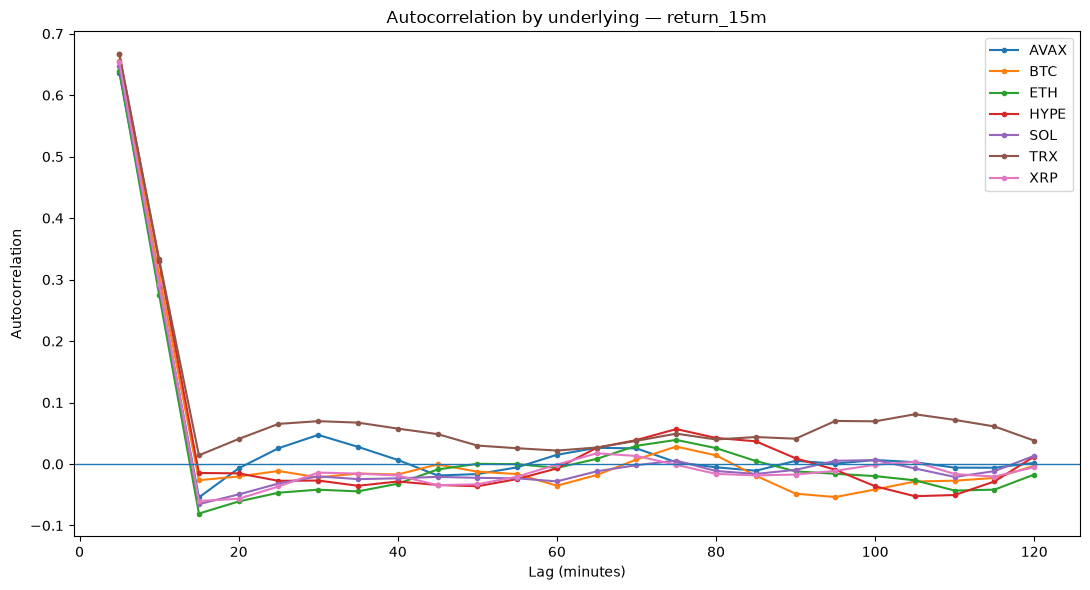

,underlying,feature,lag,lag_minutes,n_pairs,acf
0,AVAX,return_5m,1,5,4104,-0.029897
1,AVAX,return_5m,2,10,4049,-0.015306
2,AVAX,return_5m,3,15,4051,-0.036911
3,AVAX,return_5m,4,20,4051,-0.001376
4,AVAX,return_5m,5,25,4047,0.004307
5,AVAX,return_5m,6,30,4042,0.022106
6,AVAX,return_5m,7,35,4040,0.006833
7,AVAX,return_5m,8,40,4038,0.003441
8,AVAX,return_5m,9,45,4038,-0.023531
9,AVAX,return_5m,10,50,4042,-0.001988


In [149]:
return_acf = {}

for col in [c for c in ["return_5m", "return_15m"] if c in features.columns]:
    return_acf[col] = plot_acf_by_asset(features, col, max_lag=24)

if "return_5m" in return_acf:
    display(return_acf["return_5m"].head(30))

# Part B — Realized Volatility

## 10. Realized-volatility distributions and effective sample size

Realized volatility is right-skewed by construction and its horizons have different readiness requirements. Sample size is therefore reported alongside every comparison.

Both raw-window and annualized forms are retained. Annualization changes scale, not information content.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,realized_vol_30m,27286,20.383987,0.003469,0.002827,2.088106,7.553154,0.000016,0.000150,0.000314,0.000581,0.002734,0.008770,0.013719,0.023208,0.026608
1,ALL,realized_vol_1h,25460,25.711951,0.005055,0.003744,1.596084,3.851035,0.000162,0.000325,0.000585,0.000959,0.004088,0.011922,0.018003,0.026923,0.028518
2,ALL,realized_vol_4h,17514,48.897059,0.010356,0.006793,1.042674,1.012942,0.000699,0.000743,0.001550,0.002206,0.008799,0.023810,0.031062,0.038078,0.040345
3,ALL,realized_vol_30m_annualized,27286,20.383987,0.459157,0.374180,2.088106,7.553154,0.002098,0.019807,0.041536,0.076876,0.361866,1.160869,1.815938,3.071883,3.521867
4,ALL,realized_vol_1h_annualized,25460,25.711951,0.473125,0.350401,1.596084,3.851035,0.015175,0.030445,0.054776,0.089718,0.382632,1.115850,1.685026,2.519842,2.669111
5,ALL,realized_vol_4h_annualized,17514,48.897059,0.484639,0.317875,1.042674,1.012942,0.032725,0.034757,0.072550,0.103236,0.411790,1.114265,1.453640,1.781932,1.888051


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,realized_vol_30m,3899,20.363562,0.006161,0.003608,1.704833,4.773054,0.000594,0.000796,0.001298,0.001848,0.005461,0.012778,0.019427,0.026006,0.026608
1,AVAX,realized_vol_1h,3639,25.674020,0.009021,0.004519,1.201737,2.021550,0.001556,0.001621,0.002115,0.003166,0.008247,0.017945,0.024545,0.027942,0.028518
2,AVAX,realized_vol_4h,2509,48.754085,0.018593,0.007277,0.367272,-0.338640,0.005054,0.005085,0.005456,0.006474,0.017730,0.031514,0.034399,0.040219,0.040345
3,AVAX,realized_vol_30m_annualized,3899,20.363562,0.815515,0.477536,1.704833,4.773054,0.078577,0.105415,0.171840,0.244666,0.722893,1.691352,2.571427,3.442181,3.521867
4,AVAX,realized_vol_1h_annualized,3639,25.674020,0.844315,0.422982,1.201737,2.021550,0.145587,0.151743,0.197974,0.296367,0.771906,1.679551,2.297254,2.615200,2.669111
5,AVAX,realized_vol_4h_annualized,2509,48.754085,0.870084,0.340534,0.367272,-0.338640,0.236509,0.237943,0.255348,0.302973,0.829720,1.474791,1.609787,1.882157,1.888051
6,BTC,realized_vol_30m,3899,20.363562,0.002112,0.001450,2.058465,6.859204,0.000016,0.000124,0.000308,0.000523,0.001749,0.004901,0.007385,0.011650,0.011740
7,BTC,realized_vol_1h,3639,25.674020,0.003063,0.001851,1.631942,4.115680,0.000254,0.000326,0.000548,0.000933,0.002713,0.006679,0.009905,0.013061,0.014061
8,BTC,realized_vol_4h,2509,48.754085,0.006214,0.003040,0.812540,0.736942,0.001267,0.001300,0.001591,0.002125,0.006142,0.011718,0.014580,0.018113,0.018174
9,BTC,realized_vol_30m_annualized,3899,20.363562,0.279504,0.191884,2.058465,6.859204,0.002098,0.016359,0.040767,0.069189,0.231523,0.648711,0.977485,1.542013,1.553928


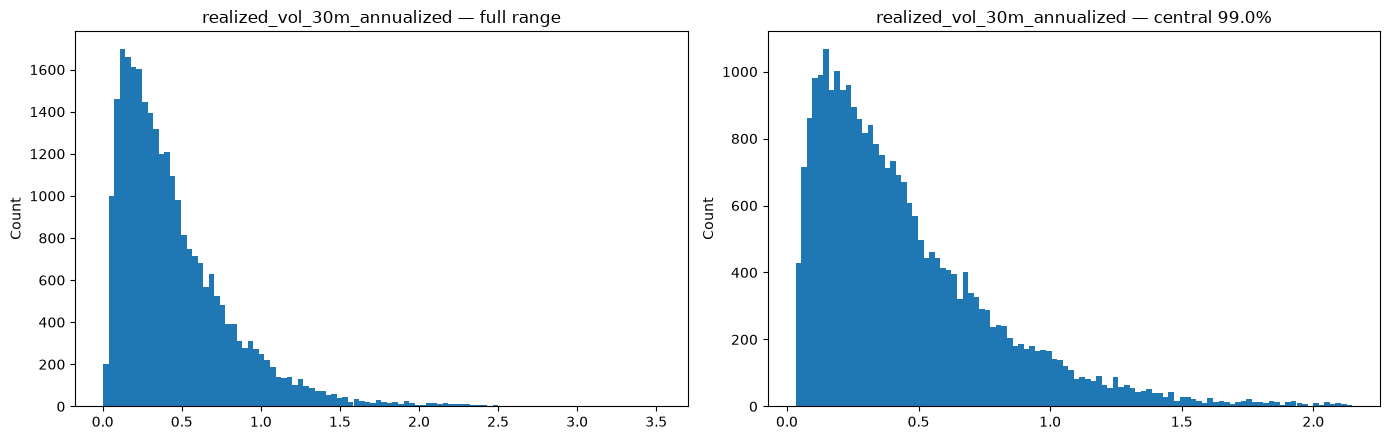

n=27,286 | central bounds [0.0325389, 2.14856] | min=0.0020979 | max=3.52187


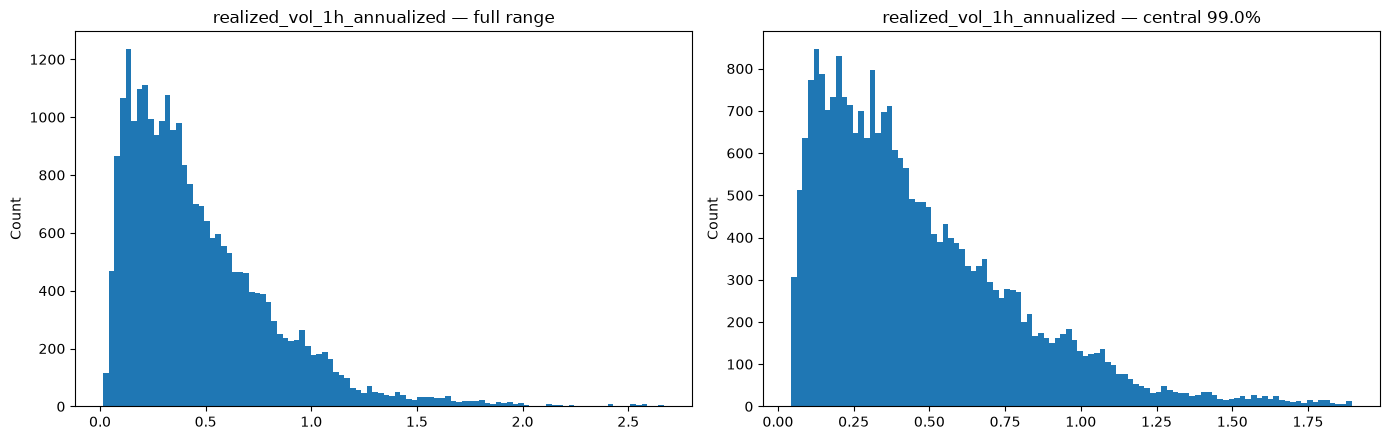

n=25,460 | central bounds [0.0436662, 1.89763] | min=0.0151746 | max=2.66911


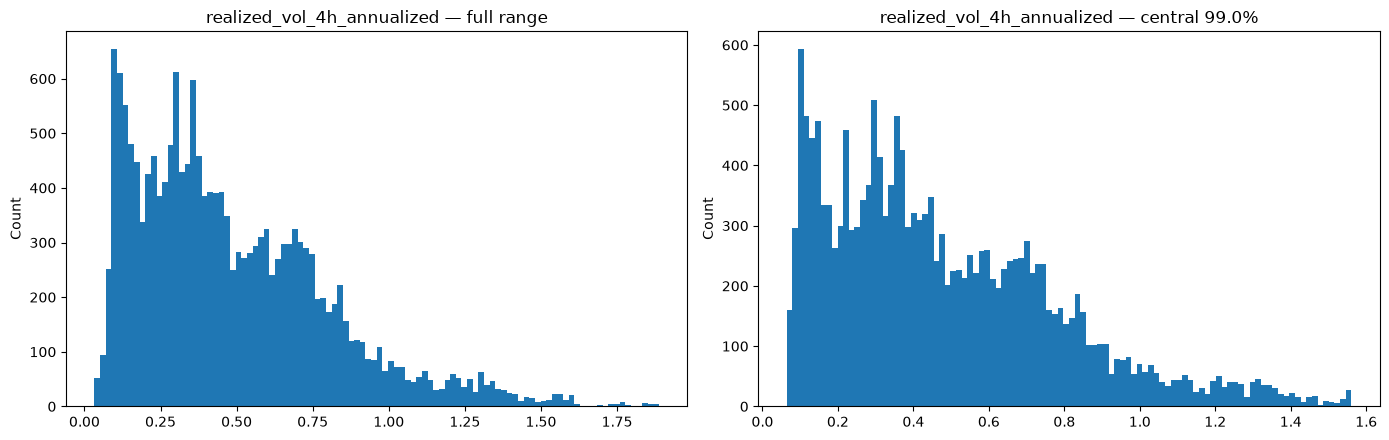

n=17,514 | central bounds [0.0643557, 1.5609] | min=0.0327255 | max=1.88805


In [150]:
rv_cols = available_groups["realized_volatility"]

rv_summary = feature_summary(features, rv_cols)
rv_by_asset = feature_summary(features, rv_cols, group_col="underlying")

display(rv_summary)
display(rv_by_asset)

for col in [
    c for c in [
        "realized_vol_30m_annualized",
        "realized_vol_1h_annualized",
        "realized_vol_4h_annualized",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

## 11. Volatility persistence

Persistent volatility is a plausible structural-state input. We therefore inspect autocorrelation independently for each underlying.

Longer-horizon realized-volatility features mechanically overlap, so high autocorrelation is expected. The question is **how persistent and how asset-dependent** it is, not whether the ACF is statistically zero.

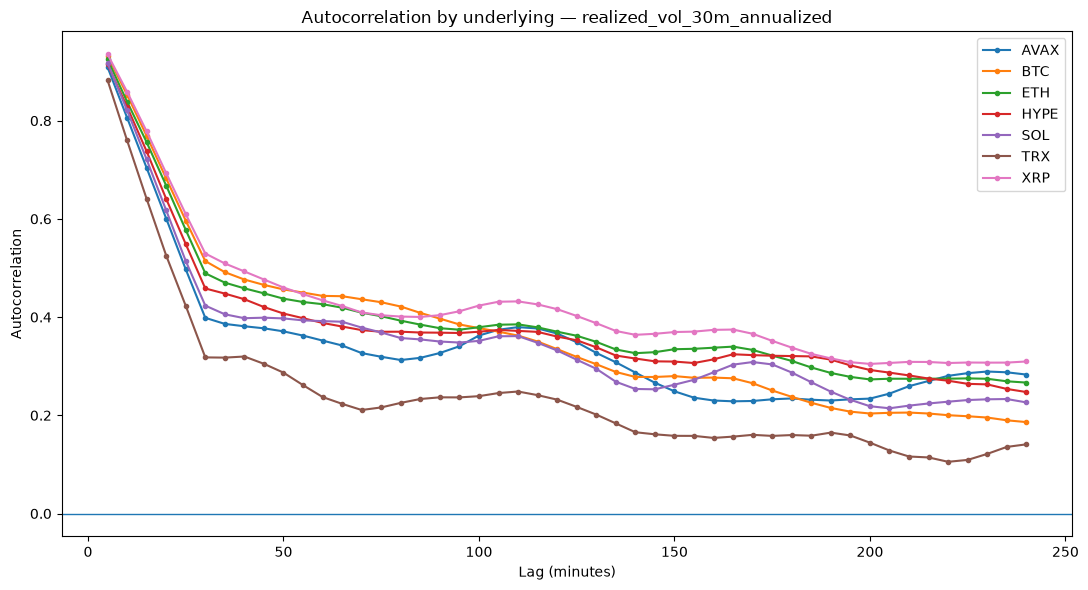

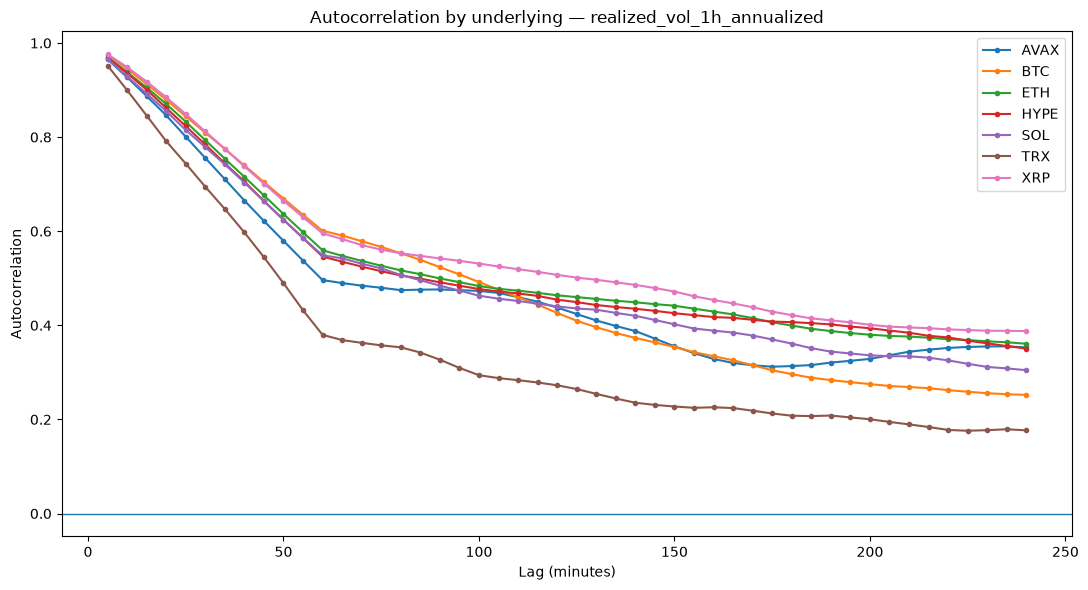

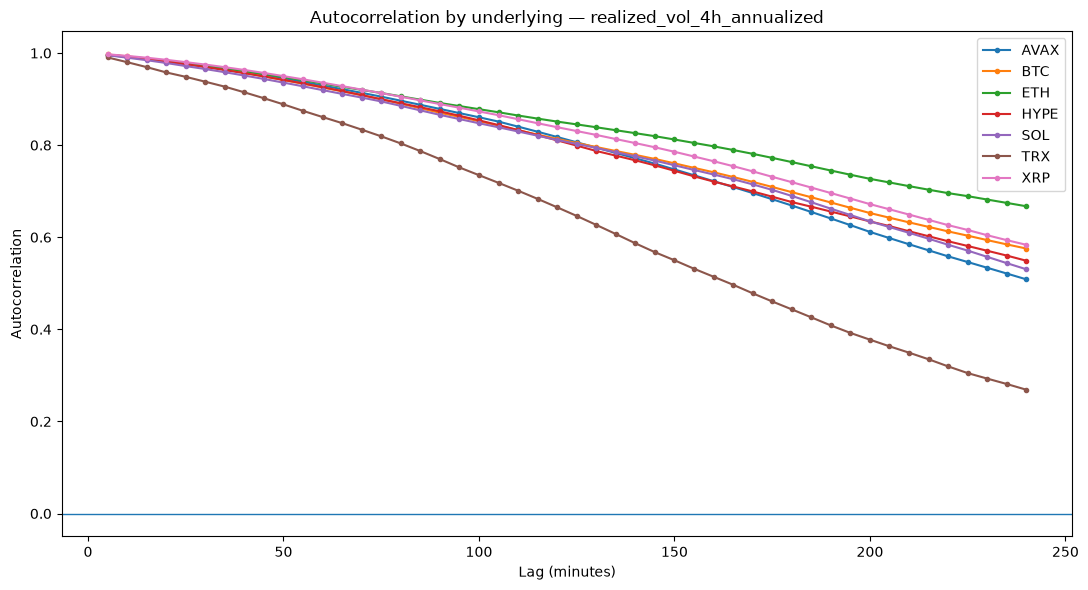

In [151]:
rv_acf = {}

for col in [
    c for c in [
        "realized_vol_30m_annualized",
        "realized_vol_1h_annualized",
        "realized_vol_4h_annualized",
    ]
    if c in features.columns
]:
    rv_acf[col] = plot_acf_by_asset(features, col, max_lag=48)

# Part C — Activity and Trade Flow

## 12. Volume, trade size, and flow distributions

The activity block contains several fundamentally different supports:

- volume and trade size are non-negative and typically long-tailed;
- signed volume is unbounded in both directions;
- trade-flow imbalance lies in `[-1, 1]`;
- buy-volume share lies in `[0, 1]`.

Boundary masses at `-1`, `0`, or `+1` are treated as real features of the data rather than as histogram artifacts.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,volume_usd,30009,12.438725,266516.251646,1.246961e+06,24.556835,1349.487408,0.000000e+00,0.000000e+00,0.000000,0.000000,14534.497099,1.153821e+06,4.893819e+06,1.362694e+07,9.611645e+07
1,ALL,log1p_volume_usd,30009,12.438725,8.539612,4.285897e+00,-0.843965,-0.193767,0.000000e+00,0.000000e+00,0.000000,0.000000,9.584349,1.395859e+01,1.540348e+01,1.642756e+01,1.838107e+01
2,ALL,signed_volume_usd,30009,12.438725,-1745.313877,2.833908e+05,-3.732406,4117.539945,-2.370535e+07,-1.271476e+06,-303538.623963,-80943.732019,0.000000,7.436457e+04,2.716971e+05,1.006228e+06,2.419578e+07
3,ALL,trade_flow_imbalance,25682,25.064192,-0.022525,6.540800e-01,0.030997,-1.069802,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,-0.006061,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
4,ALL,buy_volume_share,25682,25.064192,0.488738,3.270400e-01,0.030997,-1.069802,0.000000e+00,0.000000e+00,0.000000,0.000000,0.496970,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
5,ALL,average_trade_size_usd,25682,25.064192,1269.786805,8.513246e+03,68.897366,5574.467240,1.019400e-02,3.879473e-01,1.706728,11.921890,627.504007,3.740425e+03,6.949732e+03,2.238300e+04,8.202439e+05
6,ALL,trade_count,30009,12.438725,191.043754,3.793085e+02,5.242232,48.263166,0.000000e+00,0.000000e+00,0.000000,0.000000,35.000000,8.236000e+02,1.740840e+03,3.961696e+03,8.420000e+03


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,volume_usd,4287,12.438725,1.577984e+04,3.396464e+04,9.544741,136.325379,0.000000e+00,0.000000e+00,0.000000,0.000000,6633.820621,5.679741e+04,1.290945e+05,5.569781e+05,6.417546e+05
1,AVAX,log1p_volume_usd,4287,12.438725,8.125527e+00,2.829125e+00,-1.863067,2.969417,0.000000e+00,0.000000e+00,0.000000,0.000000,8.800087,1.094726e+01,1.176831e+01,1.322952e+01,1.337196e+01
2,AVAX,signed_volume_usd,4287,12.438725,3.183991e+02,1.310536e+04,-0.394724,45.865405,-2.100080e+05,-8.378038e+04,-35501.748904,-15562.332433,0.000000,1.797070e+04,3.833210e+04,1.065364e+05,1.582488e+05
3,AVAX,trade_flow_imbalance,3942,19.485294,-4.450998e-03,7.188515e-01,0.006116,-1.373511,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,-0.004674,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
4,AVAX,buy_volume_share,3942,19.485294,4.977745e-01,3.594258e-01,0.006116,-1.373511,0.000000e+00,0.000000e+00,0.000000,0.000000,0.497663,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
5,AVAX,average_trade_size_usd,3942,19.485294,9.032087e+02,1.026218e+03,15.003330,435.025955,1.019400e-02,1.098423e-02,19.711684,109.176691,750.016988,2.177920e+03,3.359060e+03,1.215016e+04,3.720554e+04
6,AVAX,trade_count,4287,12.438725,2.164287e+01,3.845190e+01,6.828025,84.784681,0.000000e+00,0.000000e+00,0.000000,0.000000,9.000000,8.370000e+01,1.567000e+02,4.822840e+02,7.750000e+02
7,BTC,volume_usd,4287,12.438725,1.490128e+06,2.919960e+06,11.672948,288.236050,0.000000e+00,0.000000e+00,17293.389303,53270.384727,666048.199430,5.871952e+06,1.103173e+07,2.813710e+07,9.611645e+07
8,BTC,log1p_volume_usd,4287,12.438725,1.332447e+01,1.477895e+00,-1.312957,9.545979,0.000000e+00,0.000000e+00,9.758102,10.883148,13.409119,1.558570e+01,1.621626e+01,1.715101e+01,1.838107e+01
9,BTC,signed_volume_usd,4287,12.438725,-5.451154e+03,6.308341e+05,0.811965,1006.291388,-2.370535e+07,-3.035221e+06,-716060.132822,-253646.195117,-110.743870,2.270855e+05,6.528621e+05,2.318220e+06,2.419578e+07


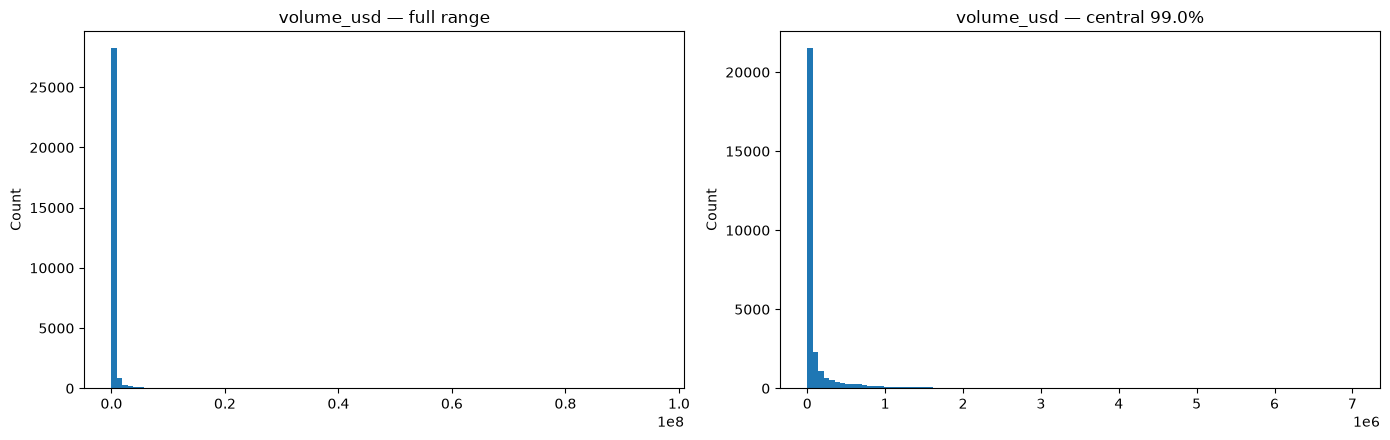

n=30,009 | central bounds [0, 7.05612e+06] | min=0 | max=9.61164e+07


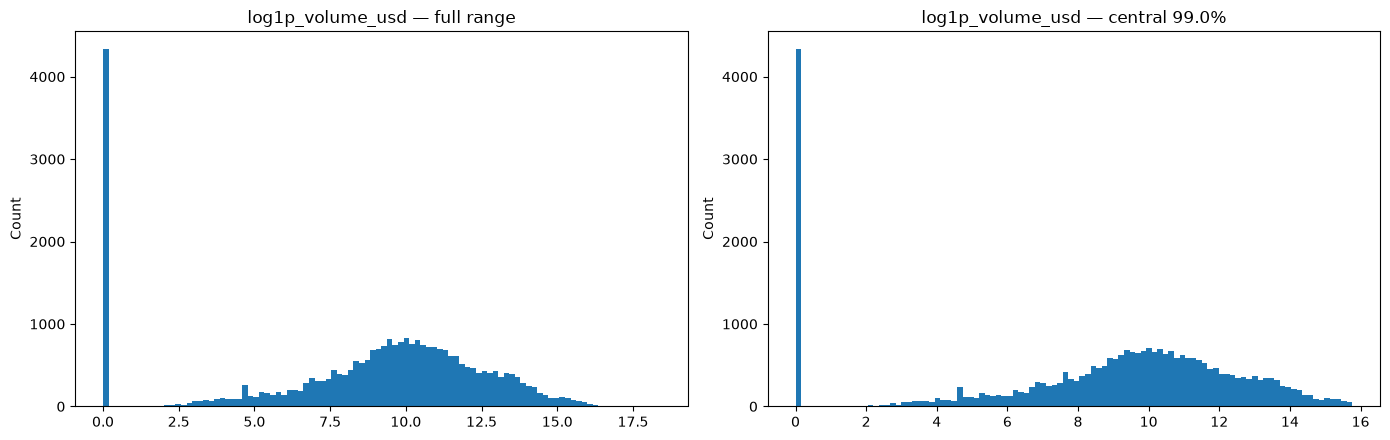

n=30,009 | central bounds [0, 15.7694] | min=0 | max=18.3811


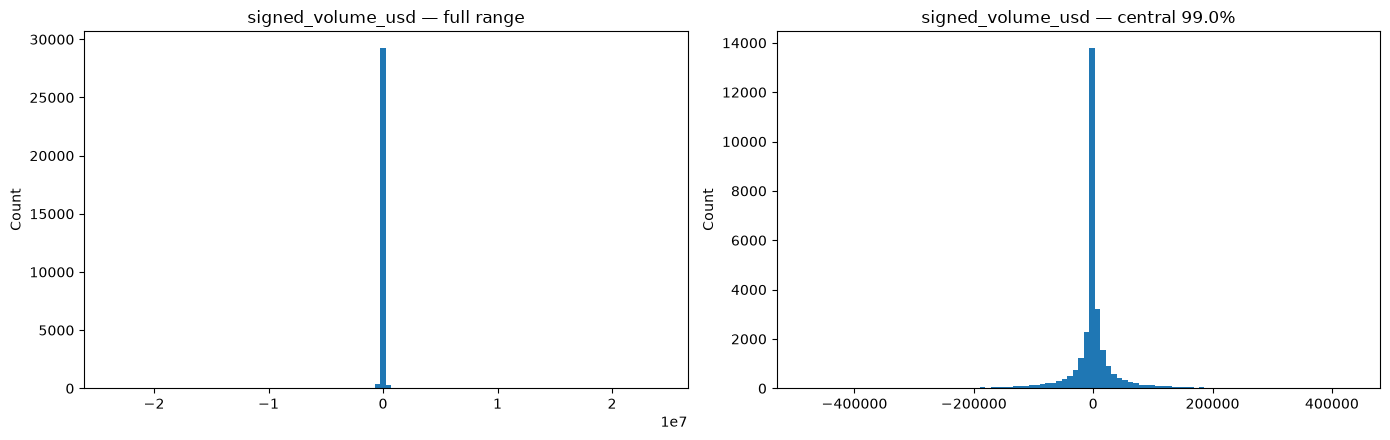

n=30,009 | central bounds [-485714, 437129] | min=-2.37054e+07 | max=2.41958e+07


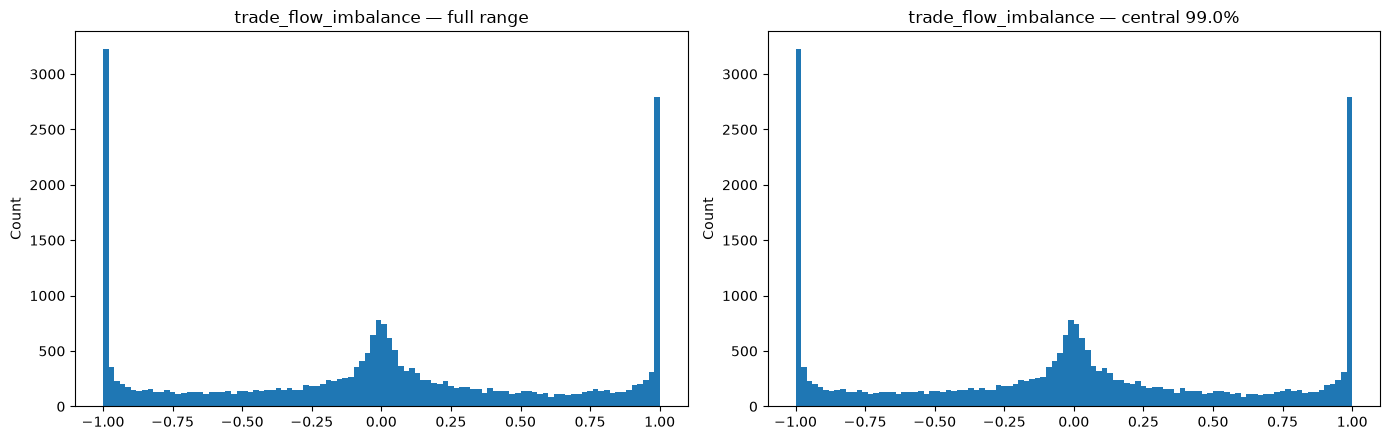

n=25,682 | central bounds [-1, 1] | min=-1 | max=1


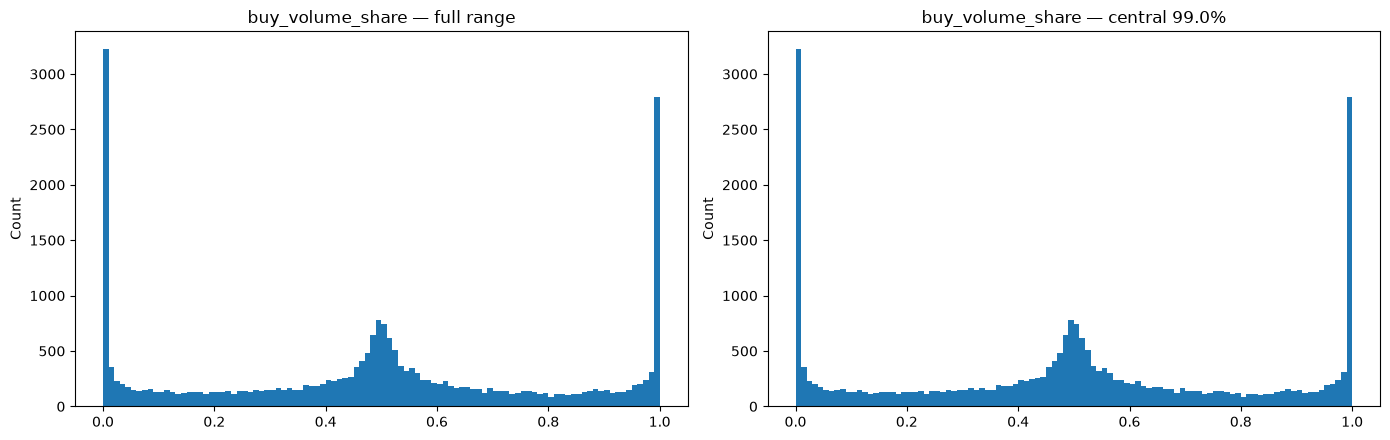

n=25,682 | central bounds [0, 1] | min=0 | max=1


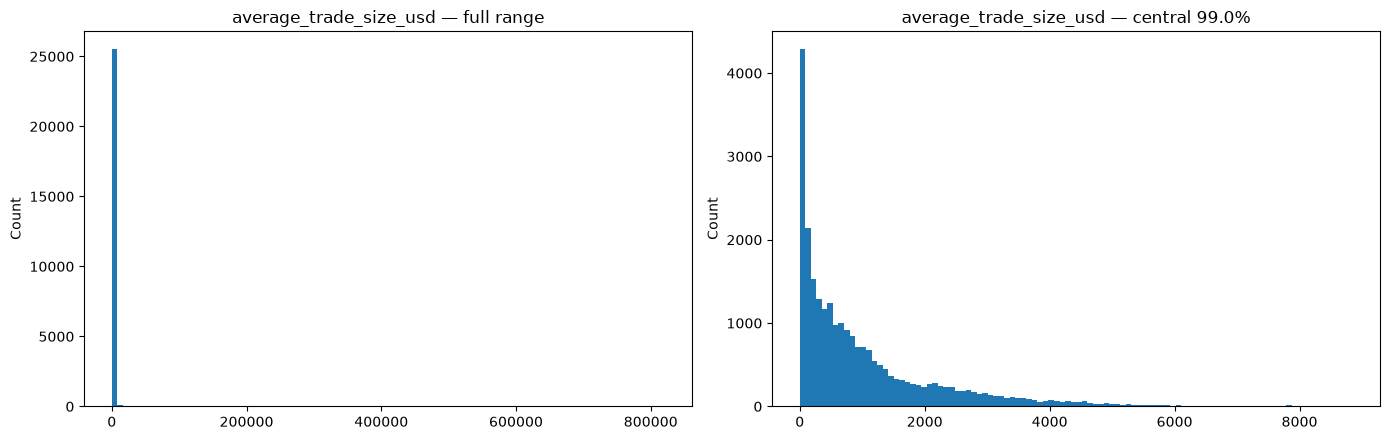

n=25,682 | central bounds [0.832798, 8854.41] | min=0.010194 | max=820244


In [152]:
activity_cols = available_groups["activity_flow"]

display(feature_summary(features, activity_cols))
display(feature_summary(features, activity_cols, group_col="underlying"))

for col in [
    c for c in [
        "volume_usd",
        "log1p_volume_usd",
        "signed_volume_usd",
        "trade_flow_imbalance",
        "buy_volume_share",
        "average_trade_size_usd",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

## 13. Structural probability masses: zero volume and ±1 flow

Extreme flow imbalance can occur when all observed aggressor flow in a window is one-sided. That is not equivalent to a smooth continuous observation close to ±1, so the endpoint mass is measured explicitly.

In [153]:
boundary_rows = []

for asset, group in features.groupby("underlying"):
    row = {"underlying": asset, "states": len(group)}

    if "volume_usd" in group.columns:
        vol = pd.to_numeric(group["volume_usd"], errors="coerce")
        valid = vol.notna()
        row["volume_valid_n"] = int(valid.sum())
        row["volume_zero_pct_of_valid"] = (
            100.0 * (vol[valid] == 0).mean() if valid.any() else np.nan
        )

    if "trade_flow_imbalance" in group.columns:
        flow = pd.to_numeric(group["trade_flow_imbalance"], errors="coerce")
        valid = flow.notna()
        row["flow_valid_n"] = int(valid.sum())
        row["flow_at_minus_1_pct"] = (
            100.0 * np.isclose(flow[valid], -1.0).mean() if valid.any() else np.nan
        )
        row["flow_at_plus_1_pct"] = (
            100.0 * np.isclose(flow[valid], 1.0).mean() if valid.any() else np.nan
        )
        row["flow_at_either_boundary_pct"] = (
            100.0
            * (
                np.isclose(flow[valid], -1.0)
                | np.isclose(flow[valid], 1.0)
            ).mean()
            if valid.any()
            else np.nan
        )

    if "buy_volume_share" in group.columns:
        share = pd.to_numeric(group["buy_volume_share"], errors="coerce")
        valid = share.notna()
        row["buy_share_zero_pct"] = (
            100.0 * np.isclose(share[valid], 0.0).mean() if valid.any() else np.nan
        )
        row["buy_share_one_pct"] = (
            100.0 * np.isclose(share[valid], 1.0).mean() if valid.any() else np.nan
        )

    boundary_rows.append(row)

boundary_mass = pd.DataFrame(boundary_rows).sort_values("underlying")
display(boundary_mass)

,underlying,states,volume_valid_n,volume_zero_pct_of_valid,flow_valid_n,flow_at_minus_1_pct,flow_at_plus_1_pct,flow_at_either_boundary_pct,buy_share_zero_pct,buy_share_one_pct
0,AVAX,4896,4287,8.047586,3942,14.358194,13.191273,27.549467,14.358194,13.242009
1,BTC,4896,4287,0.139958,4281,0.023359,0.093436,0.116795,0.023359,0.093436
2,ETH,4896,4287,0.163284,4280,0.000000,0.023364,0.023364,0.000000,0.023364
3,HYPE,4896,4287,18.381152,3499,23.149471,23.921120,47.070592,23.120892,23.921120
4,SOL,4896,4287,0.163284,4280,0.023364,0.000000,0.023364,0.023364,0.000000
5,TRX,4896,4287,67.296478,1402,55.278174,28.673324,83.951498,55.278174,28.673324
6,XRP,4896,4287,6.741311,3998,10.630315,8.829415,19.459730,10.630315,8.829415


## 14. Activity persistence

Volume and trade intensity often cluster. Flow direction may behave very differently.

That distinction matters for the later structural/noise split: a highly persistent activity state is not the same phenomenon as rapidly alternating signed flow.

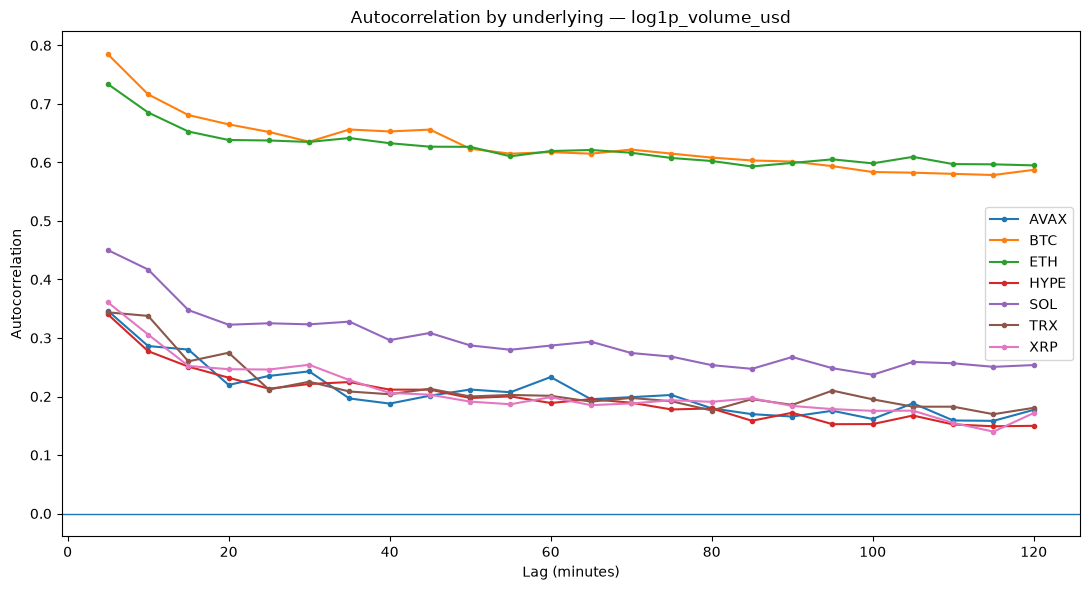

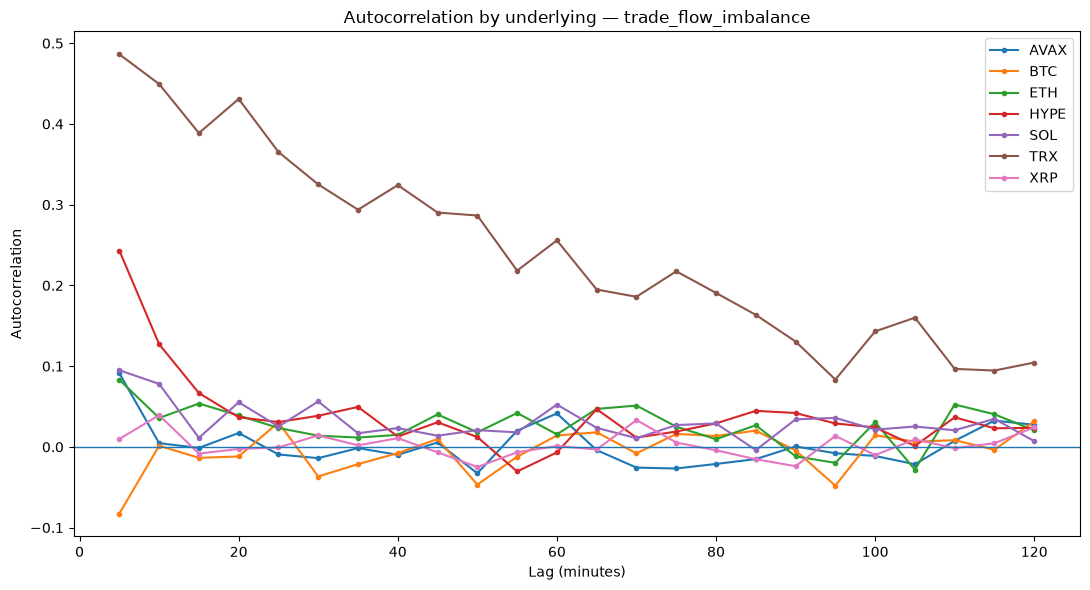

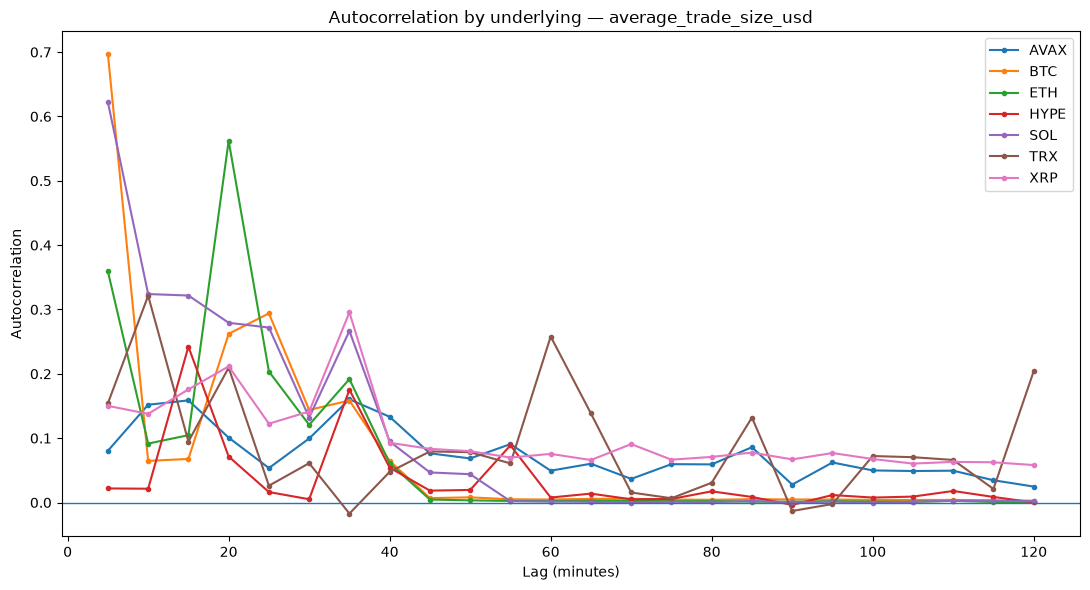

In [154]:
for col in [
    c for c in [
        "log1p_volume_usd",
        "trade_flow_imbalance",
        "average_trade_size_usd",
    ]
    if c in features.columns
]:
    plot_acf_by_asset(features, col, max_lag=24)

# Part D — Price-Bar Structure and Open Interest

## 15. Intrabar range, VWAP relation, and open-interest changes

`close_vs_vwap_bps` is the close relative to the **five-minute bar VWAP**. It is not yet the longer-horizon/session VWAP displacement envisioned for later structural research.

Open-interest changes are kept in both level-change and proportional-return form because asset scale may matter.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,intrabar_range_bps,25671,25.096289,1.874068e+01,1.918887e+01,3.540820,31.634147,0.000000,0.000000,0.000000,0.000000,14.094459,5.304435e+01,8.682881e+01,1.698327e+02,4.499671e+02
1,ALL,close_vs_vwap_bps,25682,25.064192,1.595654e-02,9.421965e+00,-0.090559,9.891039,-126.822025,-49.406891,-28.240784,-14.234770,0.000000,1.447694e+01,2.790295e+01,5.057800e+01,9.314506e+01
2,ALL,open_interest,29981,12.520425,1.243877e+06,1.986444e+06,1.650014,1.481859,436.458100,443.263666,448.015020,462.594400,223250.538000,5.793009e+06,7.064688e+06,7.139480e+06,7.154127e+06
3,ALL,open_interest_change_5m,29946,12.622549,4.734668e+01,1.250955e+04,-0.927515,2236.248891,-940726.000000,-74795.550000,-19017.552550,-1629.000000,0.000000,1.607505e+03,1.960605e+04,8.577156e+04,8.736680e+05
4,ALL,open_interest_return_5m,29946,12.622549,1.300569e-04,9.893326e-03,60.271706,4740.137353,-0.220090,-0.029120,-0.007563,-0.002421,0.000000,2.563817e-03,7.685232e-03,4.064352e-02,9.361797e-01


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,intrabar_range_bps,3941,19.505719,2.645009e+01,27.507111,3.087920,23.489375,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.981090e+01,7.464115e+01,1.195670e+02,2.101095e+02,4.499671e+02
1,AVAX,close_vs_vwap_bps,3942,19.485294,-5.412582e-02,13.437165,-0.059135,5.297785,-9.759374e+01,-6.838983e+01,-3.716566e+01,-2.186894e+01,0.000000e+00,2.134249e+01,3.735742e+01,6.320950e+01,9.314506e+01
2,AVAX,open_interest,4283,12.520425,3.484460e+05,66843.991803,0.746077,-0.971362,2.623524e+05,2.624074e+05,2.663507e+05,2.713186e+05,3.149233e+05,4.670588e+05,4.776173e+05,4.932092e+05,4.936168e+05
3,AVAX,open_interest_change_5m,4278,12.622549,-4.103275e+01,1030.284312,-2.859752,196.147673,-2.689630e+04,-6.938355e+03,-2.567759e+03,-1.156557e+03,0.000000e+00,1.004907e+03,2.724652e+03,6.632213e+03,2.215199e+04
4,AVAX,open_interest_return_5m,4278,12.622549,-9.988947e-05,0.002942,0.278425,252.318772,-6.752552e-02,-1.509091e-02,-7.192506e-03,-3.139886e-03,0.000000e+00,2.955868e-03,7.434031e-03,1.822179e-02,7.990061e-02
5,BTC,intrabar_range_bps,4279,12.602124,1.399286e+01,10.566416,2.354126,9.780695,0.000000e+00,0.000000e+00,1.126328e+00,2.953127e+00,1.162699e+01,3.275043e+01,5.587006e+01,8.025787e+01,1.234923e+02
6,BTC,close_vs_vwap_bps,4281,12.561275,-2.548718e-03,5.729912,-0.460827,7.972637,-4.804371e+01,-3.457339e+01,-1.620958e+01,-8.479046e+00,0.000000e+00,8.844960e+00,1.511855e+01,2.933476e+01,3.561547e+01
7,BTC,open_interest,4283,12.520425,8.062328e+02,486.768393,0.713551,-1.484529,4.364581e+02,4.386154e+02,4.439914e+02,4.472540e+02,4.712317e+02,1.527186e+03,1.552377e+03,1.560932e+03,1.567968e+03
8,BTC,open_interest_change_5m,4278,12.622549,2.592892e-01,12.025331,52.156068,3000.942563,-5.908330e+01,-1.577127e+01,-7.015324e+00,-1.957825e+00,3.390000e-02,2.027560e+00,5.373174e+00,2.927583e+01,7.161442e+02
9,BTC,open_interest_return_5m,4278,12.622549,3.914485e-04,0.016951,48.010416,2460.634360,-3.805527e-02,-2.676463e-02,-8.188775e-03,-2.535181e-03,5.999087e-05,2.879530e-03,6.597251e-03,2.026961e-02,9.361797e-01


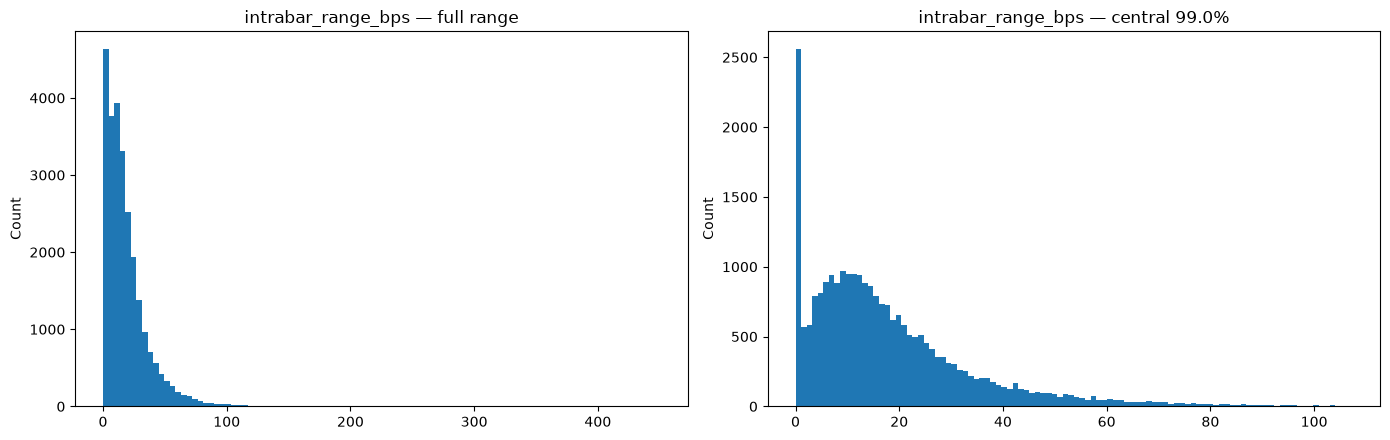

n=25,671 | central bounds [0, 107.389] | min=0 | max=449.967


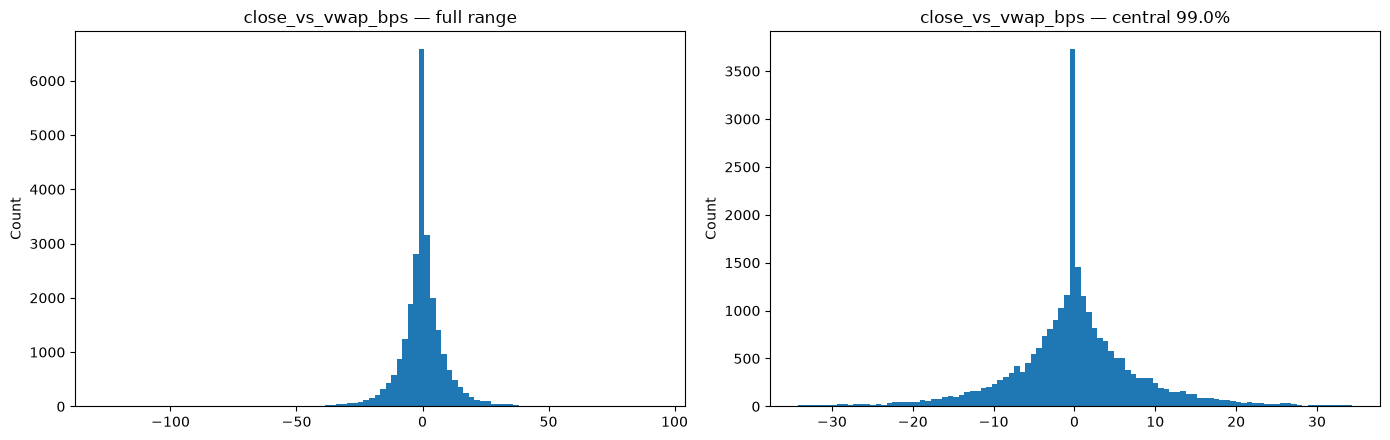

n=25,682 | central bounds [-34.3159, 34.3897] | min=-126.822 | max=93.1451


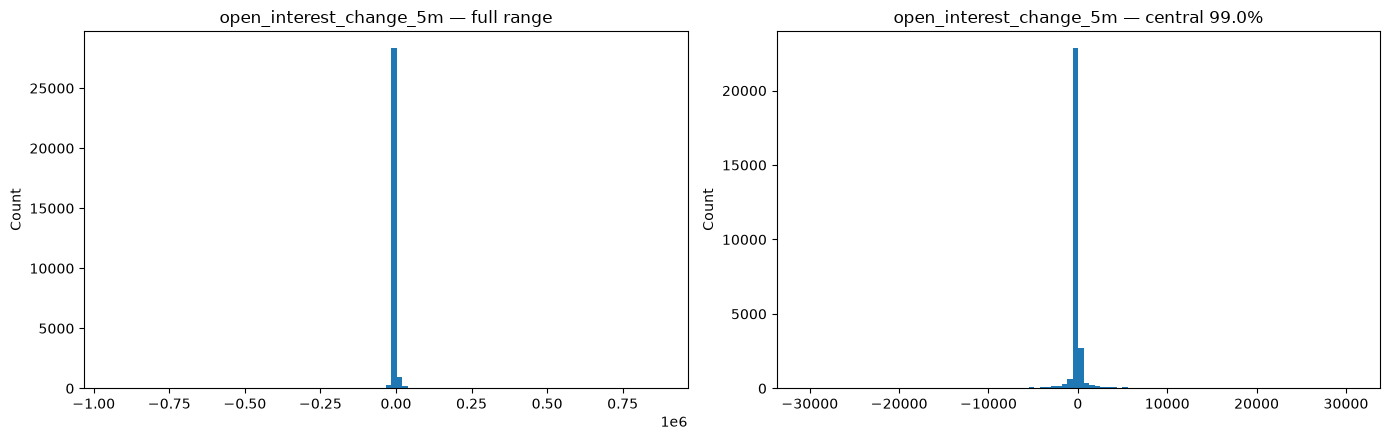

n=29,946 | central bounds [-30683, 30751.8] | min=-940726 | max=873668


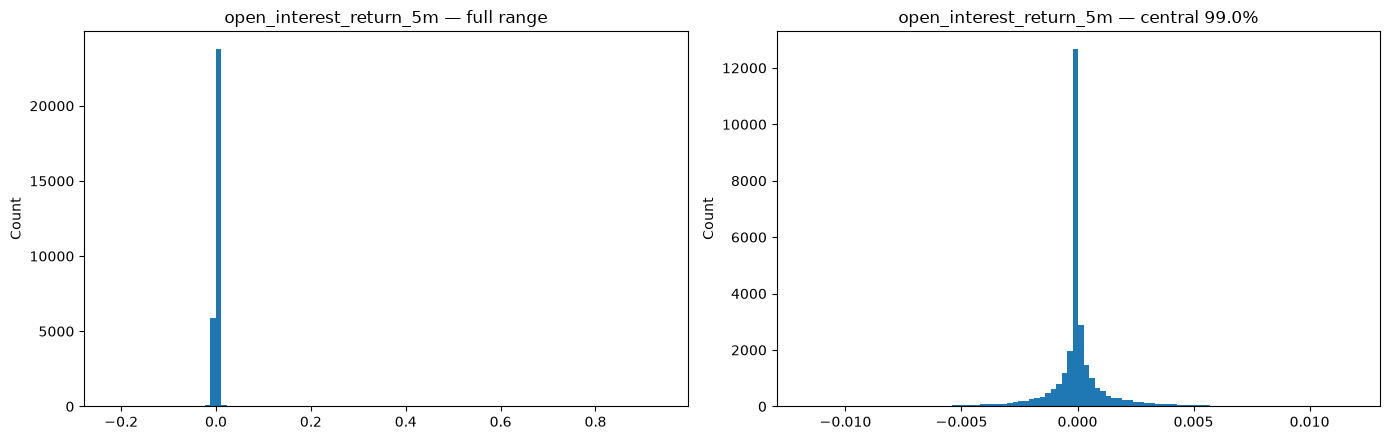

n=29,946 | central bounds [-0.011789, 0.0118675] | min=-0.22009 | max=0.93618


In [155]:
bar_oi_cols = available_groups["bar_structure_open_interest"]

display(feature_summary(features, bar_oi_cols))
display(feature_summary(features, bar_oi_cols, group_col="underlying"))

for col in [
    c for c in [
        "intrabar_range_bps",
        "close_vs_vwap_bps",
        "open_interest_change_5m",
        "open_interest_return_5m",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

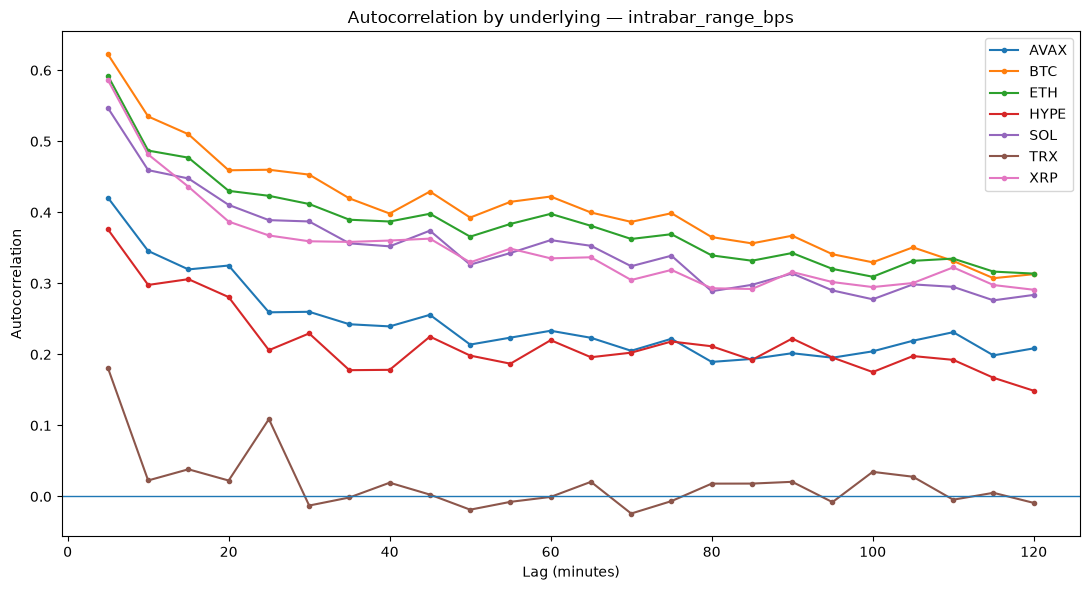

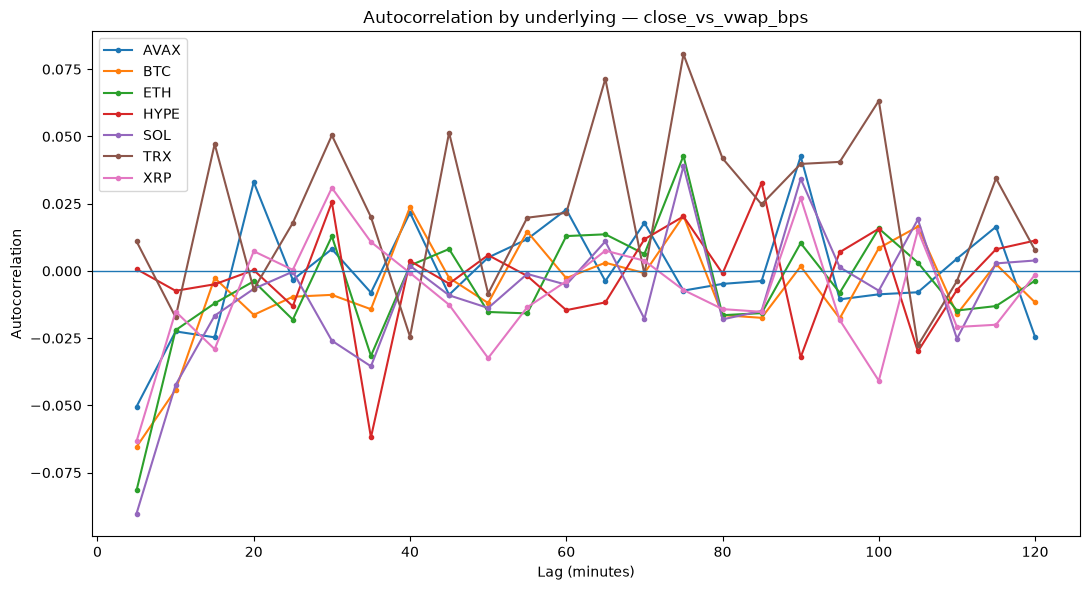

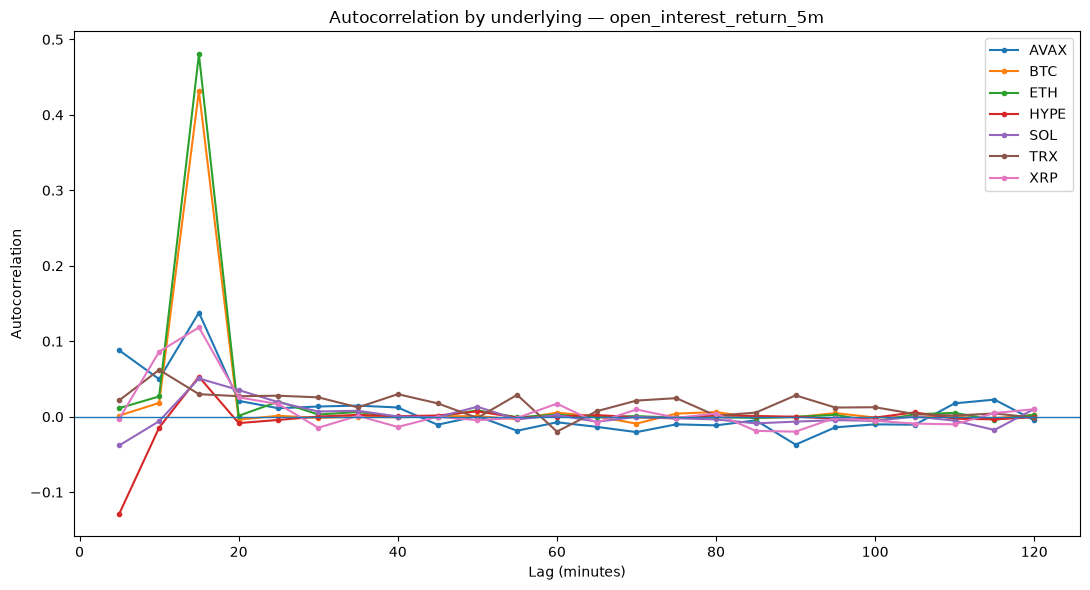

In [156]:
for col in [
    c for c in [
        "intrabar_range_bps",
        "close_vs_vwap_bps",
        "open_interest_return_5m",
    ]
    if c in features.columns
]:
    plot_acf_by_asset(features, col, max_lag=24)

# Part E — Basis, Spread, and Microprice

## 16. Distribution diagnostics

Notebook 01 exposed unusually large maxima in several spread/basis features relative to their ordinary quantiles. Here the goal is to determine whether these are concentrated in one asset, concentrated near particular session times, associated with high volatility / volume, associated with wider L2 spreads, or isolated observations versus repeated episodes.

No observation is deleted in this notebook.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,futures_spread_bps,29981,12.520425,2.471917,18.993398,59.714646,5633.380195,0.011464,0.011521,0.011580,0.011791,0.926023,5.852714,7.772381,328.927522,2139.637859
1,ALL,perpetual_mid_vs_index_bps,29981,12.520425,2.624136,8.367753,67.351736,7331.355304,-87.965324,-23.788700,-5.858160,-2.445921,2.581755,7.226396,10.253291,40.695096,1012.713340
2,ALL,perpetual_mark_vs_index_bps,29981,12.520425,2.529039,4.296872,22.695408,1294.607779,-91.281294,-9.565902,-5.366720,-2.026566,2.645783,6.813906,9.352811,13.424363,249.983155
3,ALL,microprice_vs_mid_bps,28105,17.994281,0.038919,4.357233,-11.080558,1391.109692,-265.592681,-31.196512,-2.638827,-1.382886,0.000413,1.770762,3.007851,20.488716,235.272364
4,ALL,book_twa_spread_bps,28105,17.994281,2.420624,14.836468,30.742301,1120.502178,0.011537,0.011592,0.011720,0.012491,1.249937,5.189998,6.561209,189.781676,811.677494
5,ALL,book_twa_microprice_vs_reference_bps,28105,17.994281,0.164531,10.732811,-0.745264,32.806872,-188.698792,-77.054724,-28.441723,-14.559069,0.172676,14.950773,31.118951,59.658578,166.738352


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,futures_spread_bps,4283,12.520425,3.574527,11.518642,28.287034,1064.591692,0.873324,0.885773,0.900972,0.955832,2.726653e+00,5.541446,7.504863,127.916404,520.985361
1,AVAX,perpetual_mid_vs_index_bps,4283,12.520425,2.259062,5.699184,20.868933,775.109887,-39.479587,-12.208418,-7.900190,-3.565318,2.258152e+00,7.229940,11.062695,49.816252,236.780152
2,AVAX,perpetual_mark_vs_index_bps,4283,12.520425,2.265903,4.820949,31.804684,1628.306056,-9.782125,-8.866086,-7.177364,-2.728761,1.946283e+00,6.638658,9.585783,15.698195,249.909453
3,AVAX,microprice_vs_mid_bps,4015,17.994281,0.232719,3.371943,14.346876,243.055231,-26.679118,-4.646352,-2.594474,-1.765752,7.488548e-02,1.877283,2.816373,57.233829,57.233829
4,AVAX,book_twa_spread_bps,4015,17.994281,3.464079,7.475699,17.286292,320.358667,1.152830,1.366854,1.587916,1.782451,2.905222e+00,4.579767,6.437570,127.916404,196.056469
5,AVAX,book_twa_microprice_vs_reference_bps,4015,17.994281,0.409057,16.167124,0.288423,10.164275,-132.481234,-103.497500,-40.727184,-23.610188,5.105342e-01,24.002006,50.924872,101.841261,160.264819
6,BTC,futures_spread_bps,4283,12.520425,0.187633,2.799931,18.715671,352.281548,0.011464,0.011478,0.011528,0.011565,1.183868e-02,0.056503,0.799729,53.876085,53.876085
7,BTC,perpetual_mid_vs_index_bps,4283,12.520425,2.508930,1.946253,-9.248862,159.096540,-38.192990,-27.986694,-0.682757,0.344182,2.590610e+00,4.627004,5.766210,7.413543,7.769031
8,BTC,perpetual_mark_vs_index_bps,4283,12.520425,2.585421,1.197238,-0.153558,14.309623,-11.455631,-2.302024,-0.194235,0.556616,2.671331e+00,4.302365,4.965778,5.932897,16.958739
9,BTC,microprice_vs_mid_bps,4015,17.994281,0.053477,1.021781,17.825212,329.681813,-4.132181,-2.793007,-0.182199,-0.005740,-1.095911e-04,0.005778,0.388348,19.109893,19.109893


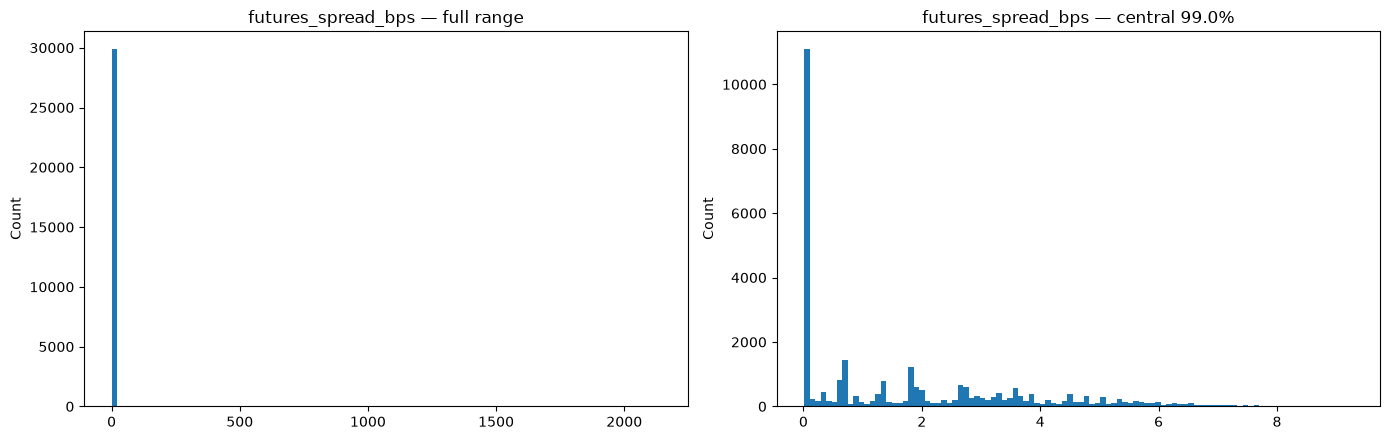

n=29,981 | central bounds [0.0115557, 9.27709] | min=0.0114645 | max=2139.64


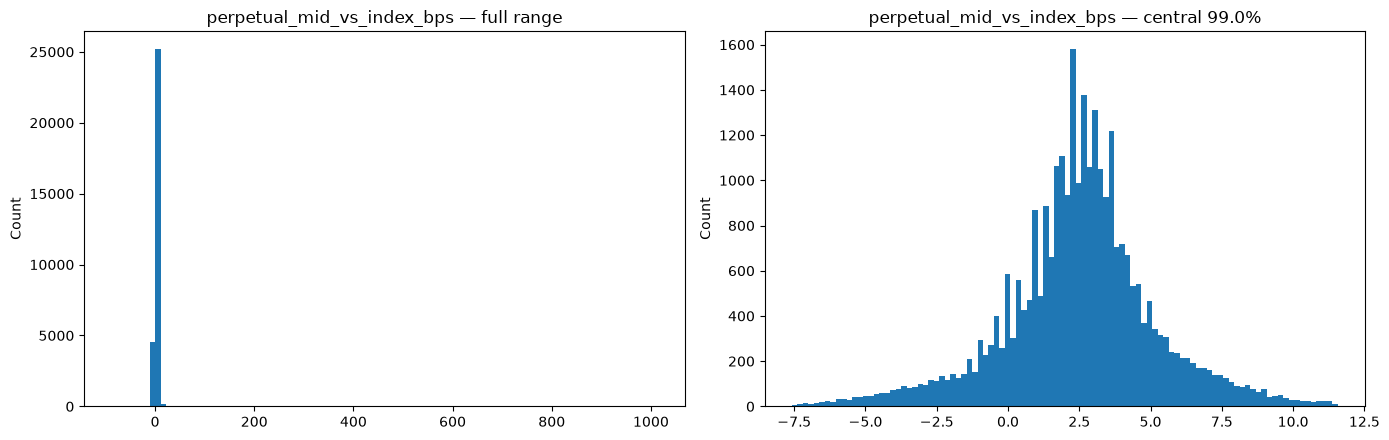

n=29,981 | central bounds [-7.57664, 11.5698] | min=-87.9653 | max=1012.71


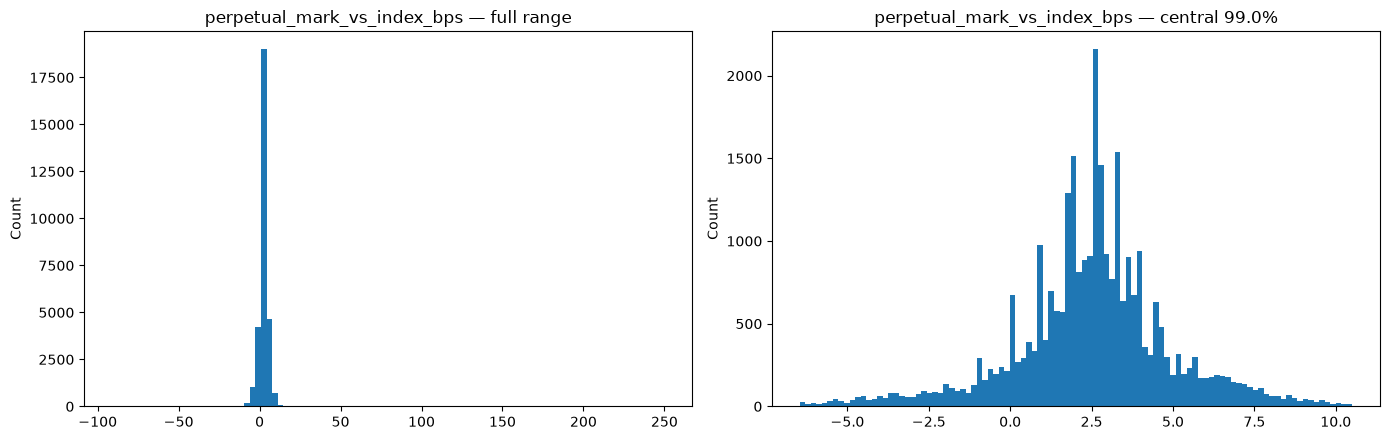

n=29,981 | central bounds [-6.46385, 10.5104] | min=-91.2813 | max=249.983


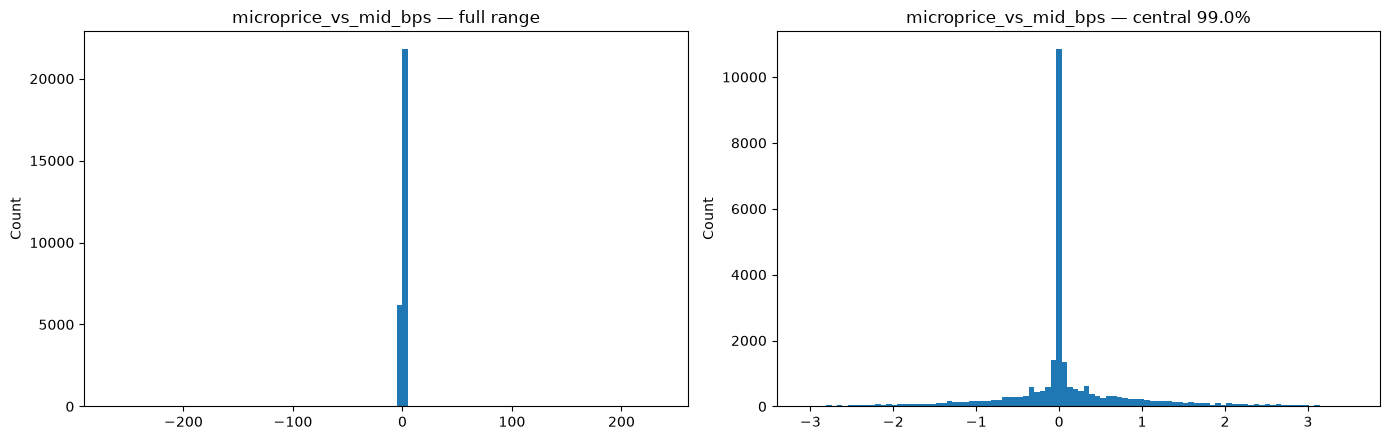

n=28,105 | central bounds [-3.07543, 3.53916] | min=-265.593 | max=235.272


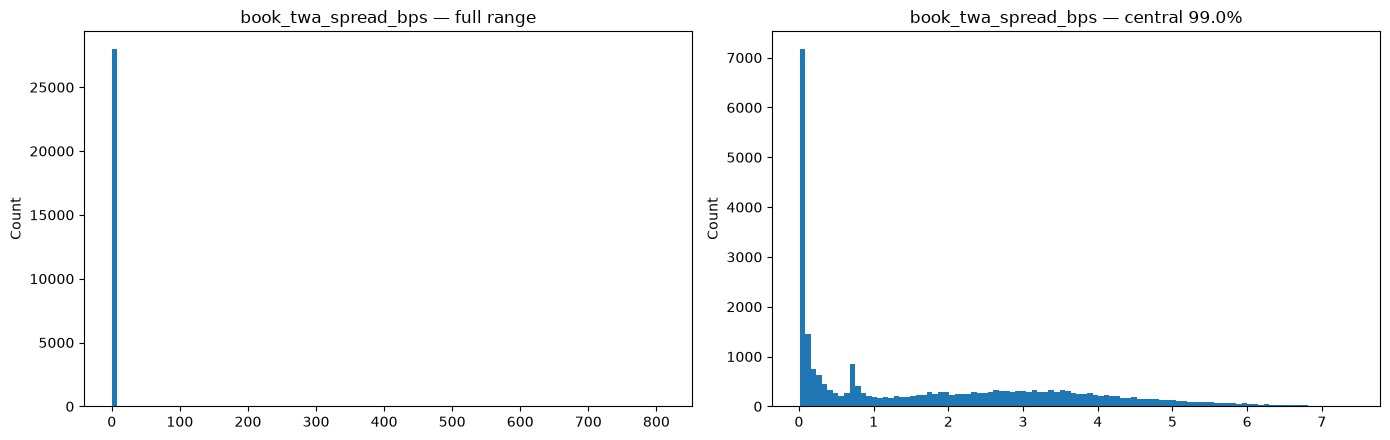

n=28,105 | central bounds [0.0116704, 7.40938] | min=0.0115369 | max=811.677


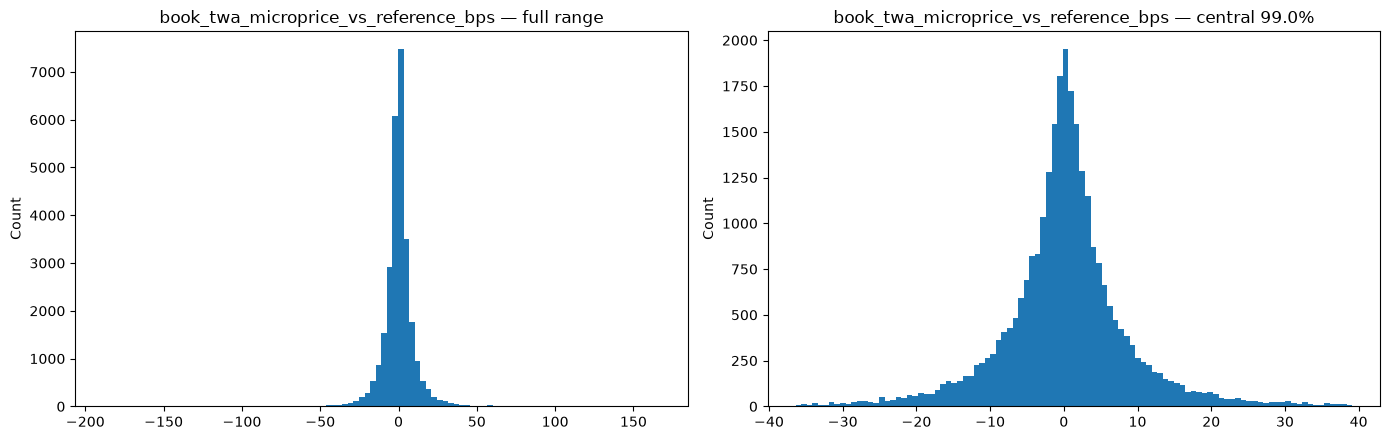

n=28,105 | central bounds [-36.478, 39.1245] | min=-188.699 | max=166.738


In [157]:
basis_cols = available_groups["basis_spread_microprice"]

display(feature_summary(features, basis_cols))
display(feature_summary(features, basis_cols, group_col="underlying"))

for col in basis_cols:
    plot_full_and_central(features, col)

## 17. Contextual tail inspection

The following tables identify the actual observations behind the tails. This is more informative than simply reporting skewness or kurtosis.

For signed basis/microprice features, both tails are shown. For non-negative spread features, the largest observations are emphasized.

In [158]:
extreme_features = [
    c for c in [
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "perpetual_mark_vs_index_bps",
        "microprice_vs_mid_bps",
        "book_twa_spread_bps",
        "book_twa_microprice_vs_reference_bps",
    ]
    if c in features.columns
]

for col in extreme_features:
    print("\n" + "=" * 110)
    print(col)
    print("=" * 110)

    if col in {"futures_spread_bps", "book_twa_spread_bps"}:
        display(contextual_extremes(features, col, n=20, absolute=True))
    else:
        display(contextual_extremes(features, col, n=12, absolute=False))


futures_spread_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,futures_spread_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps
0,AVAX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,AVAX,2026-09-22,890,520.985361,0.001994,1.077104,3.480952e+04,0.313985,236.780152,NaN,NaN
1,HYPE|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,HYPE,2026-09-22,890,337.975228,0.000741,0.616865,0.000000e+00,NaN,108.568485,NaN,NaN
2,TRX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,TRX,2026-09-22,890,2139.637859,0.000308,0.167200,0.000000e+00,NaN,1012.713340,NaN,NaN
3,XRP|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,XRP,2026-09-22,890,485.956891,0.006027,0.924819,4.653610e+04,0.957072,222.340923,NaN,NaN
4,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,620.346856,NaN,NaN,0.000000e+00,NaN,321.489381,0.204037,708.054410
5,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,523.813942,NaN,NaN,0.000000e+00,NaN,273.211482,0.387108,617.582037
6,HYPE|2026-09-28T09:30:00Z,2026-09-28 09:30:00+00:00,HYPE,2026-09-29,1350,529.528010,-0.000505,NaN,0.000000e+00,NaN,275.537107,0.492602,534.586933
7,HYPE|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,HYPE,2026-10-02,1375,328.927522,0.000966,0.598732,1.172419e+06,-0.999992,46.470384,0.015688,130.314291
8,XRP|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,XRP,2026-10-02,1375,419.589632,0.001008,0.532042,1.498562e+06,0.140236,199.193819,0.109679,32.168631
9,XRP|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,XRP,2026-10-02,1370,442.480794,0.001477,0.494881,5.102831e+04,1.000000,172.737640,0.226147,438.627035



perpetual_mid_vs_index_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,perpetual_mid_vs_index_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,book_twa_obi_20,book_twa_spread_bps,tail
0,AVAX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,AVAX,2026-09-22,890,236.780152,0.001994,1.077104,3.480952e+04,0.313985,520.985361,NaN,NaN,high
1,TRX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,TRX,2026-09-22,890,1012.713340,0.000308,0.167200,0.000000e+00,NaN,2139.637859,NaN,NaN,high
2,XRP|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,XRP,2026-09-22,890,222.340923,0.006027,0.924819,4.653610e+04,0.957072,485.956891,NaN,NaN,high
3,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,321.489381,NaN,NaN,0.000000e+00,NaN,620.346856,0.204037,708.054410,high
4,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,273.211482,NaN,NaN,0.000000e+00,NaN,523.813942,0.387108,617.582037,high
5,HYPE|2026-09-28T09:30:00Z,2026-09-28 09:30:00+00:00,HYPE,2026-09-29,1350,275.537107,-0.000505,NaN,0.000000e+00,NaN,529.528010,0.492602,534.586933,high
6,TRX|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,TRX,2026-10-02,1375,-87.965324,0.000119,0.150292,1.583659e+04,1.000000,173.782996,-0.109359,49.709454,low
7,XRP|2026-10-01T09:05:00Z,2026-10-01 09:05:00+00:00,XRP,2026-10-02,1375,199.193819,0.001008,0.532042,1.498562e+06,0.140236,419.589632,0.109679,32.168631,high
8,TRX|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,TRX,2026-10-02,1370,-74.104643,-0.001397,0.195411,0.000000e+00,NaN,173.782996,-0.297709,173.782996,low
9,XRP|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,XRP,2026-10-02,1370,172.737640,0.001477,0.494881,5.102831e+04,1.000000,442.480794,0.226147,438.627035,high



perpetual_mark_vs_index_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,perpetual_mark_vs_index_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps,tail
0,AVAX|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,AVAX,2026-09-22,890,249.909453,0.001994,1.077104,3.480952e+04,0.313985,520.985361,236.780152,NaN,NaN,high
1,ETH|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,ETH,2026-09-22,890,25.943302,0.001431,0.748849,6.035410e+03,0.391516,48.961828,4.499258,NaN,NaN,high
2,HYPE|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,HYPE,2026-09-22,890,104.006784,0.000741,0.616865,0.000000e+00,NaN,337.975228,108.568485,NaN,NaN,high
3,XRP|2026-09-21T17:10:00Z,2026-09-21 17:10:00+00:00,XRP,2026-09-22,890,162.248781,0.006027,0.924819,4.653610e+04,0.957072,485.956891,222.340923,NaN,NaN,high
4,AVAX|2026-09-23T02:45:00Z,2026-09-23 02:45:00+00:00,AVAX,2026-09-23,315,18.679950,0.003654,1.105730,6.443086e+04,0.748050,8.888889,7.116171,0.413931,11.455239,high
5,AVAX|2026-09-23T14:15:00Z,2026-09-23 14:15:00+00:00,AVAX,2026-09-24,1065,49.665712,-0.016858,NaN,5.705784e+05,-0.322056,274.875271,146.131805,0.654582,66.176412,high
6,AVAX|2026-09-25T08:00:00Z,2026-09-25 08:00:00+00:00,AVAX,2026-09-26,1440,17.621145,0.001960,1.110989,5.230248e+05,0.245428,10.753214,14.194812,0.586702,9.435160,high
7,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,199.950712,NaN,NaN,0.000000e+00,NaN,620.346856,321.489381,0.204037,708.054410,high
8,XRP|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,XRP,2026-09-29,1360,249.983155,NaN,NaN,2.853122e+03,0.931288,24.843052,35.374975,0.252832,811.677494,high
9,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,200.044853,NaN,NaN,0.000000e+00,NaN,523.813942,273.211482,0.387108,617.582037,high


... (2 outputs left out)


book_twa_spread_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,book_twa_spread_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20
0,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,708.054410,NaN,NaN,0.000000e+00,NaN,620.346856,321.489381,0.204037
1,XRP|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,XRP,2026-09-29,1360,811.677494,NaN,NaN,2.853122e+03,0.931288,24.843052,35.374975,0.252832
2,HYPE|2026-09-28T09:25:00Z,2026-09-28 09:25:00+00:00,HYPE,2026-09-29,1355,617.582037,NaN,NaN,0.000000e+00,NaN,523.813942,273.211482,0.387108
3,HYPE|2026-09-28T09:30:00Z,2026-09-28 09:30:00+00:00,HYPE,2026-09-29,1350,534.586933,-0.000505,NaN,0.000000e+00,NaN,529.528010,275.537107,0.492602
4,HYPE|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,HYPE,2026-10-02,1370,328.927522,0.002623,0.620832,3.458520e+01,1.000000,328.927522,20.151585,-0.116879
5,XRP|2026-10-01T09:10:00Z,2026-10-01 09:10:00+00:00,XRP,2026-10-02,1370,438.627035,0.001477,0.494881,5.102831e+04,1.000000,442.480794,172.737640,0.226147
6,HYPE|2026-10-01T09:15:00Z,2026-10-01 09:15:00+00:00,HYPE,2026-10-02,1365,328.927522,0.000795,0.597921,0.000000e+00,NaN,328.927522,12.193212,-0.116879
7,XRP|2026-10-01T09:15:00Z,2026-10-01 09:15:00+00:00,XRP,2026-10-02,1365,442.480794,-0.000134,0.491005,0.000000e+00,NaN,442.480794,174.102650,0.215123
8,HYPE|2026-10-01T09:20:00Z,2026-10-01 09:20:00+00:00,HYPE,2026-10-02,1360,328.927522,-0.003036,0.634071,5.409152e+06,0.383049,328.927522,42.637703,-0.116879
9,XRP|2026-10-01T09:20:00Z,2026-10-01 09:20:00+00:00,XRP,2026-10-02,1360,442.480794,-0.001007,0.499808,1.529385e+06,0.700511,442.480794,184.351914,0.215123



book_twa_microprice_vs_reference_bps


,state_id,state_time,underlying,expiry_date,minutes_to_expiry,book_twa_microprice_vs_reference_bps,return_5m,realized_vol_1h_annualized,volume_usd,trade_flow_imbalance,futures_spread_bps,perpetual_mid_vs_index_bps,book_twa_obi_20,book_twa_spread_bps,tail
0,AVAX|2026-09-23T12:05:00Z,2026-09-23 12:05:00+00:00,AVAX,2026-09-24,1195,112.425616,-0.023029,2.397823,5.771174e+05,-0.050456,5.522319,4.604052,0.453480,11.740181,high
1,XRP|2026-09-23T14:20:00Z,2026-09-23 14:20:00+00:00,XRP,2026-09-24,1060,99.812329,-0.016313,NaN,5.666636e+05,0.115584,3.302183,0.990753,0.051252,5.845055,high
2,AVAX|2026-09-23T16:00:00Z,2026-09-23 16:00:00+00:00,AVAX,2026-09-24,960,86.479851,-0.008853,1.104683,1.527662e+05,0.303910,5.862810,0.977231,0.268562,4.888375,high
3,AVAX|2026-09-24T14:50:00Z,2026-09-24 14:50:00+00:00,AVAX,2026-09-25,1030,84.442158,-0.012702,1.998065,6.401229e+04,0.119614,4.879715,-1.463700,0.227778,3.046705,high
4,XRP|2026-09-24T14:50:00Z,2026-09-24 14:50:00+00:00,XRP,2026-09-25,1030,97.071346,-0.013861,1.652901,2.685651e+05,-0.194641,4.005608,3.339121,0.083320,3.828006,high
5,AVAX|2026-09-25T14:05:00Z,2026-09-25 14:05:00+00:00,AVAX,2026-09-26,1075,102.059374,-0.018148,2.121377,1.203945e+05,-0.464963,7.826257,10.772696,0.005515,5.716745,high
6,AVAX|2026-09-27T07:25:00Z,2026-09-27 07:25:00+00:00,AVAX,2026-09-27,35,-132.481234,0.019404,1.887770,2.071317e+05,-0.041100,2.681085,1.340722,0.055873,4.565125,low
7,AVAX|2026-09-27T09:10:00Z,2026-09-27 09:10:00+00:00,AVAX,2026-09-28,1370,124.229417,-0.015366,1.937391,8.531265e+04,0.521580,4.525501,4.980531,0.216191,3.803479,high
8,HYPE|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,HYPE,2026-09-29,1360,-181.059897,NaN,NaN,0.000000e+00,NaN,620.346856,321.489381,0.204037,708.054410,low
9,TRX|2026-09-28T09:20:00Z,2026-09-28 09:20:00+00:00,TRX,2026-09-29,1360,107.231512,NaN,NaN,1.509994e+04,1.000000,62.115511,23.257693,0.686921,253.063184,high


# Part F — Standard L2 State

## 18. Persistent order-book state

This section covers the established L2 level features with sufficient history:

- time-weighted OBI at 5/10/20 levels;
- 5-minute change in deep-book imbalance;
- time-weighted depth;
- time-weighted spread / microprice.

The newer streaming instability statistics (`book_obi_20_std`, roughness, coherence noise, reversal-strength distributions, etc.) are deferred to **Notebook 04**, where their shorter history can be handled explicitly.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,book_twa_obi_5,28119,17.953431,0.020006,0.208608,0.142246,1.702265,-0.856850,-0.734960,-0.550789,-0.316475,0.012576,0.387088,0.609960,0.820251,0.915902
1,ALL,book_twa_obi_10,28119,17.953431,0.009189,0.164578,0.094526,1.308974,-0.795102,-0.551980,-0.422797,-0.268593,0.008832,0.291945,0.460034,0.627516,0.749387
2,ALL,book_twa_obi_20,28119,17.953431,-0.008504,0.155051,-0.245743,2.548373,-0.807421,-0.611076,-0.466017,-0.296945,0.002572,0.216655,0.423536,0.632578,0.714406
3,ALL,book_twa_obi_20_change_5m,28105,17.994281,-0.000063,0.075408,-0.015128,3.758163,-0.593039,-0.353195,-0.210069,-0.121926,-0.000058,0.122418,0.211344,0.336238,0.560171
4,ALL,book_twa_bid_depth_20,28119,17.953431,70080.469176,132689.015299,2.416939,5.939963,2.813166,5.001029,5.784177,6.990881,4564.352045,380741.258282,584335.812304,736698.767230,794903.501893
5,ALL,book_twa_ask_depth_20,28119,17.953431,65970.135046,120912.317110,2.236010,4.759641,1.252731,4.790411,5.629260,6.919807,4450.105587,352013.673936,535950.579692,599471.062319,712156.905807
6,ALL,book_twa_spread,28119,17.953431,0.260086,9.794140,49.694604,2556.882117,0.000010,0.000010,0.000035,0.000105,0.004416,0.168851,0.856465,9.151812,680.549612
7,ALL,book_twa_microprice,28119,17.953431,12505.110555,29456.360739,2.037938,2.162195,0.331749,0.332440,0.333735,0.335333,90.869125,84796.115176,86340.340876,86795.437442,87205.634838


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,book_twa_obi_5,4017,17.953431,0.007233,0.099630,0.697354,6.994820,-0.763327,-0.401995,-0.224320,-0.140771,0.003069,0.163207,0.281168,0.664465,0.664465
1,AVAX,book_twa_obi_10,4017,17.953431,-0.049201,0.146320,0.202064,2.408507,-0.795102,-0.517909,-0.424435,-0.308479,-0.032444,0.163340,0.440731,0.562129,0.644704
2,AVAX,book_twa_obi_20,4017,17.953431,-0.106607,0.273984,0.582520,0.041181,-0.807421,-0.657484,-0.594800,-0.485505,-0.113992,0.414987,0.619618,0.676411,0.714406
3,AVAX,book_twa_obi_20_change_5m,4015,17.994281,-0.000226,0.089304,-0.056120,3.010813,-0.565236,-0.371471,-0.248129,-0.143202,0.000000,0.144048,0.241944,0.344003,0.560171
4,AVAX,book_twa_bid_depth_20,4017,17.953431,7319.219468,3523.999422,2.785998,9.285237,100.511548,754.628000,3365.158853,4423.260631,6202.323066,13436.326094,22592.700414,25879.573361,28670.472733
5,AVAX,book_twa_ask_depth_20,4017,17.953431,9374.435803,3701.465324,0.541532,-0.603775,258.092525,1265.831000,3786.420476,4746.701252,8666.709672,16021.012943,18201.227534,20268.539086,21363.112371
6,AVAX,book_twa_spread,4017,17.953431,0.003800,0.008451,16.558879,289.693556,0.001275,0.001485,0.001743,0.001955,0.003128,0.005053,0.007222,0.142000,0.206016
7,AVAX,book_twa_microprice,4017,17.953431,10.864098,0.335739,-0.425342,-0.305416,10.001033,10.061089,10.124099,10.240427,10.954371,11.326664,11.607233,11.818235,11.943124
8,BTC,book_twa_obi_5,4017,17.953431,0.002257,0.170188,0.098750,1.228283,-0.677049,-0.600023,-0.429334,-0.275246,-0.000461,0.293592,0.443352,0.618854,0.836630
9,BTC,book_twa_obi_10,4017,17.953431,0.002588,0.156888,0.430626,1.490770,-0.576475,-0.476115,-0.350522,-0.241640,-0.002911,0.272569,0.413439,0.749387,0.749387


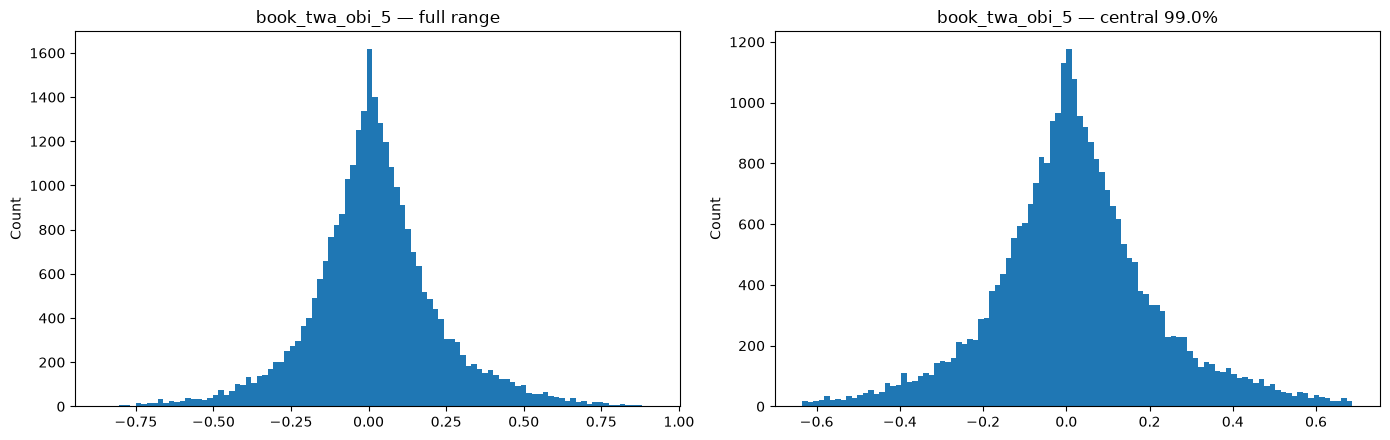

n=28,119 | central bounds [-0.63457, 0.687676] | min=-0.85685 | max=0.915902


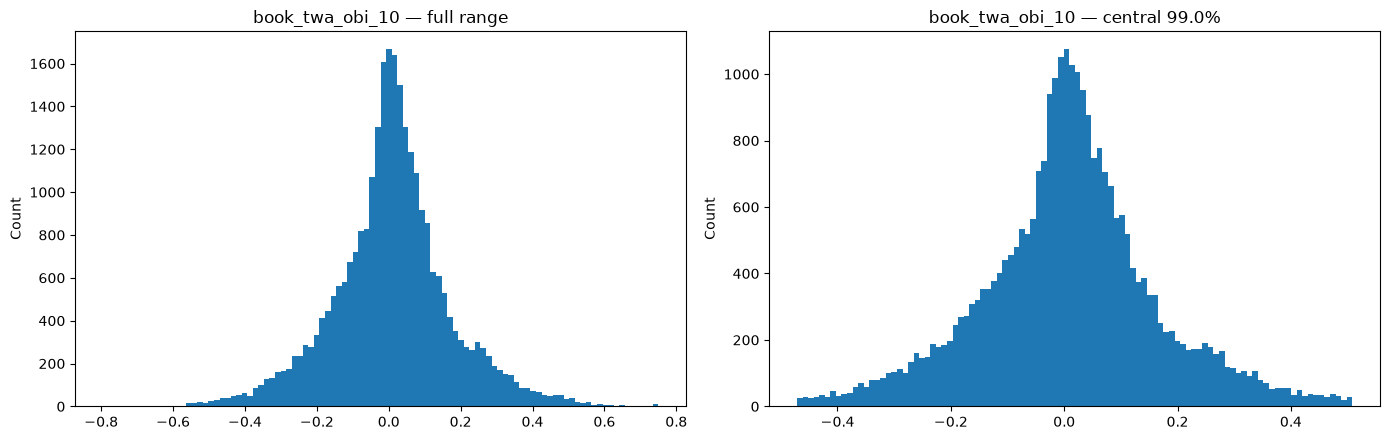

n=28,119 | central bounds [-0.471393, 0.508508] | min=-0.795102 | max=0.749387


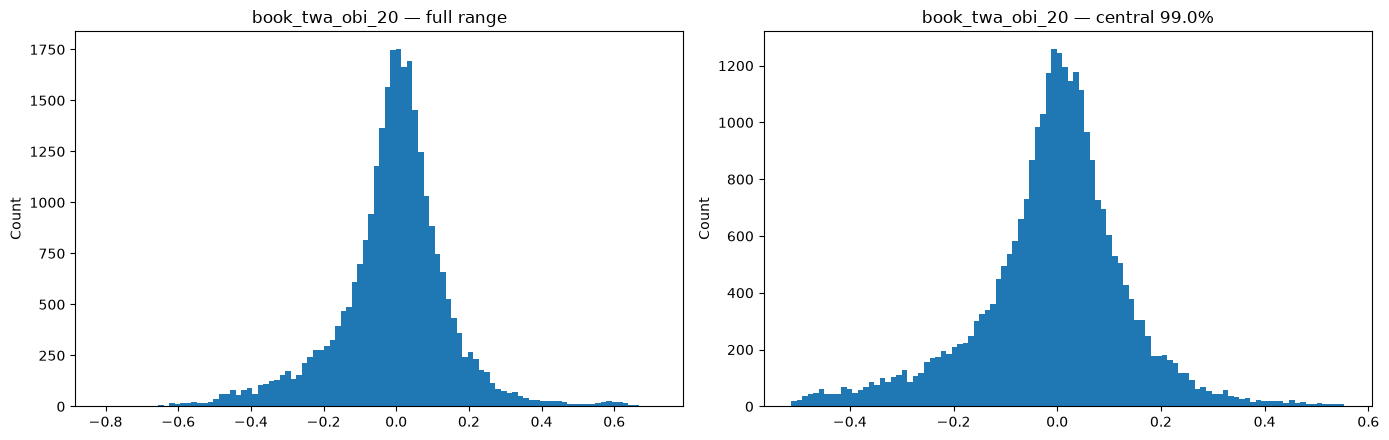

n=28,119 | central bounds [-0.513367, 0.553638] | min=-0.807421 | max=0.714406


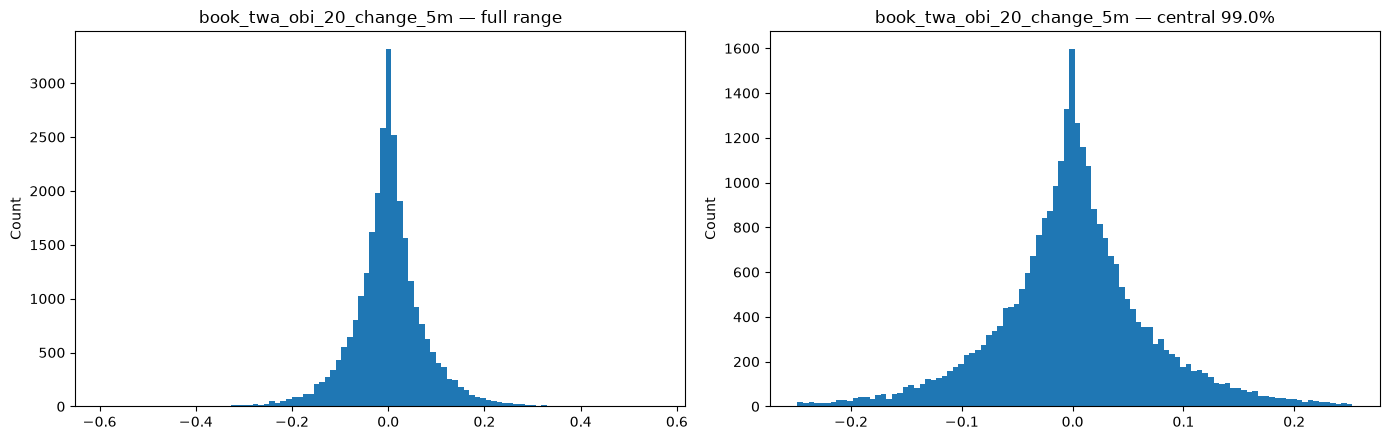

n=28,105 | central bounds [-0.248409, 0.252414] | min=-0.593039 | max=0.560171


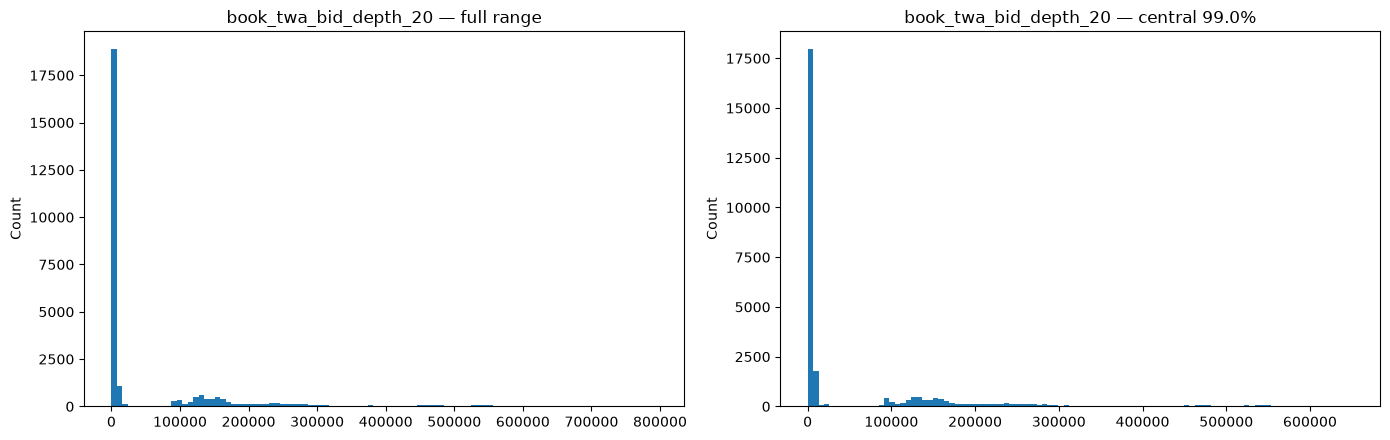

n=28,119 | central bounds [5.5152, 651509] | min=2.81317 | max=794904


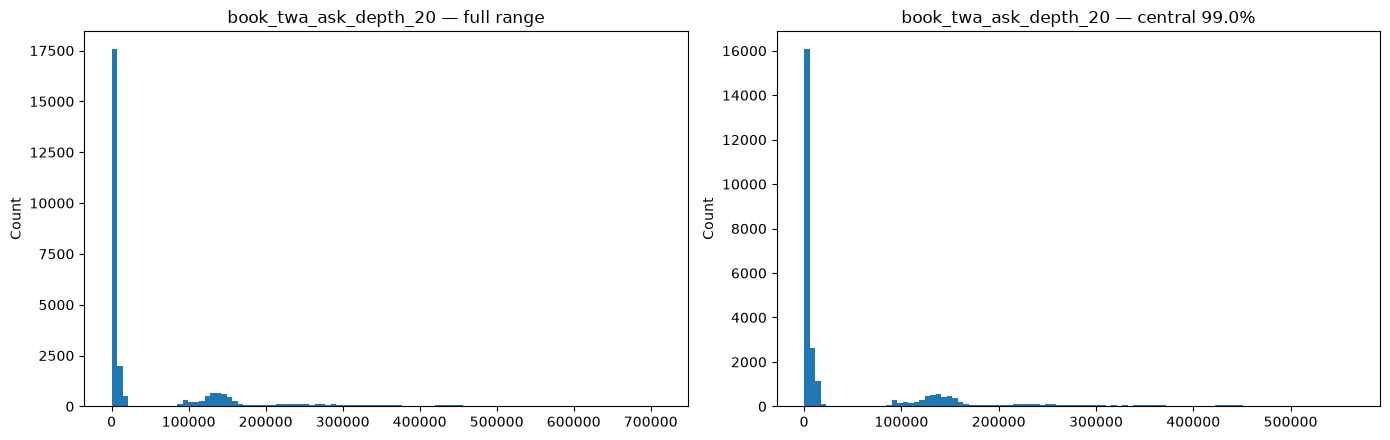

n=28,119 | central bounds [5.33533, 563797] | min=1.25273 | max=712157


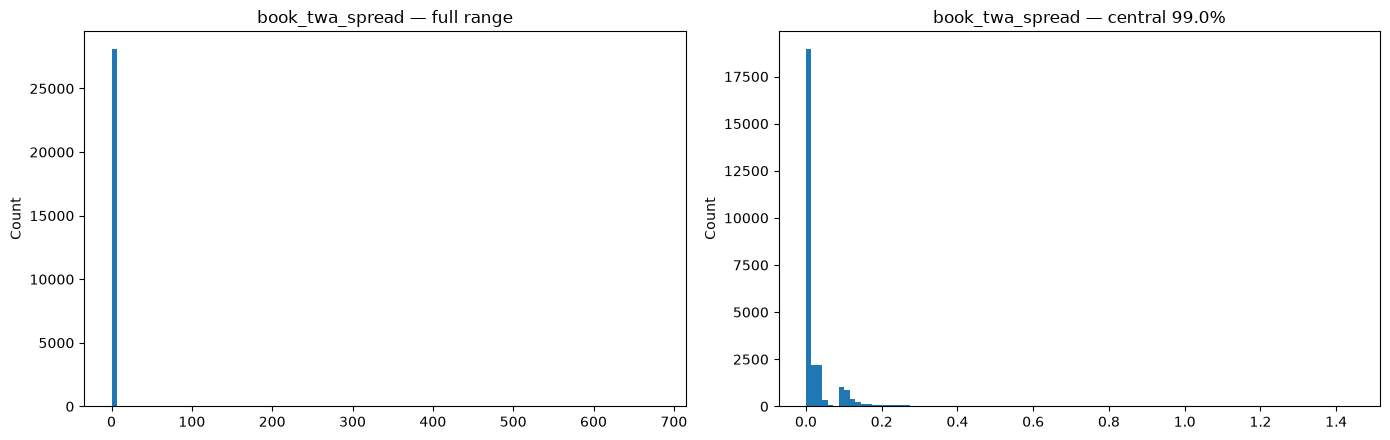

n=28,119 | central bounds [1.48621e-05, 1.45345] | min=1e-05 | max=680.55


In [159]:
l2_cols = available_groups["standard_l2"]

display(feature_summary(features, l2_cols))
display(feature_summary(features, l2_cols, group_col="underlying"))

for col in [
    c for c in [
        "book_twa_obi_5",
        "book_twa_obi_10",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
        "book_twa_bid_depth_20",
        "book_twa_ask_depth_20",
        "book_twa_spread",
    ]
    if c in features.columns
]:
    plot_full_and_central(features, col)

## 19. Diagnostic depth imbalance

The roadmap calls for depth-ratio style features. The production feature table currently preserves bid and ask depth separately.

For research only, this notebook constructs a diagnostic bounded depth imbalance:

\[
\frac{BidDepth_{20} - AskDepth_{20}}
     {BidDepth_{20} + AskDepth_{20}}
\]

This does **not** promote the variable into the production feature contract. It only tests whether this scale-free representation may be useful later.

**Redundancy check.** `book_twa_obi_20` is the time-weighted average of the instantaneous imbalance, while this variable is the imbalance of time-weighted depths. They differ only through the covariance of depth and time weights, so they are expected to be near-duplicates. The cell reports their correlation; if it is close to 1, the diagnostic adds nothing and is not carried into the persistence study.


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,_diag_depth_imbalance_20,4017,17.953431,-0.117607,0.280610,0.597056,-0.001300,-0.719457,-0.665340,-0.614022,-0.506134,-0.132452,0.424526,0.621189,0.677419,0.731217
1,BTC,_diag_depth_imbalance_20,4017,17.953431,-0.002596,0.111771,0.775374,4.446554,-0.718034,-0.324322,-0.246048,-0.173406,-0.007782,0.178919,0.272276,0.623583,0.820755
2,ETH,_diag_depth_imbalance_20,4017,17.953431,-0.027789,0.144736,-0.091332,-0.259386,-0.495975,-0.437396,-0.357327,-0.283895,-0.028543,0.207225,0.290360,0.350594,0.394622
3,HYPE,_diag_depth_imbalance_20,4017,17.953431,0.017114,0.135434,0.207451,2.419200,-0.615671,-0.485930,-0.352245,-0.214494,0.011603,0.255804,0.414224,0.541847,0.903421
4,SOL,_diag_depth_imbalance_20,4017,17.953431,0.012997,0.074586,0.046937,3.879020,-0.518235,-0.302000,-0.200269,-0.100473,0.009001,0.135886,0.222496,0.346925,0.459208
5,TRX,_diag_depth_imbalance_20,4017,17.953431,0.022828,0.132556,0.287545,1.522118,-0.564122,-0.333065,-0.266407,-0.216615,0.027737,0.230603,0.452678,0.525181,0.683418
6,XRP,_diag_depth_imbalance_20,4017,17.953431,0.025249,0.100595,-0.199468,0.921362,-0.424354,-0.355670,-0.230386,-0.149719,0.036171,0.170934,0.261949,0.409268,0.523673


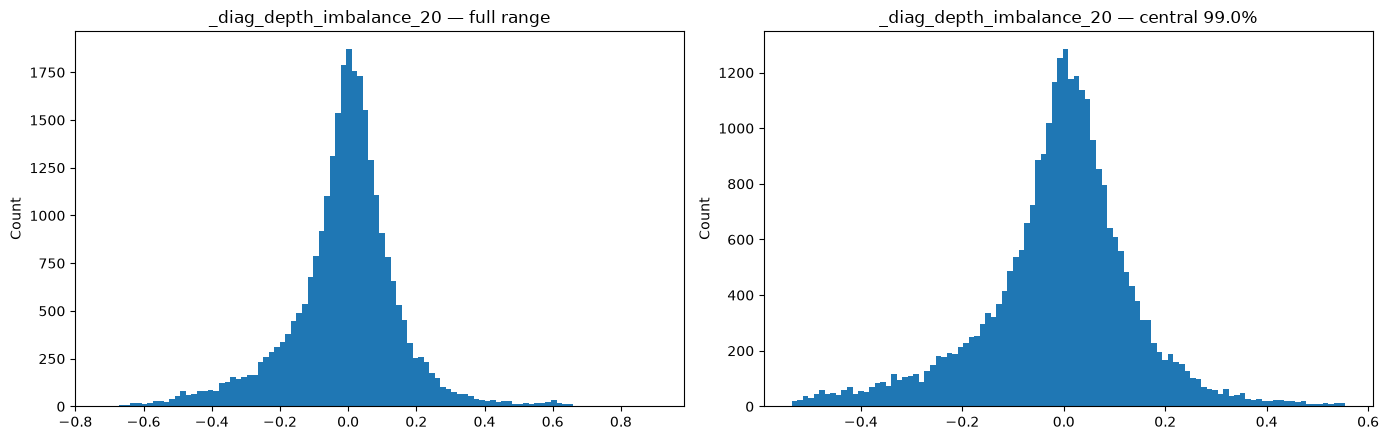

n=28,119 | central bounds [-0.537232, 0.554467] | min=-0.719457 | max=0.903421


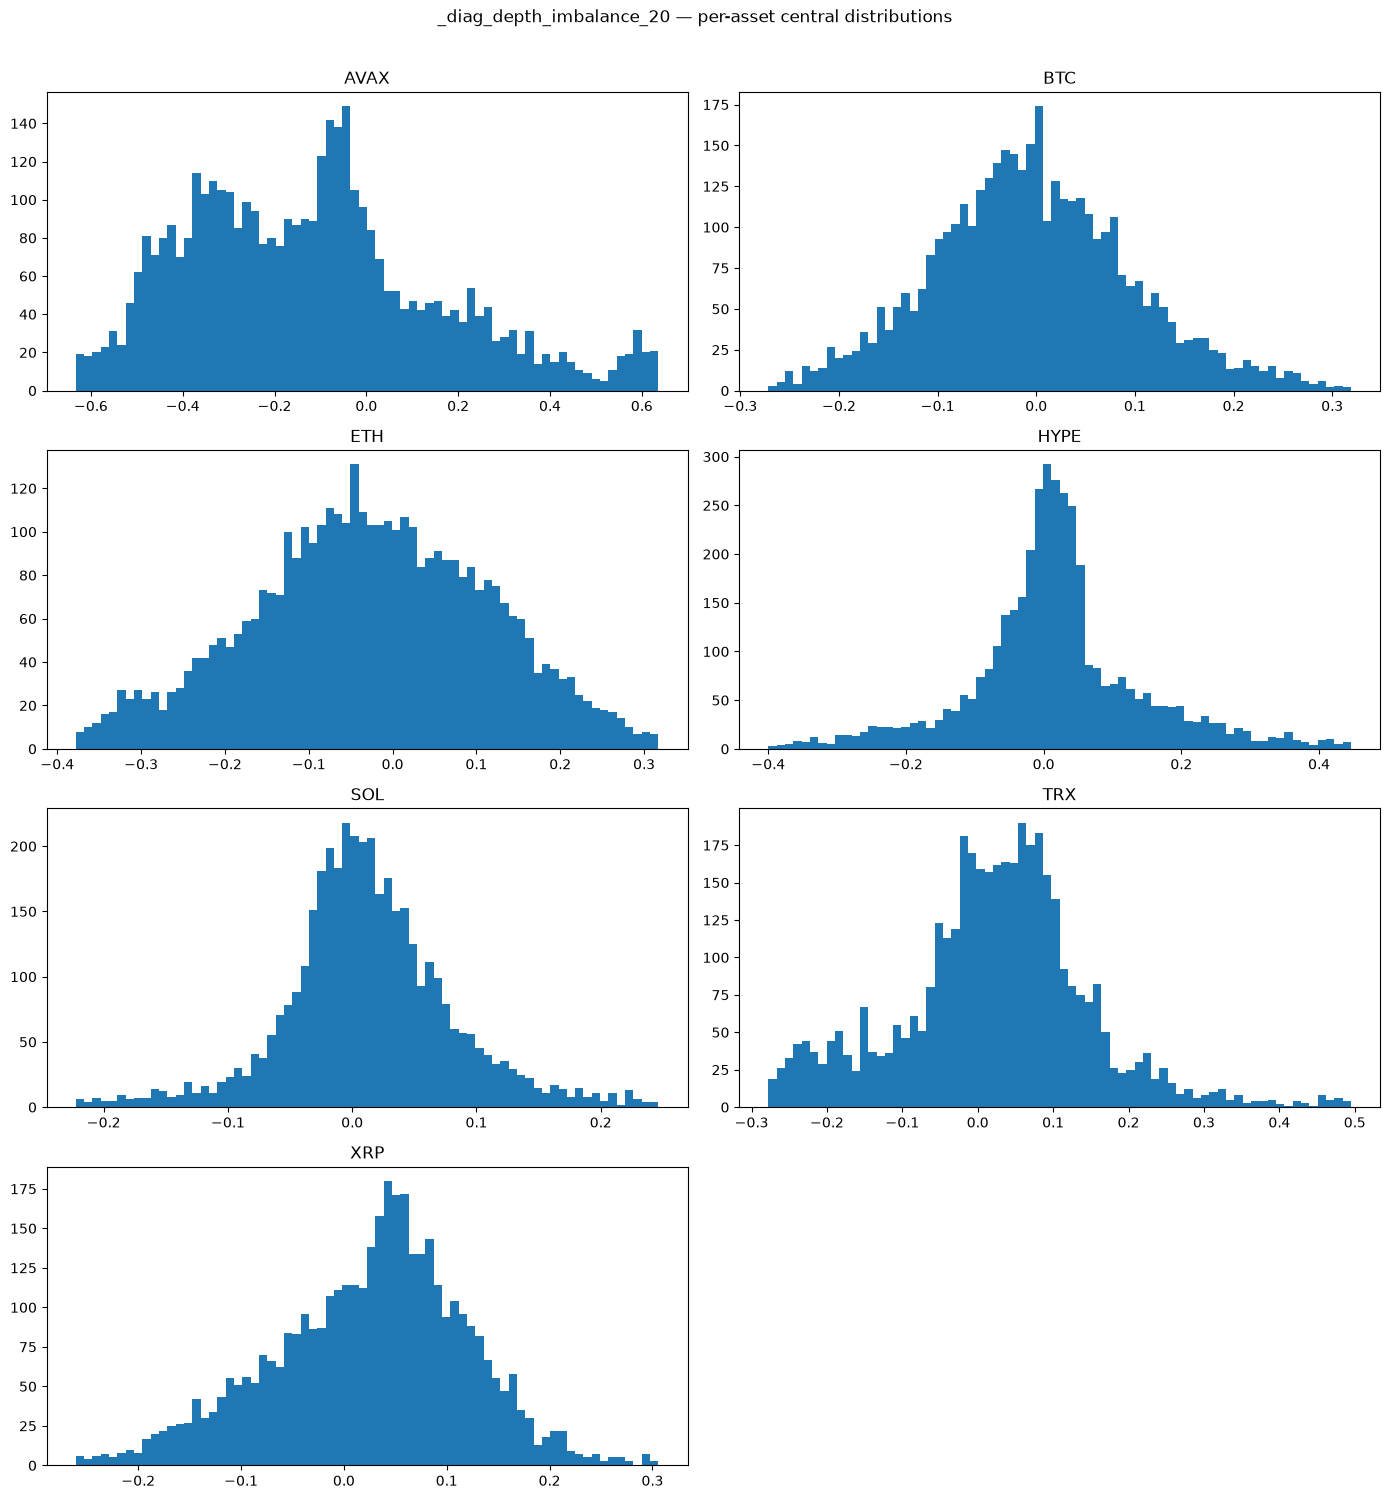

Correlation with book_twa_obi_20 by underlying:


,corr
underlying,
AVAX,0.9982
BTC,0.9897
ETH,0.9986
HYPE,0.9910
SOL,0.9942
TRX,0.9985
XRP,0.9968


Max |difference|: 0.6494


In [160]:
if {
    "book_twa_bid_depth_20",
    "book_twa_ask_depth_20",
}.issubset(features.columns):

    denom = (
        pd.to_numeric(features["book_twa_bid_depth_20"], errors="coerce")
        + pd.to_numeric(features["book_twa_ask_depth_20"], errors="coerce")
    )

    features["_diag_depth_imbalance_20"] = np.where(
        denom > 0,
        (
            pd.to_numeric(features["book_twa_bid_depth_20"], errors="coerce")
            - pd.to_numeric(features["book_twa_ask_depth_20"], errors="coerce")
        ) / denom,
        np.nan,
    )

    display(
        feature_summary(
            features,
            ["_diag_depth_imbalance_20"],
            group_col="underlying"
        )
    )

    plot_full_and_central(features, "_diag_depth_imbalance_20")
    plot_asset_histograms(features, "_diag_depth_imbalance_20")

    if "book_twa_obi_20" in features.columns:
        pair = pd.concat(
            [
                pd.to_numeric(features["book_twa_obi_20"], errors="coerce"),
                features["_diag_depth_imbalance_20"],
            ],
            axis=1,
        ).dropna()
        print("Correlation with book_twa_obi_20 by underlying:")
        display(
            features.loc[pair.index]
            .groupby("underlying")
            .apply(lambda g: g["book_twa_obi_20"].astype(float).corr(g["_diag_depth_imbalance_20"]))
            .to_frame("corr")
            .round(4)
        )
        print(f"Max |difference|: {(pair.iloc[:, 0] - pair.iloc[:, 1]).abs().max():.4f}")


## 20. L2 persistence

Deep-book imbalance is particularly relevant to the structural-regime hypothesis because a persistent directional liquidity imbalance may support momentum, while unstable or rapidly reversing imbalance may belong to the later noise/transition block.

Here we study only the persistent level and its five-minute change.

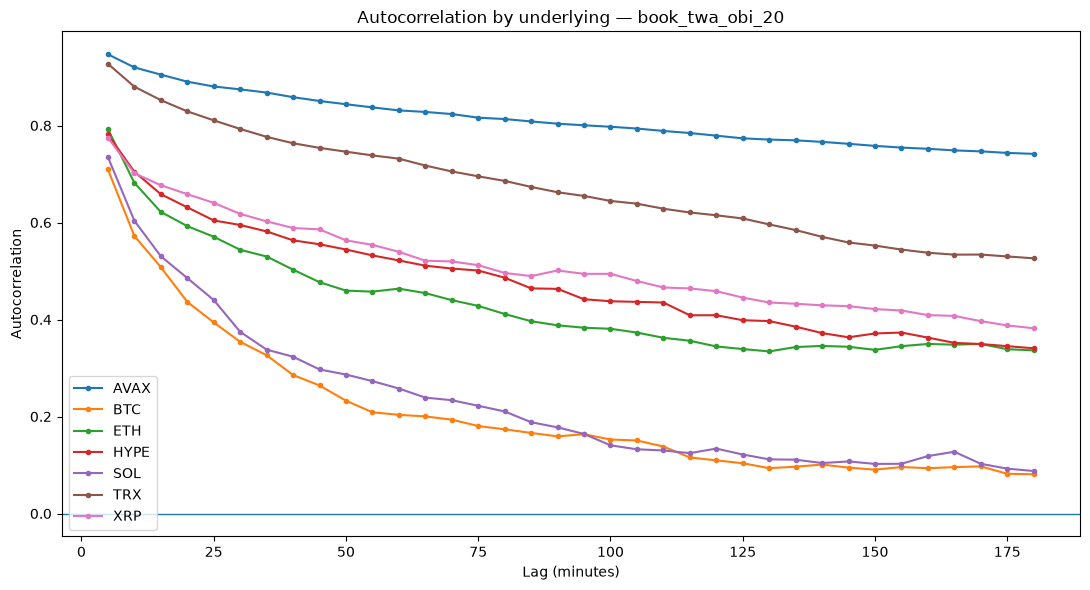

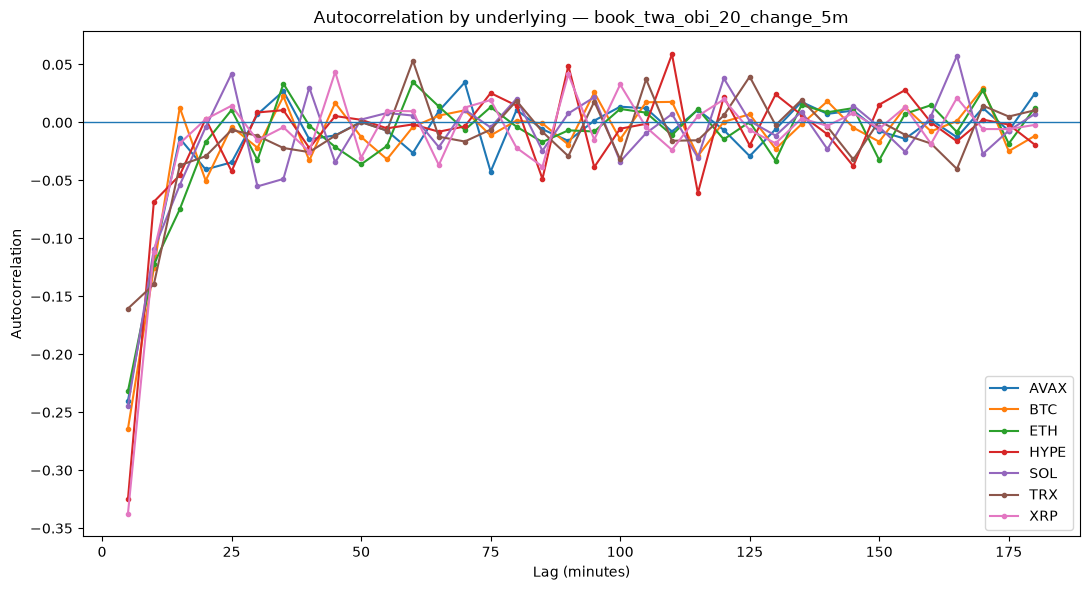

In [161]:
for col in [
    c for c in [
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
    ]
    if c in features.columns
]:
    plot_acf_by_asset(features, col, max_lag=36)

# Part G — Cross-Asset Scale and Session Variation

## 21. Cross-asset scale comparison

We intentionally do **not** standardize here. The purpose is to expose where asset scale differs enough that a later model may need asset-conditioned centering/scaling, robust scale estimates, relative/bounded representations, or separate treatment by feature family.

The table reports medians, IQRs, and 99th-percentile absolute magnitudes for a compact set of representative features.

In [162]:
scale_features = [
    c for c in [
        "return_5m",
        "realized_vol_1h_annualized",
        "log1p_volume_usd",
        "trade_flow_imbalance",
        "intrabar_range_bps",
        "open_interest_return_5m",
        "futures_spread_bps",
        "perpetual_mid_vs_index_bps",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
    ]
    if c in features.columns
]

scale_rows = []

for asset, group in features.groupby("underlying"):
    for col in scale_features:
        s = clean_numeric(group, col)
        if s.empty:
            continue

        q25, q50, q75 = s.quantile([0.25, 0.50, 0.75])

        scale_rows.append({
            "underlying": asset,
            "feature": col,
            "n": len(s),
            "median": q50,
            "iqr": q75 - q25,
            "std": s.std(),
            "q99_abs": s.abs().quantile(0.99),
            "max_abs": s.abs().max(),
        })

cross_asset_scale = pd.DataFrame(scale_rows)
display(cross_asset_scale.sort_values(["feature", "underlying"]))

,underlying,feature,n,median,iqr,std,q99_abs,max_abs
8,AVAX,book_twa_obi_20,4017,-1.139925e-01,0.355217,0.273984,0.632544,0.807421
18,BTC,book_twa_obi_20,4017,-7.873007e-03,0.129721,0.106779,0.287290,0.671824
28,ETH,book_twa_obi_20,4017,-2.801716e-02,0.192242,0.142584,0.355573,0.481537
38,HYPE,book_twa_obi_20,4017,1.123607e-02,0.102035,0.128189,0.408367,0.614184
48,SOL,book_twa_obi_20,4017,9.652409e-03,0.076273,0.075488,0.238207,0.537040
58,TRX,book_twa_obi_20,4017,2.658243e-02,0.136190,0.130481,0.432942,0.686921
68,XRP,book_twa_obi_20,4017,3.650998e-02,0.120563,0.096008,0.269059,0.558719
9,AVAX,book_twa_obi_20_change_5m,4015,0.000000e+00,0.086141,0.089304,0.293261,0.565236
19,BTC,book_twa_obi_20_change_5m,4015,6.335932e-04,0.099757,0.081410,0.241346,0.508178
29,ETH,book_twa_obi_20_change_5m,4015,4.532877e-04,0.110323,0.091817,0.265627,0.452082


## 22. Distribution drift across expiry sessions

A regime model will eventually be trained chronologically. Before that, we need to know whether feature distributions themselves move materially from session to session.

With the current short history this is only a diagnostic, not a stationarity conclusion.

,expiry_date,underlying,feature,n,median,q90,q95,q99
0,2026-09-22,AVAX,return_5m,252,0.000000,0.003832,0.004603,0.006539
1,2026-09-22,AVAX,realized_vol_1h_annualized,231,0.979014,1.448727,1.716420,1.818755
2,2026-09-22,AVAX,log1p_volume_usd,257,9.483802,10.877402,11.152397,11.657869
3,2026-09-22,AVAX,futures_spread_bps,257,2.686848,4.498801,5.241285,6.618708
4,2026-09-22,BTC,return_5m,252,0.000001,0.001577,0.002361,0.003486
5,2026-09-22,BTC,realized_vol_1h_annualized,231,0.368151,0.625052,0.666684,0.711776
6,2026-09-22,BTC,log1p_volume_usd,257,12.802016,14.159702,14.454501,14.970006
7,2026-09-22,BTC,futures_spread_bps,257,0.011696,0.537244,0.759239,1.109295
8,2026-09-22,ETH,return_5m,252,0.000066,0.002053,0.003101,0.003976
9,2026-09-22,ETH,realized_vol_1h_annualized,231,0.517986,0.818930,0.978403,1.031258


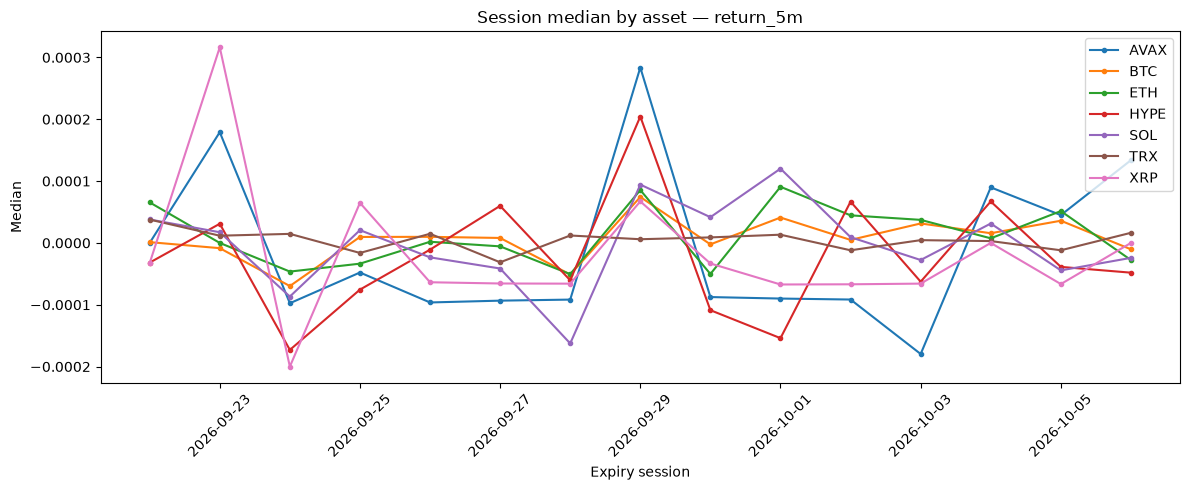

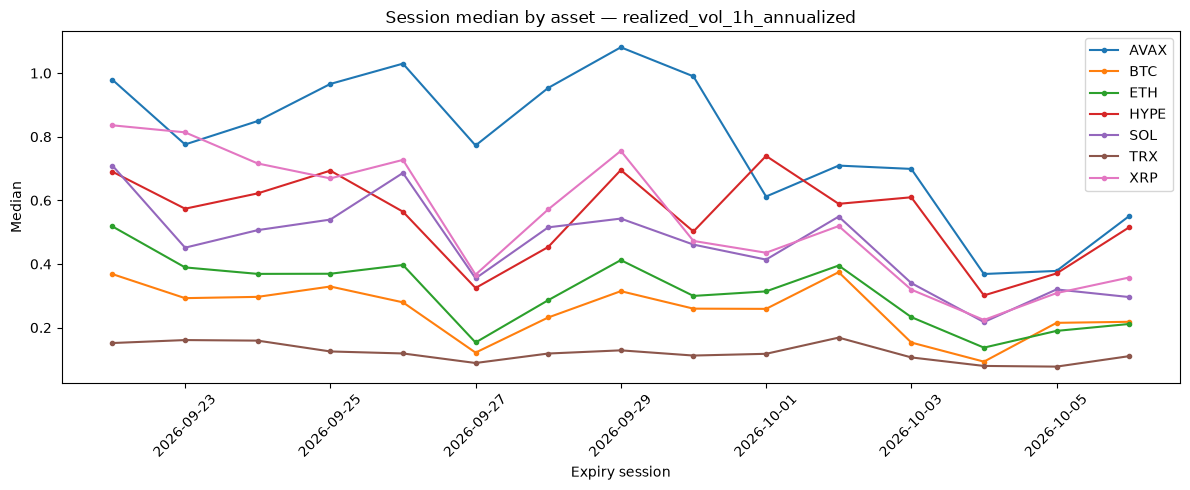

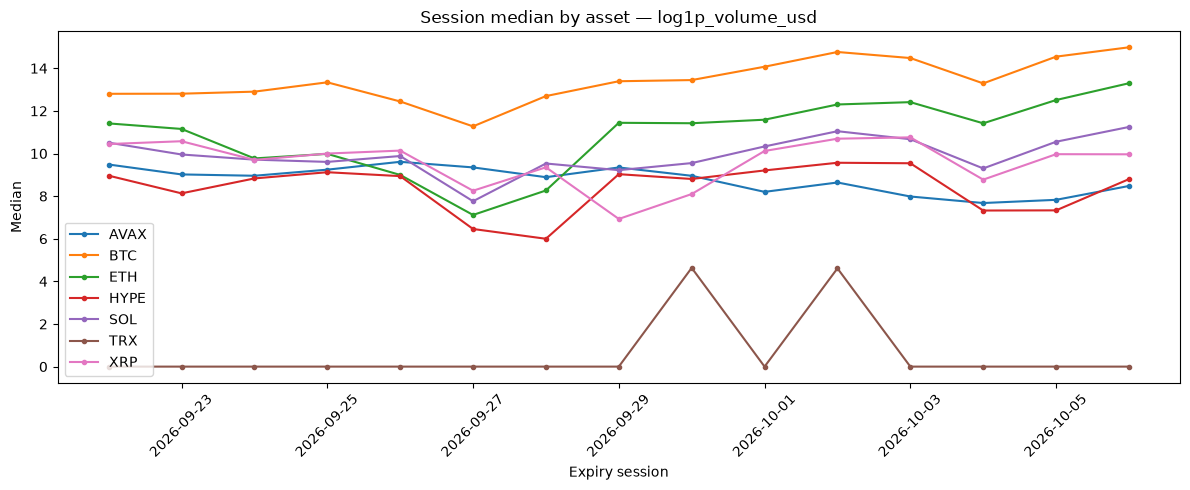

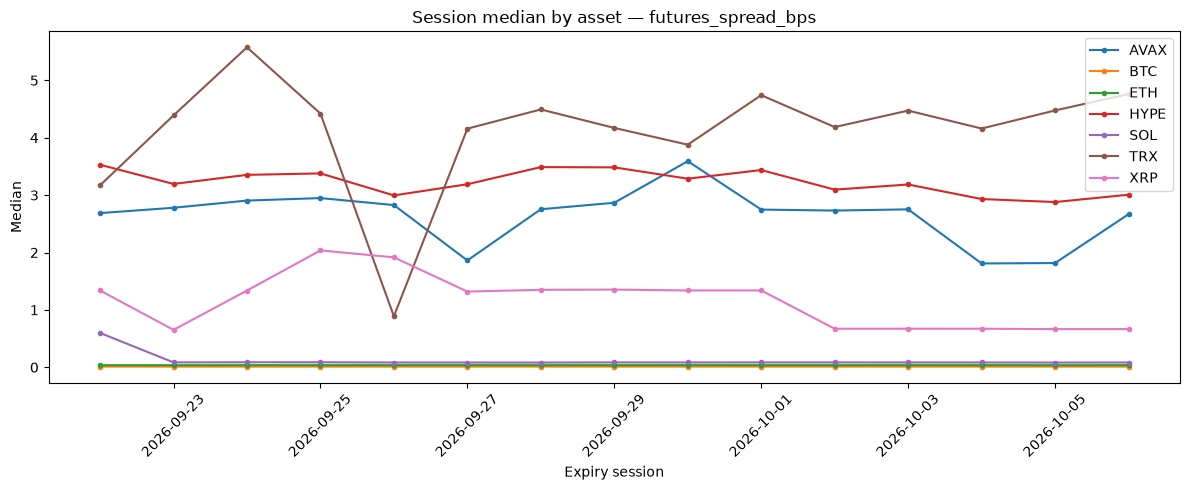

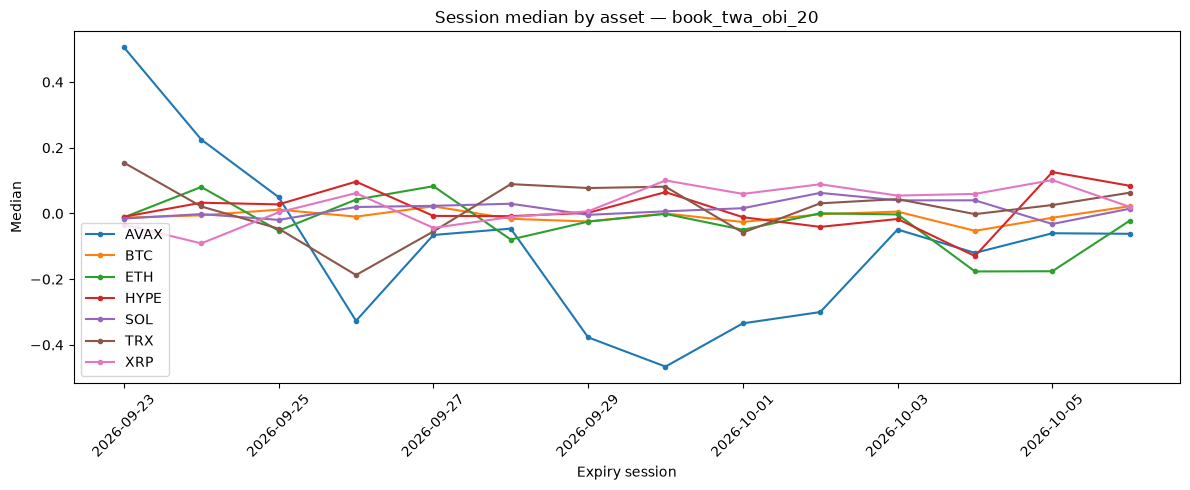

In [163]:
session_features = [
    c for c in [
        "return_5m",
        "realized_vol_1h_annualized",
        "log1p_volume_usd",
        "futures_spread_bps",
        "book_twa_obi_20",
    ]
    if c in features.columns
]

session_rows = []

for (expiry, asset), group in features.groupby(["expiry_date", "underlying"]):
    for col in session_features:
        s = clean_numeric(group, col)
        if s.empty:
            continue

        session_rows.append({
            "expiry_date": expiry,
            "underlying": asset,
            "feature": col,
            "n": len(s),
            "median": s.median(),
            "q90": s.quantile(0.90),
            "q95": s.quantile(0.95),
            "q99": s.quantile(0.99),
        })

session_distribution = pd.DataFrame(session_rows)
display(session_distribution.head(30))

for col in session_features:
    subset = session_distribution[session_distribution["feature"] == col]
    if subset.empty:
        continue

    fig, ax = plt.subplots(figsize=(12, 5))
    for asset, group in subset.groupby("underlying"):
        ax.plot(
            group["expiry_date"],
            group["median"],
            marker="o",
            ms=3,
            label=str(asset),
        )

    ax.set_title(f"Session median by asset — {col}")
    ax.set_xlabel("Expiry session")
    ax.set_ylabel("Median")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    plt.tight_layout()
    plt.show()

# Part H — Candidate Transformations

## 23. Transformation diagnostics

Transformations are evaluated for **scale management and model stability**, not for cosmetic Gaussianization.

Candidate rules used here:

- `log1p(x)` for non-negative long-tailed variables;
- `sign(x) * log1p(|x|)` for signed scale variables;
- raw form retained for bounded variables and returns.

A reduction in skewness is useful evidence, but it is **not sufficient by itself** to promote a transform into production.

In [164]:
TRANSFORM_SPECS = {
    "volume_usd": ("log1p", "non-negative activity scale"),
    "average_trade_size_usd": ("log1p", "non-negative trade-size scale"),
    "intrabar_range_bps": ("log1p", "non-negative range scale"),
    "futures_spread_bps": ("log1p", "non-negative spread scale"),
    "book_twa_spread_bps": ("log1p", "non-negative spread scale"),
    "realized_vol_30m_annualized": ("log1p", "positive volatility scale"),
    "realized_vol_1h_annualized": ("log1p", "positive volatility scale"),
    "realized_vol_4h_annualized": ("log1p", "positive volatility scale"),
    "signed_volume_usd": ("signed_log1p", "signed activity scale"),
    "open_interest_change_5m": ("signed_log1p", "signed level-change scale"),
    "perpetual_mid_vs_index_bps": ("signed_log1p", "signed basis scale"),
    "perpetual_mark_vs_index_bps": ("signed_log1p", "signed basis scale"),
    "microprice_vs_mid_bps": ("signed_log1p", "signed microprice displacement"),
    "book_twa_microprice_vs_reference_bps": (
        "signed_log1p",
        "signed microprice displacement"
    ),
}

transform_rows = []

for col, (transform_name, reason) in TRANSFORM_SPECS.items():
    if col not in features.columns:
        continue

    raw = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

    if transform_name == "log1p":
        transformed = np.log1p(raw.where(raw >= 0))
    elif transform_name == "signed_log1p":
        transformed = signed_log1p(raw)
    else:
        transformed = raw.copy()

    valid_raw = raw.dropna()
    valid_transformed = pd.Series(transformed).replace([np.inf, -np.inf], np.nan).dropna()

    transform_rows.append({
        "feature": col,
        "candidate_transform": transform_name,
        "reason": reason,
        "raw_n": len(valid_raw),
        "raw_skew": valid_raw.skew() if len(valid_raw) else np.nan,
        "raw_excess_kurtosis": valid_raw.kurt() if len(valid_raw) else np.nan,
        "transformed_n": len(valid_transformed),
        "transformed_skew": valid_transformed.skew() if len(valid_transformed) else np.nan,
        "transformed_excess_kurtosis": (
            valid_transformed.kurt() if len(valid_transformed) else np.nan
        ),
    })

transform_assessment = pd.DataFrame(transform_rows)
display(transform_assessment)

,feature,candidate_transform,reason,raw_n,raw_skew,raw_excess_kurtosis,transformed_n,transformed_skew,transformed_excess_kurtosis
0,volume_usd,log1p,non-negative activity scale,30009,24.556835,1349.487408,30009,-0.843965,-0.193767
1,average_trade_size_usd,log1p,non-negative trade-size scale,25682,68.897366,5574.467240,25682,-0.891410,0.619290
2,intrabar_range_bps,log1p,non-negative range scale,25671,3.540820,31.634147,25671,-0.810236,0.319159
3,futures_spread_bps,log1p,non-negative spread scale,29981,59.714646,5633.380195,29981,0.885542,2.533549
4,book_twa_spread_bps,log1p,non-negative spread scale,28105,30.742301,1120.502178,28105,0.787990,2.792331
5,realized_vol_30m_annualized,log1p,positive volatility scale,27286,2.088106,7.553154,27286,1.055714,1.368687
6,realized_vol_1h_annualized,log1p,positive volatility scale,25460,1.596084,3.851035,25460,0.853763,0.593051
7,realized_vol_4h_annualized,log1p,positive volatility scale,17514,1.042674,1.012942,17514,0.558412,-0.251068
8,signed_volume_usd,signed_log1p,signed activity scale,30009,-3.732406,4117.539945,30009,0.032403,-1.585370
9,open_interest_change_5m,signed_log1p,signed level-change scale,29946,-0.927515,2236.248891,29946,0.073787,0.276985


## 24. Features that should initially remain in native bounded / return form

These are not automatic production decisions. They are the default hypotheses to carry into the later feature-contract notebook.

- Returns: retain signed return interpretation; evaluate robust emission families rather than forcing normality.
- `trade_flow_imbalance`, `buy_volume_share`, and OBI variables: retain bounded support and explicitly model endpoint / boundary behavior where relevant.
- Proportional OI change: retain raw initially unless tails prove numerically problematic.
- Cross-asset scale differences: preserve them until the deterministic normalization study determines what should be asset/TOD/TTE conditioned.

In [165]:
native_form_candidates = [
    c for c in [
        "return_5m",
        "return_15m",
        "return_30m",
        "return_1h",
        "trade_flow_imbalance",
        "buy_volume_share",
        "book_twa_obi_5",
        "book_twa_obi_10",
        "book_twa_obi_20",
        "book_twa_obi_20_change_5m",
        "open_interest_return_5m",
        "_diag_depth_imbalance_20",
    ]
    if c in features.columns
]

native_summary = feature_summary(features, native_form_candidates)

if not native_summary.empty:
    display(
        native_summary[
            [
                "feature",
                "n",
                "skew",
                "excess_kurtosis",
                "min",
                "q01",
                "median",
                "q99",
                "max",
            ]
        ]
    )

,feature,n,skew,excess_kurtosis,min,q01,median,q99,max
0,return_5m,29139,-0.058507,12.324174,-0.023029,-0.005399,0.000000,0.005355,0.021486
1,return_15m,29111,-0.429734,10.040756,-0.041023,-0.009445,0.000021,0.009121,0.025244
2,return_30m,29055,-0.437778,7.640966,-0.044089,-0.013042,0.000020,0.012345,0.030986
3,return_1h,29020,-0.160040,6.214475,-0.049058,-0.017724,0.000043,0.017345,0.049225
4,trade_flow_imbalance,25682,0.030997,-1.069802,-1.000000,-1.000000,-0.006061,1.000000,1.000000
5,buy_volume_share,25682,0.030997,-1.069802,0.000000,0.000000,0.496970,1.000000,1.000000
6,book_twa_obi_5,28119,0.142246,1.702265,-0.856850,-0.550789,0.012576,0.609960,0.915902
7,book_twa_obi_10,28119,0.094526,1.308974,-0.795102,-0.422797,0.008832,0.460034,0.749387
8,book_twa_obi_20,28119,-0.245743,2.548373,-0.807421,-0.466017,0.002572,0.423536,0.714406
9,book_twa_obi_20_change_5m,28105,-0.015128,3.758163,-0.593039,-0.210069,-0.000058,0.211344,0.560171


# Part I — Futures Data Integrity

## 25. Why this part exists

Parts A–E show tail events that may be **feed artifacts rather than market behaviour** (audit A1): constant spreads with `return_5m = 0` for an hour while trading continued, a ±9.6% TRX round trip on zero volume, and 500–800 bps book spreads with no trades.

Before any return-based feature is trusted, each five-minute futures state is tested with signals that existed **before collector v0.3**:

| Test | Raw fields | What it detects |
|---|---|---|
| Wide quote | `best_bid_price`, `best_ask_price` | Spread far above the asset's own typical spread |
| Mid off index | ticker mid, `index_price` | Perpetual mid detached from the settlement index |
| Ticker vs L2 disagreement (**v0.3 rows only**) | ticker BBO vs `book_best_bid_price` / `book_best_ask_price` | One of the two feeds is stale |
| Stale BBO vs index | BBO unchanged across states while the index moved more than half the quoted spread | Quotes that a live market would have repriced |
| Frozen BBO with trades | identical BBO for ≥ `FROZEN_MIN_BARS` states while `trade_count > 0` | Trading continues against a frozen quote |
| Last trade outside BBO (**v0.3 rows only**) | `close`, `last_trade_timestamp_ms` vs boundary BBO | A trade printed shortly before the boundary outside the recorded quote |
| No L2 updates | `book_update_count = 0` with `trade_count > 0` | Dead book subscription |

**Scope.** Thresholds here are full-sample robust statistics, used only to **find and describe** episodes. They are not a production rule: the integrity gate in `quality_contract.py` must estimate its thresholds on training history only. Nothing is dropped from any table.

All timestamps in this part are **UTC** (`SET TimeZone='UTC'` in Section 1).

In [166]:
RAW_WANTED = [
    "underlying", "bar_end", "instrument_name",
    "best_bid_price", "best_ask_price", "mid_price",
    "mark_price", "index_price", "open_interest",
    "book_valid", "book_best_bid_price", "book_best_ask_price", "book_mid_price",
    "book_update_count", "book_stats_complete", "book_age_ms",
    "ticker_age_ms", "ticker_exchange_timestamp_ms",
    "open", "high", "low", "close", "vwap",
    "volume_usd", "trade_count", "last_trade_timestamp_ms",
    "stream_complete", "stream_incomplete_reason", "connection_count",
    "collector_version",
]

def load_raw_futures():
    """Raw perpetual rows with every pre-v0.3 integrity field.

    Uses the research DB's raw view when present; otherwise reads the
    Parquet files directly. Both paths are read-only.
    """
    has_view = con.execute(
        "SELECT COUNT(*) FROM duckdb_views() WHERE view_name = 'raw_futures_5m'"
    ).fetchone()[0] > 0

    if has_view:
        source = "raw_futures_5m"
    else:
        glob = (DATA_ROOT / "futures" / "5m" / "date=*" / "futures_5m.parquet").as_posix()
        source = (
            f"read_parquet('{glob}', hive_partitioning = true, union_by_name = true)"
        )

    available = set(
        con.execute(f"DESCRIBE SELECT * FROM {source}").df()["column_name"]
    )
    selected = [c for c in RAW_WANTED if c in available]
    missing = [c for c in RAW_WANTED if c not in available]

    raw = con.execute(
        f"SELECT {', '.join(selected)} FROM {source} "
        "ORDER BY underlying, bar_end, instrument_name"
    ).df()

    return raw, source, missing

raw_futures_all, raw_source, raw_missing = load_raw_futures()

raw_futures_all["bar_end"] = pd.to_datetime(raw_futures_all["bar_end"], utc=True)

print(f"Source:            {raw_source}")
print(f"Raw rows:          {len(raw_futures_all):,}")
print(f"First / last bar:  {raw_futures_all['bar_end'].min()}  /  {raw_futures_all['bar_end'].max()}")
print(f"Fields not found:  {raw_missing if raw_missing else 'none'}")

# One perpetual per underlying is expected. Several instruments per
# underlying would make the canonical rank-by-name choice switch
# instruments, which would show up as OI and price jumps.
instrument_inventory = (
    raw_futures_all
    .groupby(["underlying", "instrument_name"], dropna=False)
    .agg(rows=("bar_end", "size"), first_bar=("bar_end", "min"), last_bar=("bar_end", "max"))
    .reset_index()
)
display(instrument_inventory)

dup_states = int(raw_futures_all.duplicated(["underlying", "bar_end"]).sum())
print(f"Duplicate (underlying, bar_end) rows: {dup_states:,}")

# Same canonical choice as build_canonical.py: first instrument_name per state.
raw_futures = (
    raw_futures_all
    .drop_duplicates(["underlying", "bar_end"], keep="first")
    .sort_values(["underlying", "bar_end"])
    .reset_index(drop=True)
)

if "collector_version" in raw_futures.columns:
    display(
        raw_futures
        .assign(collector_version=raw_futures["collector_version"].fillna("pre-v0.3 (unstamped)"))
        .groupby("collector_version")
        .agg(rows=("bar_end", "size"), first_bar=("bar_end", "min"), last_bar=("bar_end", "max"))
    )

Source:            raw_futures_5m
Raw rows:          30,184
First / last bar:  2026-09-21 10:30:00+00:00  /  2026-10-06 10:00:00+00:00
Fields not found:  none


,underlying,instrument_name,rows,first_bar,last_bar
0,AVAX,AVAX_USDC-PERPETUAL,4312,2026-09-21 10:30:00+00:00,2026-10-06 10:00:00+00:00
1,BTC,BTC_USDC-PERPETUAL,4312,2026-09-21 10:30:00+00:00,2026-10-06 10:00:00+00:00
2,ETH,ETH_USDC-PERPETUAL,4312,2026-09-21 10:30:00+00:00,2026-10-06 10:00:00+00:00
3,HYPE,HYPE_USDC-PERPETUAL,4312,2026-09-21 10:30:00+00:00,2026-10-06 10:00:00+00:00
4,SOL,SOL_USDC-PERPETUAL,4312,2026-09-21 10:30:00+00:00,2026-10-06 10:00:00+00:00
5,TRX,TRX_USDC-PERPETUAL,4312,2026-09-21 10:30:00+00:00,2026-10-06 10:00:00+00:00
6,XRP,XRP_USDC-PERPETUAL,4312,2026-09-21 10:30:00+00:00,2026-10-06 10:00:00+00:00


Duplicate (underlying, bar_end) rows: 0


,rows,first_bar,last_bar
collector_version,,,
futures_5m_l2_v0.3.0,1911,2026-10-04 16:20:00+00:00,2026-10-05 15:00:00+00:00
futures_5m_l2_v0.3.1,1596,2026-10-05 15:05:00+00:00,2026-10-06 10:00:00+00:00
pre-v0.3 (unstamped),26677,2026-09-21 10:30:00+00:00,2026-10-04 16:15:00+00:00


## 26. Per-state integrity metrics

All lags are taken on the exact five-minute grid per asset; a lag across a gap is `NaN`, never bridged.

Definitions (bps of the relevant price):

$$
s_t = 10^4\,\frac{a_t - b_t}{m_t}, \qquad
\text{basis}_t = 10^4 \ln\frac{m_t}{I_t}, \qquad
\Delta^{\text{tick/L2}}_t = 10^4\,\frac{\left|m_t - m^{L2}_t\right|}{m_t}
$$

where $b_t, a_t, m_t$ are the ticker bid, ask and mid at the state boundary, $m^{L2}_t$ is the L2 book mid and $I_t$ is the Deribit index.

**Stale BBO vs index.** Let $t_0$ be the last state at which the ticker BBO changed. If the BBO is unchanged at $t$ but

$$
10^4\left|\ln\frac{I_t}{I_{t_0}}\right| > \tfrac12\, s_t,
$$

the recorded quote no longer brackets where the index says the market is.

**Last trade outside BBO.** Only trades within `LAST_TRADE_RECENCY_MS` of the boundary are tested, so that a legitimate move between the trade and the snapshot is small:

$$
o_t = 10^4\,\frac{\max\left(\text{close}_t - a_t,\; b_t - \text{close}_t,\; 0\right)}{m_t}
$$

In [167]:
LAST_TRADE_RECENCY_MS = 30_000
FROZEN_MIN_BARS = 3

def lag_on_grid(g, column, lag=1):
    """Value `lag` five-minute states earlier, or NaN if the grid has a gap."""
    shifted = g[column].shift(lag)
    gap_ok = (g["bar_end"] - g["bar_end"].shift(lag)) == pd.Timedelta(minutes=5 * lag)
    return shifted.where(gap_ok)

def num(df, col):
    if col not in df.columns:
        return pd.Series(np.nan, index=df.index)
    return pd.to_numeric(df[col], errors="coerce")

def integrity_metrics(g):
    g = g.sort_values("bar_end").copy()

    bid, ask, index = num(g, "best_bid_price"), num(g, "best_ask_price"), num(g, "index_price")
    two_sided = (bid > 0) & (ask > 0) & (bid <= ask)
    mid = ((bid + ask) / 2).where(two_sided)
    g["tick_mid"] = mid
    g["tick_spread_bps"] = (1e4 * (ask - bid) / mid).where(two_sided)
    g["mid_vs_index_bps"] = (1e4 * np.log(mid / index)).where(index > 0)
    g["mark_vs_index_bps"] = (1e4 * np.log(num(g, "mark_price") / index)).where(index > 0)

    vwap = num(g, "vwap")
    g["vwap_vs_index_bps"] = (1e4 * np.log(vwap / index)).where((vwap > 0) & (index > 0))

    l2_bid, l2_ask = num(g, "book_best_bid_price"), num(g, "book_best_ask_price")
    l2_ok = (l2_bid > 0) & (l2_ask > 0) & (l2_bid <= l2_ask)
    g["l2_spread_bps"] = (1e4 * (l2_ask - l2_bid) / ((l2_ask + l2_bid) / 2)).where(l2_ok)
    g["tick_vs_l2_mid_bps"] = (1e4 * ((l2_bid + l2_ask) / 2 - mid).abs() / mid).where(l2_ok & two_sided)

    # BBO change tracking on the exact grid.
    g["_bid"], g["_ask"] = bid.where(two_sided), ask.where(two_sided)
    prev_bid, prev_ask = lag_on_grid(g, "_bid"), lag_on_grid(g, "_ask")
    g["bbo_unchanged"] = (g["_bid"] == prev_bid) & (g["_ask"] == prev_ask)

    # A new run starts whenever the BBO changes, the grid breaks or the quote is invalid.
    run_start = ~g["bbo_unchanged"]
    run_id = run_start.cumsum()
    g["bbo_run_bars"] = g.groupby(run_id).cumcount() + 1
    g["_index_at_change"] = index.where(run_start).groupby(run_id).transform("first")
    g["index_drift_since_bbo_change_bps"] = (
        1e4 * np.log(index / g["_index_at_change"]).abs()
    ).where(g["bbo_unchanged"])

    trades = num(g, "trade_count").fillna(0)
    g["_trades"] = trades
    g["bbo_frozen_trade_bars"] = (
        (g["bbo_unchanged"] & (trades > 0))
        .astype(int)
        .groupby(run_id)
        .cumsum()
    )

    # Last trade close vs the boundary quote, only for recent trades.
    end_ms = g["bar_end"].astype("int64") // 10**6
    recency = end_ms - num(g, "last_trade_timestamp_ms")
    close = num(g, "close")
    outside = np.maximum.reduce([close - ask, bid - close, pd.Series(0.0, index=g.index)])
    g["last_trade_recency_ms"] = recency
    g["last_trade_outside_bbo_bps"] = (1e4 * outside / mid).where(
        two_sided & (close > 0) & (recency >= 0) & (recency <= LAST_TRADE_RECENCY_MS)
    )

    g["index_return_5m"] = np.log(index / lag_on_grid(g.assign(_i=index), "_i")).where(index > 0)
    g["mid_return_5m_raw"] = np.log(mid / lag_on_grid(g.assign(_m=mid), "_m"))
    g["two_sided_ticker"] = two_sided

    return g.drop(columns=["_bid", "_ask", "_index_at_change", "_trades"])

def per_asset(df, func, **kwargs):
    """Apply a frame-level function per underlying (explicit loop: no groupby.apply)."""
    parts = [func(g, **kwargs) for _, g in df.groupby("underlying", sort=True)]
    return pd.concat(parts, ignore_index=True) if parts else df.iloc[0:0].copy()

integrity = per_asset(raw_futures, integrity_metrics)

metric_cols = [
    "tick_spread_bps", "l2_spread_bps", "tick_vs_l2_mid_bps",
    "mid_vs_index_bps", "mark_vs_index_bps", "vwap_vs_index_bps",
    "index_drift_since_bbo_change_bps", "last_trade_outside_bbo_bps",
    "ticker_age_ms", "book_age_ms", "book_update_count",
]
display(feature_summary(integrity, [c for c in metric_cols if c in integrity.columns], group_col="underlying"))

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,tick_spread_bps,4308,0.092764,3.569561,11.485675,28.366906,1070.673500,0.873324,0.885815,0.901104,0.957841,2.726034,5.539529,7.497845,1.279164e+02,5.209854e+02
1,AVAX,l2_spread_bps,500,88.404453,2.450370,1.105699,1.630885,4.065970,0.880475,0.882848,0.901908,0.917103,1.830245,4.554377,5.522943,8.537982e+00,8.896797e+00
2,AVAX,tick_vs_l2_mid_bps,500,88.404453,0.009170,0.112085,13.549088,194.130920,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.604948e+00,1.837222e+00
3,AVAX,mid_vs_index_bps,4308,0.092764,2.257528,5.649184,20.629009,763.439705,-39.557725,-12.200984,-7.899643,-3.558451,2.258407,7.218878,11.053559,4.953377e+01,2.340204e+02
4,AVAX,mark_vs_index_bps,4308,0.092764,2.267344,4.770019,31.445843,1606.887332,-9.786913,-8.869116,-7.171627,-2.726814,1.950839,6.634757,9.578352,1.568558e+01,2.468378e+02
5,AVAX,vwap_vs_index_bps,3965,8.047310,2.212332,15.710912,-0.267533,3.154544,-101.908263,-71.030217,-41.028564,-22.756059,2.580277,26.945589,42.588262,7.372265e+01,7.827100e+01
6,AVAX,index_drift_since_bbo_change_bps,41,99.049165,9.670628,19.831629,2.314983,4.347151,0.000000,0.000000,0.000000,0.000000,0.919667,55.982088,73.201062,7.483364e+01,7.501504e+01
7,AVAX,ticker_age_ms,4308,0.092764,1409.090761,2788.168903,9.227021,143.127186,68.000000,83.535000,122.070000,194.000000,636.000000,5104.900000,11944.200000,3.420421e+04,6.873200e+04
8,AVAX,book_age_ms,4040,6.307978,5980.250000,111488.580038,23.869295,606.086642,69.000000,82.000000,106.170000,161.000000,450.000000,2293.400000,4657.010000,2.205338e+06,3.417038e+06
9,AVAX,book_update_count,4044,6.215213,610.104105,129.594842,-0.627970,1.230515,0.000000,0.000000,303.000000,395.150000,619.000000,804.000000,851.000000,8.739570e+02,8.810000e+02


## 27. Candidate integrity flags

Robust per-asset scale: for a metric $x$ with per-asset median $\tilde x$,

$$
z_t = \frac{x_t - \tilde x}{\max\left(1.4826\,\mathrm{MAD}(x),\ \text{floor}\right)}
$$

**Why a robust z alone is not enough.** BTC, ETH and SOL quote on one tick almost all the time (BTC median spread ≈ 0.012 bps), so $\mathrm{MAD}=0$ and a 10-tick spread of 0.1 bps scores $z>8$. The first run of this notebook flagged 27% of SOL states this way, and the flagged bars clustered in volatile periods. Masking them would have removed genuine volatility.

Every level flag therefore also needs an **economic floor**:

| Flag | Fires when |
|---|---|
| Wide spread | $z_{\log s} > z^*$ **and** $s_t \ge$ `WIDE_SPREAD_MIN_BPS` **and** $s_t \ge$ `WIDE_SPREAD_MIN_RATIO` $\times \tilde s$ |
| Mid off index | $\lvert z_{\text{basis}}\rvert > z^*$ **and** $\lvert\text{basis}_t - \widetilde{\text{basis}}\rvert \ge$ `BASIS_MIN_DEVIATION_BPS` |
| Stale vs index | BBO unchanged **and** index drift $> \max\left(\tfrac12 s_t,\ \text{`STALE_DRIFT_MIN_BPS`}\right)$ |

**Pre-v0.3 coverage.** `tick_l2_disagree` and `trade_outside_bbo` need fields that only v0.3 rows carry reliably (L2 best bid/ask), and the trade test cannot catch trades inside a frozen wide quote. They are reported separately as **v0.3-only** flags and are not used to judge history.

**Known exchange events.** The 1 Oct 09:00–10:05 UTC window was Deribit's planned platform migration for the Coinbase International consolidation. It is labelled as a known event, so it can be excluded as a block rather than through threshold flags.

In [168]:
ROBUST_Z = 8.0
LOG_SPREAD_FLOOR = 0.10            # scale floor for log spread (≈10% change)
BASIS_FLOOR_BPS = 1.0              # scale floor for basis
TICK_L2_FLOOR_BPS = 1.0

WIDE_SPREAD_MIN_BPS = 5.0          # economic floor: spread must be at least this wide
WIDE_SPREAD_MIN_RATIO = 10.0       # ...and at least this multiple of the asset's median spread
BASIS_MIN_DEVIATION_BPS = 10.0     # basis must move at least this far from its median
STALE_DRIFT_MIN_BPS = 5.0          # index drift needed before an unchanged BBO counts as stale
LAST_TRADE_OUTSIDE_MIN_BPS = 5.0

KNOWN_EXCHANGE_EVENTS = [
    # (start inclusive, end inclusive, UTC, label)
    ("2026-10-01 09:00", "2026-10-01 10:05",
     "Deribit platform migration (Coinbase International consolidation)"),
]

def robust_z(x, floor):
    x = pd.to_numeric(x, errors="coerce")
    med = x.median()
    mad = (x - med).abs().median()
    scale = max(1.4826 * mad, floor) if np.isfinite(mad) else floor
    return (x - med) / scale

def add_flags(g, z=ROBUST_Z):
    g = g.copy()
    spread = g["tick_spread_bps"]
    median_spread = spread.median()
    log_spread = np.log(spread.where(spread > 0))
    basis_dev = (g["mid_vs_index_bps"] - g["mid_vs_index_bps"].median()).abs()

    g["z_log_spread"] = robust_z(log_spread, LOG_SPREAD_FLOOR)
    g["z_basis"] = robust_z(g["mid_vs_index_bps"], BASIS_FLOOR_BPS)
    g["z_tick_l2"] = robust_z(g["tick_vs_l2_mid_bps"], TICK_L2_FLOOR_BPS)

    trades = num(g, "trade_count").fillna(0)
    updates = num(g, "book_update_count")
    is_v03 = g["collector_version"].notna() if "collector_version" in g.columns else pd.Series(False, index=g.index)

    g["flag_wide_spread"] = (
        (g["z_log_spread"] > z)
        & (spread >= WIDE_SPREAD_MIN_BPS)
        & (spread >= WIDE_SPREAD_MIN_RATIO * median_spread)
    )
    g["flag_mid_off_index"] = (g["z_basis"].abs() > z) & (basis_dev >= BASIS_MIN_DEVIATION_BPS)
    g["flag_stale_vs_index"] = (
        g["bbo_unchanged"]
        & (g["index_drift_since_bbo_change_bps"] > np.maximum(0.5 * spread, STALE_DRIFT_MIN_BPS))
    )
    g["flag_frozen_with_trades"] = g["bbo_frozen_trade_bars"] >= FROZEN_MIN_BARS
    g["flag_no_l2_updates"] = (updates == 0) & (trades > 0)
    g["flag_no_two_sided"] = ~g["two_sided_ticker"].astype(bool)

    # v0.3-only flags: evaluated only on stamped rows.
    g["flag_tick_l2_disagree"] = is_v03 & (g["z_tick_l2"] > z)
    g["flag_trade_outside_bbo"] = is_v03 & (g["last_trade_outside_bbo_bps"] > LAST_TRADE_OUTSIDE_MIN_BPS)

    g["known_exchange_event"] = False
    for start, end, _label in KNOWN_EXCHANGE_EVENTS:
        g.loc[
            g["bar_end"].between(pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC")),
            "known_exchange_event",
        ] = True
    return g

FLAG_COLS_HISTORY = [
    "flag_wide_spread", "flag_mid_off_index", "flag_stale_vs_index",
    "flag_frozen_with_trades", "flag_no_l2_updates", "flag_no_two_sided",
]
FLAG_COLS_V03 = ["flag_tick_l2_disagree", "flag_trade_outside_bbo"]
FLAG_COLS = FLAG_COLS_HISTORY + FLAG_COLS_V03

integrity = per_asset(integrity, add_flags)
integrity[FLAG_COLS + ["known_exchange_event"]] = (
    integrity[FLAG_COLS + ["known_exchange_event"]].fillna(False).astype(bool)
)
integrity["suspect_quote"] = integrity[FLAG_COLS].any(axis=1) | integrity["known_exchange_event"]

flag_counts = (
    integrity
    .groupby("underlying")[FLAG_COLS + ["known_exchange_event", "suspect_quote"]]
    .sum()
    .assign(states=integrity.groupby("underlying").size())
)
flag_pct = (
    flag_counts[FLAG_COLS + ["known_exchange_event", "suspect_quote"]]
    .div(flag_counts["states"], axis=0)
    .mul(100)
)

print("Flagged states (count). v0.3-only flags are evaluated on stamped rows only:")
display(flag_counts)
print("Flagged states (% of raw states):")
display(flag_pct.round(3))

outside_event = integrity[~integrity["known_exchange_event"]]
print("Suspect states outside the known exchange event, by flag:")
display(outside_event.groupby("underlying")[FLAG_COLS_HISTORY].sum())

# Sensitivity of the robust-z flags to the cutoff (floors held fixed).
sensitivity_rows = []
for z in [4, 6, 8, 10, 15]:
    tmp = per_asset(integrity, add_flags, z=z)
    for asset, g in tmp.groupby("underlying"):
        sensitivity_rows.append({
            "underlying": asset, "z": z,
            "wide_spread": int(g["flag_wide_spread"].sum()),
            "mid_off_index": int(g["flag_mid_off_index"].sum()),
        })
flag_sensitivity = pd.DataFrame(sensitivity_rows)
display(flag_sensitivity.pivot(index="underlying", columns="z"))

Flagged states (count). v0.3-only flags are evaluated on stamped rows only:


,flag_wide_spread,flag_mid_off_index,flag_stale_vs_index,flag_frozen_with_trades,flag_no_l2_updates,flag_no_two_sided,flag_tick_l2_disagree,flag_trade_outside_bbo,known_exchange_event,suspect_quote,states
underlying,,,,,,,,,,,
AVAX,2,12,2,8,8,4,0,0,14,23,4312
BTC,14,11,2,8,4,4,0,0,14,21,4312
ETH,13,13,3,7,7,4,0,0,14,22,4312
HYPE,16,13,0,8,8,4,0,0,14,23,4312
SOL,16,11,0,7,7,4,0,0,14,23,4312
TRX,13,14,0,0,0,4,0,0,14,20,4312
XRP,0,16,0,2,6,4,0,0,14,22,4312


Flagged states (% of raw states):


,flag_wide_spread,flag_mid_off_index,flag_stale_vs_index,flag_frozen_with_trades,flag_no_l2_updates,flag_no_two_sided,flag_tick_l2_disagree,flag_trade_outside_bbo,known_exchange_event,suspect_quote
underlying,,,,,,,,,,
AVAX,0.046,0.278,0.046,0.186,0.186,0.093,0.0,0.0,0.325,0.533
BTC,0.325,0.255,0.046,0.186,0.093,0.093,0.0,0.0,0.325,0.487
ETH,0.301,0.301,0.070,0.162,0.162,0.093,0.0,0.0,0.325,0.510
HYPE,0.371,0.301,0.000,0.186,0.186,0.093,0.0,0.0,0.325,0.533
SOL,0.371,0.255,0.000,0.162,0.162,0.093,0.0,0.0,0.325,0.533
TRX,0.301,0.325,0.000,0.000,0.000,0.093,0.0,0.0,0.325,0.464
XRP,0.000,0.371,0.000,0.046,0.139,0.093,0.0,0.0,0.325,0.510


Suspect states outside the known exchange event, by flag:


,flag_wide_spread,flag_mid_off_index,flag_stale_vs_index,flag_frozen_with_trades,flag_no_l2_updates,flag_no_two_sided
underlying,,,,,,
AVAX,2,5,0,0,0,4
BTC,2,0,0,1,0,4
ETH,2,2,0,0,0,4
HYPE,4,5,0,0,0,4
SOL,4,2,0,0,0,4
TRX,1,2,0,0,0,4
XRP,0,4,0,0,0,4


wide_spread                 mid_off_index                
z                   4   6   8   10  15            4   6   8   10  15
underlying                                                          
AVAX                17  16   2   0   0            74  15  12  10   7
BTC                 14  14  14  14  14            11  11  11  10   9
ETH                 13  13  13  13  13            13  13  13  13   8
HYPE                16  16  16   3   0            20  14  13  10   6
SOL                 16  16  16  16  16            11  11  11   8   7
TRX                 15  15  13   1   1            15  14  14  13   3
XRP                 13  12   0   0   0            17  17  16  16  15

## 28. Suspect episodes

Consecutive suspect states per asset are merged into **episodes**. A single long episode and many isolated states call for different gate designs: the first points to a feed failure, the second to a threshold or an illiquid asset.

`cross_asset_overlap` counts how many other underlyings have a suspect state at the same timestamp. Simultaneous episodes across unrelated perpetuals point to the collector or the exchange, not the market.

In [169]:
work = integrity.sort_values(["underlying", "bar_end"]).copy()
prev_suspect = work.groupby("underlying")["suspect_quote"].shift(1, fill_value=False)
prev_time = work.groupby("underlying")["bar_end"].shift(1)
contiguous = (work["bar_end"] - prev_time) == pd.Timedelta(minutes=5)
work["_episode_start"] = work["suspect_quote"] & ~(prev_suspect & contiguous)
work["episode_id"] = work.groupby("underlying")["_episode_start"].cumsum().where(work["suspect_quote"])

suspect_by_time = work.loc[work["suspect_quote"]].groupby("bar_end")["underlying"].nunique()
work["cross_asset_overlap"] = work["bar_end"].map(suspect_by_time).fillna(0).astype(int) - work["suspect_quote"].astype(int)

ep = work.loc[work["suspect_quote"]]
episodes = (
    ep.groupby(["underlying", "episode_id"])
    .agg(
        start=("bar_end", "min"),
        end=("bar_end", "max"),
        states=("bar_end", "size"),
        trades=("trade_count", "sum"),
        volume_usd=("volume_usd", "sum"),
        max_spread_bps=("tick_spread_bps", "max"),
        max_abs_basis_bps=("mid_vs_index_bps", lambda s: s.abs().max()),
        max_abs_mid_return=("mid_return_5m_raw", lambda s: s.abs().max()),
        max_abs_index_return=("index_return_5m", lambda s: s.abs().max()),
        max_cross_asset_overlap=("cross_asset_overlap", "max"),
        known_event_states=("known_exchange_event", "sum"),
        **{f.replace("flag_", "n_"): (f, "sum") for f in FLAG_COLS},
    )
    .reset_index()
    .sort_values(["states", "max_spread_bps"], ascending=False)
)

print(f"Suspect states: {int(work['suspect_quote'].sum()):,} in {len(episodes):,} episodes")
display(
    episodes.groupby("underlying").agg(
        episodes=("states", "size"),
        single_state=("states", lambda s: int((s == 1).sum())),
        median_states=("states", "median"),
        max_states=("states", "max"),
    )
)
print("Longest / widest episodes:")
display(episodes.head(30))

print("Suspect states by UTC date and underlying:")
display(
    work.assign(date=work["bar_end"].dt.date)
    .pivot_table(index="date", columns="underlying", values="suspect_quote", aggfunc="sum", fill_value=0)
)

Suspect states: 154 in 43 episodes


,episodes,single_state,median_states,max_states
underlying,,,,
AVAX,8,6,1.0,14
BTC,5,3,1.0,14
ETH,6,4,1.0,14
HYPE,5,3,1.0,14
SOL,8,6,1.0,14
TRX,5,3,1.0,14
XRP,6,4,1.0,14


Longest / widest episodes:


,underlying,episode_id,start,end,states,trades,volume_usd,max_spread_bps,max_abs_basis_bps,max_abs_mid_return,max_abs_index_return,max_cross_asset_overlap,known_event_states,n_wide_spread,n_mid_off_index,n_stale_vs_index,n_frozen_with_trades,n_no_l2_updates,n_no_two_sided,n_tick_l2_disagree,n_trade_outside_bbo
40,XRP,4.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,494,5.913802e+06,487.063411,197.235868,0.023166,0.007684,6,14,0,12,0,2,6,0,0,0
22,HYPE,4.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,246,8.412513e+06,328.927522,60.740728,0.010784,0.006059,6,14,12,8,0,8,8,0,0,0
35,TRX,4.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,5,1.583659e+04,189.781676,88.354503,0.008666,0.001397,6,14,12,12,0,0,0,0,0,0
6,AVAX,7.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,130,8.763670e+05,127.916404,70.511954,0.012737,0.007909,6,14,0,7,2,8,8,0,0,0
29,SOL,6.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,842,1.623755e+07,66.662132,36.986817,0.004576,0.005061,6,14,12,9,0,7,7,0,0,0
10,BTC,3.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,3046,1.777760e+08,53.876085,38.266111,0.000941,0.003681,6,14,12,11,2,7,4,0,0,0
16,ETH,4.0,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,14,1492,7.422638e+07,41.985735,40.432337,0.001663,0.004064,6,14,11,11,3,7,7,0,0,0
20,HYPE,2.0,2026-09-28 09:05:00+00:00,2026-09-28 09:30:00+00:00,6,4,1.582140e+04,620.346856,316.429765,0.005719,0.001031,6,0,3,3,0,0,0,3,0,0
39,XRP,3.0,2026-09-28 09:05:00+00:00,2026-09-28 09:20:00+00:00,4,11,2.922734e+03,24.843052,35.312552,NaN,NaN,6,0,0,1,0,0,0,3,0,0
14,ETH,2.0,2026-09-28 09:05:00+00:00,2026-09-28 09:20:00+00:00,4,71,1.690924e+04,7.244490,2.489983,NaN,NaN,6,0,1,0,0,0,0,3,0,0


Suspect states by UTC date and underlying:


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
date,,,,,,,
2026-09-21,1,1,1,1,1,1,1
2026-09-22,0,0,0,0,0,0,1
2026-09-23,1,0,0,0,0,0,0
2026-09-24,0,0,0,0,0,0,0
2026-09-25,0,0,0,0,1,1,0
2026-09-26,0,0,0,0,0,0,0
2026-09-27,0,0,0,0,1,0,0
2026-09-28,3,4,4,6,3,3,4
2026-09-29,2,0,0,1,1,0,0


## 29. Known windows from the audit

The three windows found in Parts D–E are re-examined on raw fields. The plot windows are deliberately wide (±3 h): the audit times were read from notebook outputs printed before the UTC fix, so they may carry a two-hour offset.

For each window the question is the same: **did the market move, or did the quote stop updating?** The index and the trade VWAP are the references; the perpetual mid is the suspect.


=== TRX ±9.6% round trip on zero volume | 2026-09-21 14:10 – 20:10 UTC ===


,states,suspect,first_suspect,last_suspect,max_spread_bps,trades
underlying,,,,,,
AVAX,73,1,2026-09-21 17:10:00+00:00,2026-09-21 17:10:00+00:00,520.985361,2541
TRX,73,1,2026-09-21 17:10:00+00:00,2026-09-21 17:10:00+00:00,2139.637859,704
XRP,73,1,2026-09-21 17:10:00+00:00,2026-09-21 17:10:00+00:00,485.956891,5462


,bar_end,underlying,tick_spread_bps,l2_spread_bps,mid_vs_index_bps,vwap_vs_index_bps,tick_vs_l2_mid_bps,bbo_run_bars,index_drift_since_bbo_change_bps,last_trade_outside_bbo_bps,trade_count,volume_usd,book_update_count,book_age_ms,ticker_age_ms,mid_return_5m_raw,index_return_5m,stream_complete,suspect_quote,flag_wide_spread,flag_mid_off_index,flag_stale_vs_index,flag_frozen_with_trades,flag_no_l2_updates,flag_no_two_sided,flag_tick_l2_disagree,flag_trade_outside_bbo
79,2026-09-21 17:10:00+00:00,AVAX,520.985361,NaN,234.020389,-1.791399,NaN,1,NaN,NaN,50,34809.520862,NaN,NaN,1622.0,0.026031,0.001994,True,True,True,True,False,False,False,False,False,False
21639,2026-09-21 17:10:00+00:00,TRX,2139.637859,NaN,964.652706,NaN,NaN,1,NaN,NaN,0,0.000000,NaN,NaN,9753.0,0.096277,0.000308,True,True,True,True,False,False,False,False,False,False
25951,2026-09-21 17:10:00+00:00,XRP,485.956891,NaN,219.905187,-19.706719,NaN,1,NaN,NaN,11,46536.096300,NaN,NaN,1464.0,0.027682,0.006027,True,True,False,True,False,False,False,False,False,False


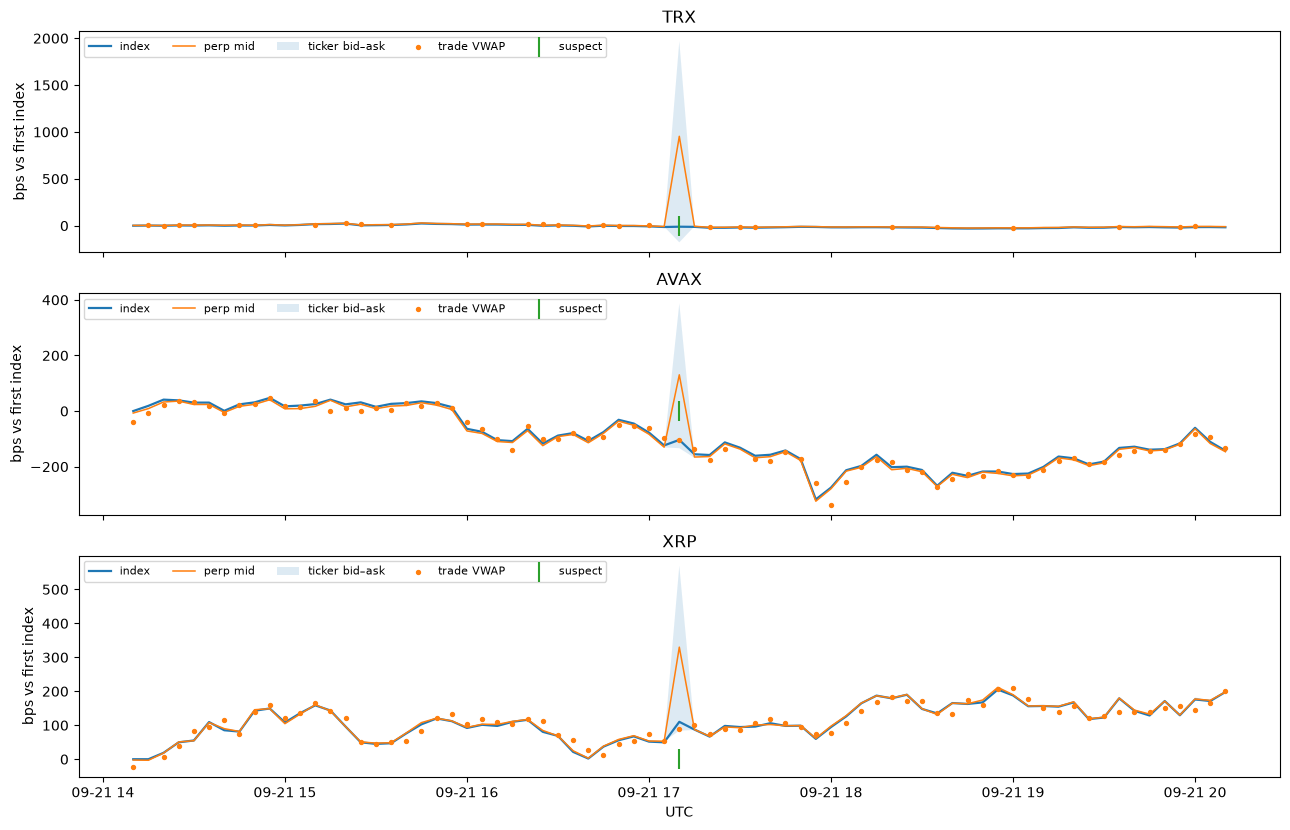


=== HYPE / XRP wide book spreads, no trades | 2026-09-28 06:25 – 12:25 UTC ===


,states,suspect,first_suspect,last_suspect,max_spread_bps,trades
underlying,,,,,,
HYPE,73,6,2026-09-28 09:05:00+00:00,2026-09-28 09:30:00+00:00,620.346856,1733
XRP,73,4,2026-09-28 09:05:00+00:00,2026-09-28 09:20:00+00:00,24.843052,1195


,bar_end,underlying,tick_spread_bps,l2_spread_bps,mid_vs_index_bps,vwap_vs_index_bps,tick_vs_l2_mid_bps,bbo_run_bars,index_drift_since_bbo_change_bps,last_trade_outside_bbo_bps,trade_count,volume_usd,book_update_count,book_age_ms,ticker_age_ms,mid_return_5m_raw,index_return_5m,stream_complete,suspect_quote,flag_wide_spread,flag_mid_off_index,flag_stale_vs_index,flag_frozen_with_trades,flag_no_l2_updates,flag_no_two_sided,flag_tick_l2_disagree,flag_trade_outside_bbo
14932,2026-09-28 09:05:00+00:00,HYPE,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,4,15821.40095,27.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,True,False,False
14933,2026-09-28 09:10:00+00:00,HYPE,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,True,False,False
14934,2026-09-28 09:15:00+00:00,HYPE,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,True,False,False
14935,2026-09-28 09:20:00+00:00,HYPE,620.346856,NaN,316.429765,NaN,NaN,1,NaN,NaN,0,0.00000,3.0,166.0,166.0,NaN,NaN,False,True,True,True,False,False,False,False,False,False
14936,2026-09-28 09:25:00+00:00,HYPE,523.813942,NaN,269.545873,NaN,NaN,1,NaN,NaN,0,0.00000,167.0,288.0,1215.0,-0.005719,-0.001031,True,True,True,True,False,False,False,False,False,False
14937,2026-09-28 09:30:00+00:00,HYPE,529.528010,NaN,271.809392,NaN,NaN,1,NaN,NaN,0,0.00000,220.0,1929.0,1072.0,-0.000278,-0.000505,True,True,True,True,False,False,False,False,False,False
27868,2026-09-28 09:05:00+00:00,XRP,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,1,69.61170,45.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,True,False,False
27869,2026-09-28 09:10:00+00:00,XRP,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,True,False,False
27870,2026-09-28 09:15:00+00:00,XRP,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,0,0.00000,0.0,NaN,NaN,NaN,NaN,False,True,False,False,False,False,False,True,False,False
27871,2026-09-28 09:20:00+00:00,XRP,24.843052,NaN,35.312552,122.780138,NaN,1,NaN,NaN,10,2853.12240,14.0,260.0,260.0,NaN,NaN,False,True,False,True,False,False,False,False,False,False


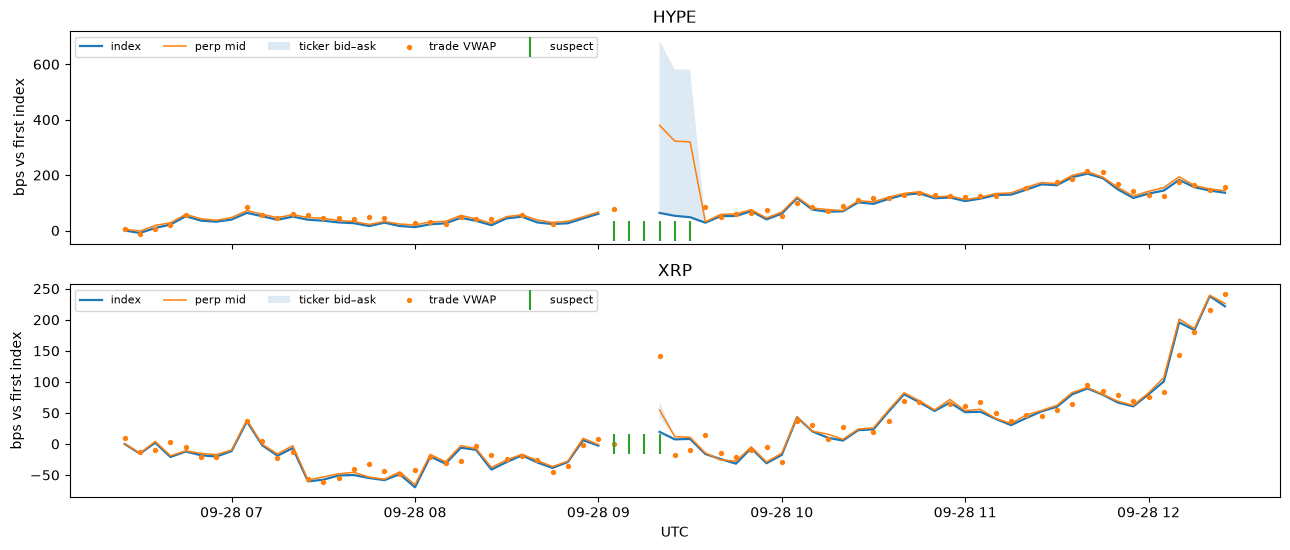


=== Deribit migration window: frozen BBO while trading | 2026-10-01 06:30 – 12:30 UTC ===


,states,suspect,first_suspect,last_suspect,max_spread_bps,trades
underlying,,,,,,
AVAX,73,14,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,127.916404,708
HYPE,73,14,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,328.927522,987
TRX,73,14,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,189.781676,976
XRP,73,14,2026-10-01 09:00:00+00:00,2026-10-01 10:05:00+00:00,487.063411,2516


,bar_end,underlying,tick_spread_bps,l2_spread_bps,mid_vs_index_bps,vwap_vs_index_bps,tick_vs_l2_mid_bps,bbo_run_bars,index_drift_since_bbo_change_bps,last_trade_outside_bbo_bps,trade_count,volume_usd,book_update_count,book_age_ms,ticker_age_ms,mid_return_5m_raw,index_return_5m,stream_complete,suspect_quote,flag_wide_spread,flag_mid_off_index,flag_stale_vs_index,flag_frozen_with_trades,flag_no_l2_updates,flag_no_two_sided,flag_tick_l2_disagree,flag_trade_outside_bbo
2859,2026-10-01 09:00:00+00:00,AVAX,7.191658,NaN,3.596475,-6.617916,NaN,1,NaN,NaN,2,3.140433e+01,492.0,2595.0,2247.0,0.002520,0.002521,True,True,False,False,False,False,False,False,False,False
2860,2026-10-01 09:05:00+00:00,AVAX,127.916404,NaN,-4.503085,-66.853623,NaN,1,NaN,NaN,3,1.116166e+05,165.0,117038.0,2140.0,-0.002070,-0.001260,True,True,False,False,False,False,False,False,False,False
2861,2026-10-01 09:10:00+00:00,AVAX,127.916404,NaN,-39.557725,-101.908263,NaN,2,35.054640,NaN,2,2.634839e+03,0.0,417038.0,1033.0,0.000000,0.003505,True,True,False,True,False,False,True,False,False,False
2862,2026-10-01 09:15:00+00:00,AVAX,127.916404,NaN,-22.495173,NaN,NaN,3,17.992088,NaN,0,0.000000e+00,0.0,717038.0,1928.0,0.000000,-0.001706,True,True,False,True,False,False,False,False,False,False
2863,2026-10-01 09:20:00+00:00,AVAX,127.916404,NaN,-8.104093,-70.454632,NaN,4,3.601008,NaN,35,3.366552e+05,0.0,1017038.0,1824.0,0.000000,-0.001439,True,True,False,False,False,False,True,False,False,False
2864,2026-10-01 09:25:00+00:00,AVAX,127.916404,NaN,-2.702094,-65.052633,NaN,5,1.800991,NaN,1,5.516000e+02,0.0,1317038.0,2724.0,0.000000,-0.000540,True,True,False,False,False,True,True,False,False,False
2865,2026-10-01 09:30:00+00:00,AVAX,127.916404,NaN,3.603928,-58.746610,NaN,6,8.107013,NaN,34,3.031723e+04,0.0,1617038.0,1610.0,0.000000,-0.000631,True,True,False,False,False,True,True,False,False,False
2866,2026-10-01 09:35:00+00:00,AVAX,127.916404,NaN,9.012257,-53.338281,NaN,7,13.515342,NaN,12,3.832448e+04,0.0,1917038.0,1506.0,0.000000,-0.000541,True,True,False,False,False,True,True,False,False,False
2867,2026-10-01 09:40:00+00:00,AVAX,127.916404,NaN,34.289873,-28.060666,NaN,8,38.792958,NaN,21,2.369847e+05,0.0,2217038.0,4409.0,0.000000,-0.002528,True,True,False,True,False,True,True,False,False,False
2868,2026-10-01 09:45:00+00:00,AVAX,127.916404,NaN,45.142727,-17.207811,NaN,9,49.645812,NaN,15,1.151160e+05,0.0,2517038.0,22432.0,0.000000,-0.001085,True,True,False,True,False,True,True,False,False,False


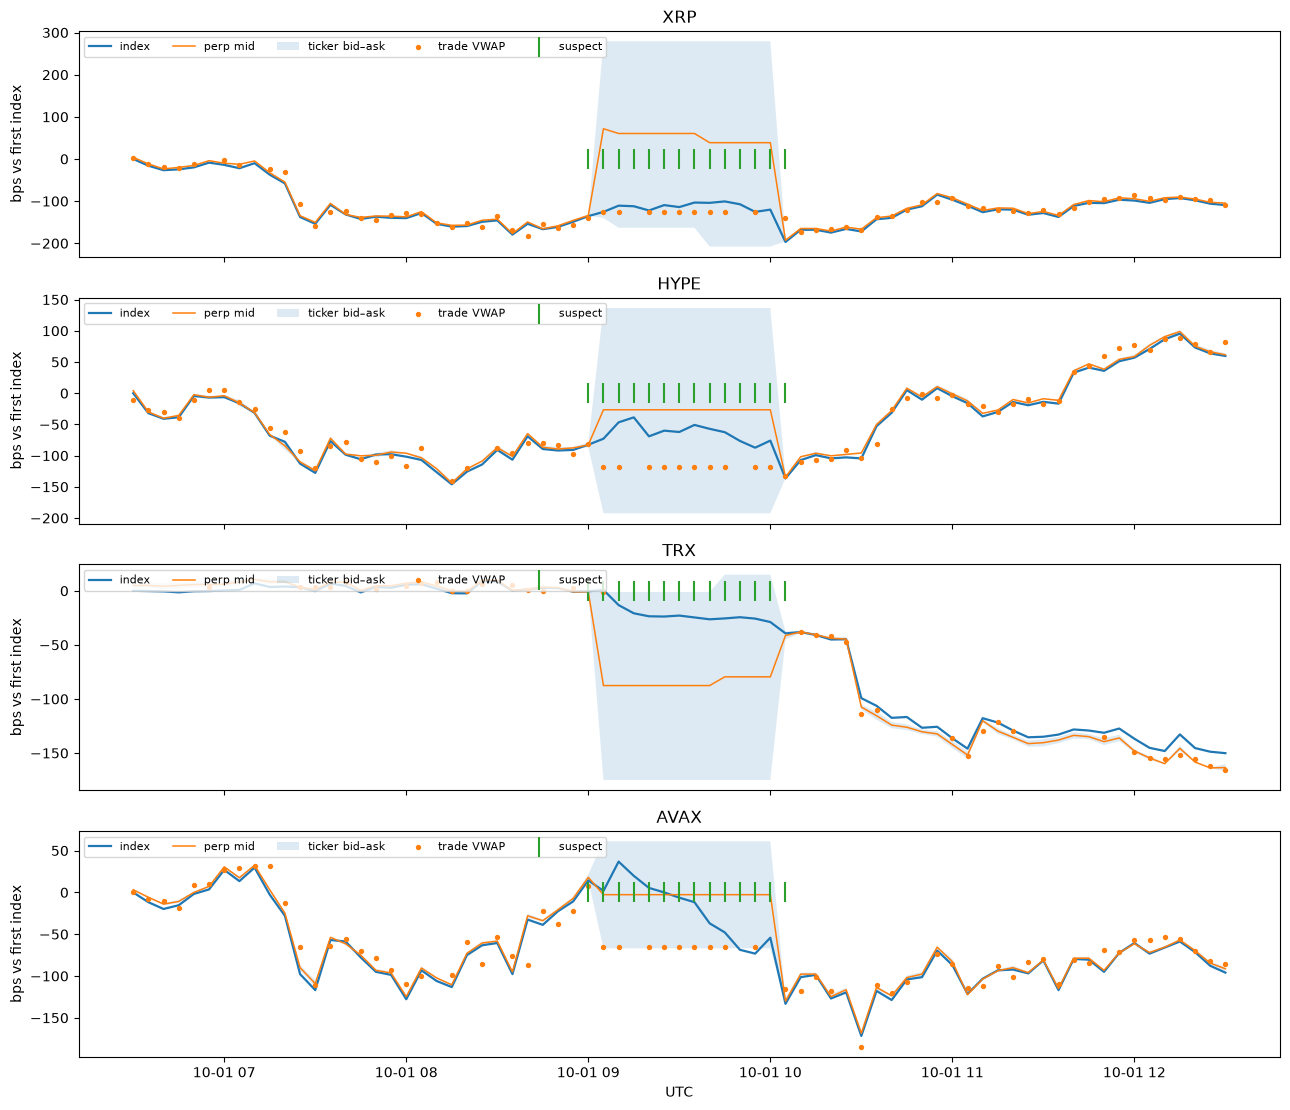

In [170]:
KNOWN_WINDOWS = [
    ("TRX ±9.6% round trip on zero volume", "2026-09-21 17:10", ["TRX", "AVAX", "XRP"]),
    ("HYPE / XRP wide book spreads, no trades", "2026-09-28 09:25", ["HYPE", "XRP"]),
    ("Deribit migration window: frozen BBO while trading", "2026-10-01 09:30", ["XRP", "HYPE", "TRX", "AVAX"]),
]
WINDOW_HALF_WIDTH = pd.Timedelta(hours=3)

window_cols = [
    "bar_end", "underlying", "tick_spread_bps", "l2_spread_bps", "mid_vs_index_bps",
    "vwap_vs_index_bps", "tick_vs_l2_mid_bps", "bbo_run_bars", "index_drift_since_bbo_change_bps",
    "last_trade_outside_bbo_bps", "trade_count", "volume_usd", "book_update_count",
    "book_age_ms", "ticker_age_ms", "mid_return_5m_raw", "index_return_5m",
    "stream_complete", "suspect_quote",
] + FLAG_COLS
window_cols = [c for c in window_cols if c in integrity.columns]

for title, centre, assets in KNOWN_WINDOWS:
    centre = pd.Timestamp(centre, tz="UTC")
    lo, hi = centre - WINDOW_HALF_WIDTH, centre + WINDOW_HALF_WIDTH
    w = integrity[(integrity["bar_end"].between(lo, hi)) & (integrity["underlying"].isin(assets))]

    print(f"\n=== {title} | {lo:%Y-%m-%d %H:%M} – {hi:%H:%M} UTC ===")
    if w.empty:
        print("No raw rows in this window.")
        continue

    display(
        w.groupby("underlying").agg(
            states=("bar_end", "size"),
            suspect=("suspect_quote", "sum"),
            first_suspect=("bar_end", lambda s: s[w.loc[s.index, "suspect_quote"]].min()),
            last_suspect=("bar_end", lambda s: s[w.loc[s.index, "suspect_quote"]].max()),
            max_spread_bps=("tick_spread_bps", "max"),
            trades=("trade_count", "sum"),
        )
    )
    display(w.loc[w["suspect_quote"], window_cols].head(40))

    fig, axes = plt.subplots(len(assets), 1, figsize=(13, 2.8 * len(assets)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, asset in zip(axes, assets):
        a = w[w["underlying"] == asset].sort_values("bar_end")
        if a.empty:
            ax.set_title(f"{asset}: no rows")
            continue
        ref = pd.to_numeric(a["index_price"], errors="coerce")
        base = ref.dropna().iloc[0] if ref.notna().any() else np.nan
        to_bps = lambda s: 1e4 * np.log(pd.to_numeric(s, errors="coerce") / base)
        ax.plot(a["bar_end"], to_bps(a["index_price"]), label="index", linewidth=1.6)
        ax.plot(a["bar_end"], to_bps(a["tick_mid"]), label="perp mid", linewidth=1.1)
        ax.fill_between(
            a["bar_end"], to_bps(a["best_bid_price"]), to_bps(a["best_ask_price"]),
            alpha=0.15, label="ticker bid–ask",
        )
        ax.scatter(a["bar_end"], to_bps(a["vwap"]), s=8, label="trade VWAP", zorder=3)
        sus = a[a["suspect_quote"]]
        ax.scatter(sus["bar_end"], np.zeros(len(sus)), marker="|", s=200, label="suspect", zorder=4)
        ax.set_title(asset)
        ax.set_ylabel("bps vs first index")
        ax.legend(loc="upper left", fontsize=8, ncol=5)
    axes[-1].set_xlabel("UTC")
    plt.tight_layout()
    plt.show()

## 30. Impact on returns and realized volatility

From market feature **v0.2.0**, `return_5m` and the realized-volatility columns are computed from the **Deribit index** (`return_source = 'deribit_index'`). The previous perpetual-mid return is kept as the diagnostic column `perp_mid_return_5m`.

Three series are compared on the same grid:

1. `perp_mid_return_5m`: the perpetual mid (the pre-v0.2.0 definition);
2. the same mid return with any return whose start or end state is suspect set to missing;
3. `return_5m`: the index return now used by the pipeline.

The recomputed raw mid and index returns are first checked against the pipeline columns, so the comparison is between data sources and not between implementations.

What to look for: the index should keep the genuine tails and median volatility while losing the isolated spikes. Masking the mid should **not** be the fix, because any flag correlated with volatility censors the high-volatility bars the regime model needs.

Pipeline return_source: ['deribit_index']
perp mid  pairs:  29,141 | max |pipeline − raw|: 0.000e+00 | pipeline values without raw value: 0
index     pairs:  29,139 | max |pipeline − raw|: 0.000e+00 | pipeline values without raw value: 0
Return distribution by source:


n                                     zero_share_pct                                            std_bps                                    excess_kurtosis            \
series     index (pipeline) perp mid perp mid, suspect masked index (pipeline) perp mid perp mid, suspect masked index (pipeline) perp mid perp mid, suspect masked index (pipeline)  perp mid   
underlying                                                                                                                                                                                       
AVAX                   4163     4163                     4138            1.778    1.273                    1.015           29.261   29.861                   28.834            6.104    10.039   
BTC                    4163     4163                     4144            0.000    0.432                    0.169           10.630   10.730                   10.744            9.095     9.601   
ETH                    4163     4163                     4142            0.168    0.456                    0.217           12.877   13.004                   12.891            9.190     9.236   
HYPE                   4163     4163                     4142            0.168    0.360                    0.097           20.195   20.992                   20.198            4.138    12.341   
SOL                    4163     4163                     4139            0.120    0.432                    0.193           17.891   17.996                   17.950           10.699    10.420   
TRX                    4161     4163                     4144            0.457    5.525                    5.285            4.653   21.654                    4.686           10.441  1867.486   
XRP                    4163     4163                     4142            2.018    1.489                    1.280           22.094   23.394                   22.008            7.801    17.563   

                                         max_abs_bps                                    
series     perp mid, suspect masked index (pipeline) perp mid perp mid, suspect masked  
underlying                                                                              
AVAX                          6.297          230.293  295.783                  241.222  
BTC                           9.584          112.049  116.794                  116.794  
ETH                           8.937          136.669  140.169                  140.169  
HYPE                          3.994          148.433  288.146                  146.899  
SOL                          10.414          213.748  211.248                  211.248  
TRX                          14.204           54.502  962.766                   62.890  
XRP                           7.558          188.785  276.821                  189.722

Mid vs index agreement and 30m RV (annualized):


,underlying,corr_mid_index,max_rv30_mid,max_rv30_mid_masked,max_rv30_index,median_rv30_mid,median_rv30_index,masked_share_pct
0,AVAX,0.9735,5.3042,3.5418,3.5219,0.7149,0.7229,0.5832
1,BTC,0.9936,1.6264,1.6264,1.5539,0.2329,0.2315,0.4432
2,ETH,0.9948,1.9812,1.9812,1.9204,0.2863,0.2850,0.4899
3,HYPE,0.9620,3.8667,2.6927,2.7565,0.5132,0.5085,0.4899
4,SOL,0.9958,3.0651,3.0651,3.1132,0.4166,0.4137,0.5598
5,TRX,0.2144,17.9984,0.8487,0.7451,0.1084,0.1100,0.4432
6,XRP,0.9608,4.8973,3.5024,3.4934,0.4908,0.4883,0.4899


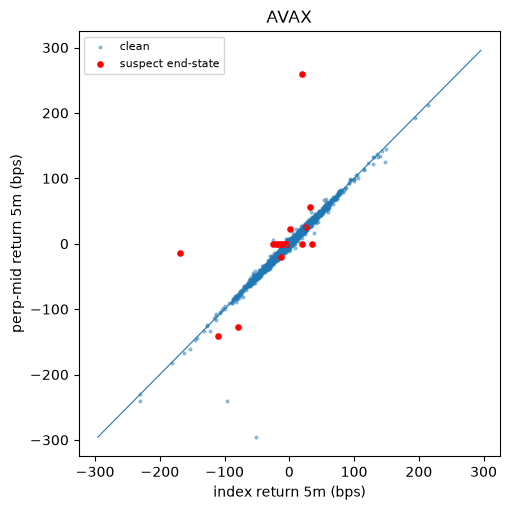

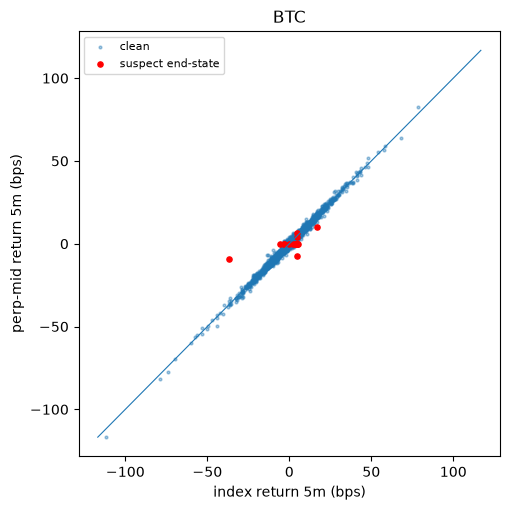

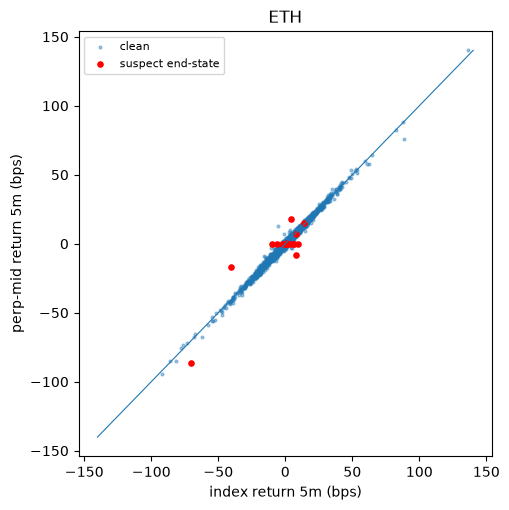

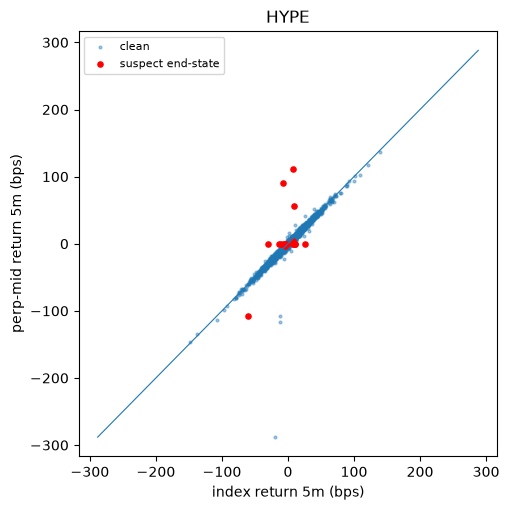

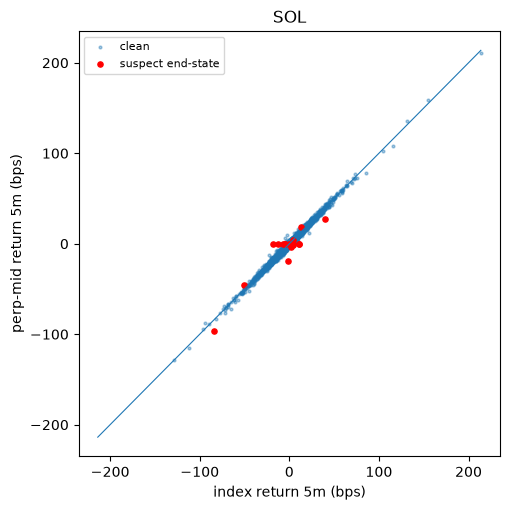

In [ ]:
has_perp_col = "perp_mid_return_5m" in features.columns
pipeline_source = (
    features["return_source"].dropna().unique().tolist()
    if "return_source" in features.columns else ["perp_mid (pre-v0.2.0 table)"]
)
print(f"Pipeline return_source: {pipeline_source}")
if not has_perp_col:
    print("perp_mid_return_5m not found: the feature table predates v0.2.0. "
          "Rebuild with build_features.py before reading this section.")

feature_cols = ["underlying", "state_time", "return_5m", "realized_vol_30m_annualized"]
if has_perp_col:
    feature_cols.append("perp_mid_return_5m")

impact = integrity.merge(
    features[feature_cols].assign(state_time=lambda d: pd.to_datetime(d["state_time"], utc=True)),
    left_on=["underlying", "bar_end"],
    right_on=["underlying", "state_time"],
    how="inner",
).sort_values(["underlying", "bar_end"])

mid_col = "perp_mid_return_5m" if has_perp_col else "return_5m"
index_col = "return_5m" if has_perp_col else "index_return_5m"

# 1) Implementation checks against the pipeline.
for label, pipe, raw in [
    ("perp mid", mid_col, "mid_return_5m_raw"),
    ("index", index_col, "index_return_5m"),
]:
    both = impact[[pipe, raw]].dropna()
    print(
        f"{label:<9} pairs: {len(both):>7,} | max |pipeline − raw|: "
        f"{(both[pipe] - both[raw]).abs().max():.3e} | "
        f"pipeline values without raw value: {int(impact[pipe].notna().sum() - len(both)):,}"
    )

# 2) Mask mid returns touching a suspect endpoint.
impact = per_asset(impact, lambda g: g.assign(_prev_suspect=lag_on_grid(g, "suspect_quote")))
prev_suspect = impact["_prev_suspect"].fillna(False).astype(bool)
impact["mid_return_5m_clean"] = impact[mid_col].where(~(impact["suspect_quote"] | prev_suspect))

PERIODS_PER_YEAR = 365.0 * 24.0 * 12.0

def rv_annualized(r, window=6):
    """Complete-window RV, same definition as the pipeline (requires `window` returns)."""
    s = r.pow(2).rolling(window, min_periods=window).sum()
    return np.sqrt(s / window * PERIODS_PER_YEAR)

impact["rv30_mid"] = impact.groupby("underlying", group_keys=False)[mid_col].apply(rv_annualized)
impact["rv30_mid_clean"] = impact.groupby("underlying", group_keys=False)["mid_return_5m_clean"].apply(rv_annualized)
impact["rv30_index"] = impact.groupby("underlying", group_keys=False)[index_col].apply(rv_annualized)

rows, pair_rows = [], []
for asset, g in impact.groupby("underlying"):
    for label, col in [
        ("perp mid", mid_col),
        ("perp mid, suspect masked", "mid_return_5m_clean"),
        ("index (pipeline)", index_col),
    ]:
        s = g[col].dropna()
        rows.append({
            "underlying": asset,
            "series": label,
            "n": len(s),
            "zero_share_pct": 100 * (s == 0).mean() if len(s) else np.nan,
            "std_bps": 1e4 * s.std(),
            "excess_kurtosis": s.kurt(),
            "max_abs_bps": 1e4 * s.abs().max() if len(s) else np.nan,
        })

    pair = g[[mid_col, index_col]].dropna()
    pair_rows.append({
        "underlying": asset,
        "corr_mid_index": pair.corr().iloc[0, 1] if len(pair) > 20 else np.nan,
        "max_rv30_mid": g["rv30_mid"].max(),
        "max_rv30_mid_masked": g["rv30_mid_clean"].max(),
        "max_rv30_index": g["rv30_index"].max(),
        "median_rv30_mid": g["rv30_mid"].median(),
        "median_rv30_index": g["rv30_index"].median(),
        "masked_share_pct": 100 * (g[mid_col].notna() & g["mid_return_5m_clean"].isna()).mean(),
    })

return_source_impact = pd.DataFrame(rows)
return_source_pairs = pd.DataFrame(pair_rows)
print("Return distribution by source:")
display(return_source_impact.pivot(index="underlying", columns="series").round(3))
print("Mid vs index agreement and 30m RV (annualized):")
display(return_source_pairs.round(4))

for asset, g in impact.groupby("underlying"):
    pair = g[[mid_col, index_col, "suspect_quote"]].dropna(subset=[mid_col, index_col])
    if pair.empty:
        continue
    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    ax.scatter(1e4 * pair[index_col], 1e4 * pair[mid_col], s=4, alpha=0.4, label="clean")
    s = pair[pair["suspect_quote"]]
    ax.scatter(1e4 * s[index_col], 1e4 * s[mid_col], s=14, color="red", label="suspect end-state")
    lim = np.nanmax(np.abs(1e4 * pair[[mid_col, index_col]].to_numpy()))
    ax.plot([-lim, lim], [-lim, lim], linewidth=0.8)
    ax.set_xlabel("index return 5m (bps)")
    ax.set_ylabel("perp-mid return 5m (bps)")
    ax.set_title(asset)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 31. Open-interest jumps

The first run of this section rejected the sawtooth hypothesis (OI returns are about half negative, median ≈ 0) and attributed 9 of the 16 jumps above 10% to **09:05 and 09:20 UTC on 1 Oct**. That is the Deribit migration window: positions from Coinbase International were transferred onto Deribit's perpetuals. Those OI steps are real positions but not trading activity, and the new levels persisted.

Consequences tested below:

1. **Version boundary.** OI levels before and after `OI_VERSION_BOUNDARY` are not comparable. OI changes inside the migration window are excluded.
2. **Remaining jumps.** Jumps outside the migration are classified as one-bar reversals (`|next return| ≥ 80%` of the jump, opposite sign) or persistent level shifts.
3. **Static OI.** An asset whose OI is unchanged in most bars carries no OI information.

The table at the end gives a per-asset OI usability verdict. It is evidence for the feature contract, not a decision.

In [ ]:
OI_JUMP_THRESHOLD = 0.10
OI_VERSION_BOUNDARY = pd.Timestamp("2026-10-01 10:05", tz="UTC")
OI_STATIC_MAX_SHARE = 0.25          # OI unchanged in more than this share of bars -> uninformative

oi = raw_futures_all.sort_values(["underlying", "bar_end"]).copy()
oi["open_interest"] = pd.to_numeric(oi["open_interest"], errors="coerce")
oi = per_asset(oi, lambda g: g.assign(_prev_oi=lag_on_grid(g, "open_interest")))
oi["oi_return_5m"] = (oi["open_interest"] / oi["_prev_oi"] - 1).where(oi["_prev_oi"] > 0)
oi["_next_oi_return"] = oi.groupby("underlying")["oi_return_5m"].shift(-1)
oi["_prev_instrument"] = oi.groupby("underlying")["instrument_name"].shift(1)
oi["instrument_changed"] = oi["instrument_name"] != oi["_prev_instrument"]
oi["utc_hhmm"] = oi["bar_end"].dt.strftime("%H:%M")

event_mask = pd.Series(False, index=oi.index)
for start, end, _label in KNOWN_EXCHANGE_EVENTS:
    event_mask |= oi["bar_end"].between(pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC"))
oi["in_known_event"] = event_mask
oi["oi_regime"] = np.where(oi["bar_end"] > OI_VERSION_BOUNDARY, "post-migration", "pre-migration")

jumps = oi[oi["oi_return_5m"].abs() > OI_JUMP_THRESHOLD].copy()
reverts = (
    (np.sign(jumps["_next_oi_return"]) == -np.sign(jumps["oi_return_5m"]))
    & (jumps["_next_oi_return"].abs() >= 0.8 * jumps["oi_return_5m"].abs() / (1 + jumps["oi_return_5m"]))
)
jumps["jump_type"] = np.select(
    [jumps["in_known_event"], reverts],
    ["migration (known event)", "one-bar reversal"],
    default="persistent level shift",
)

jump_cols = [
    "underlying", "bar_end", "utc_hhmm", "jump_type", "instrument_changed",
    "_prev_oi", "open_interest", "oi_return_5m", "_next_oi_return",
    "stream_complete", "ticker_age_ms", "trade_count", "volume_usd",
]
oi_jumps = jumps[[c for c in jump_cols if c in jumps.columns]].sort_values("bar_end")
print(f"OI jumps with |return| > {OI_JUMP_THRESHOLD:.0%}: {len(oi_jumps):,}")
display(oi_jumps["jump_type"].value_counts().to_frame("jumps"))
display(oi_jumps)

# Level break at the migration.
level = (
    oi[~oi["in_known_event"]]
    .groupby(["underlying", "oi_regime"])["open_interest"]
    .median()
    .unstack()
)
if {"pre-migration", "post-migration"}.issubset(level.columns):
    level["post_over_pre"] = level["post-migration"] / level["pre-migration"]
print("Median OI before and after the migration boundary:")
display(level.round(3))

# Per-asset usability evidence (migration window excluded).
clean = oi[~oi["in_known_event"]]
usability = clean.groupby("underlying").agg(
    bars=("oi_return_5m", "count"),
    static_share=("oi_return_5m", lambda s: (s == 0).mean()),
    negative_share=("oi_return_5m", lambda s: (s < 0).mean()),
    abs_ret_p99_pct=("oi_return_5m", lambda s: 100 * s.abs().quantile(0.99)),
)
usability = usability.join(
    jumps[~jumps["in_known_event"]]
    .groupby("underlying")["jump_type"]
    .value_counts()
    .unstack(fill_value=0),
    how="left",
).fillna(0)
usability["oi_informative"] = usability["static_share"] <= OI_STATIC_MAX_SHARE
display(usability.round(4))

assets = sorted(oi["underlying"].dropna().unique())
fig, axes = plt.subplots(len(assets), 1, figsize=(13, 2.3 * len(assets)), sharex=True)
for ax, asset in zip(np.atleast_1d(axes), assets):
    a = oi[oi["underlying"] == asset]
    ax.plot(a["bar_end"], a["open_interest"], linewidth=0.9)
    j = jumps[jumps["underlying"] == asset]
    ax.scatter(j["bar_end"], j["open_interest"], color="red", s=12, zorder=3)
    ax.axvline(OI_VERSION_BOUNDARY, linestyle="--", linewidth=0.8)
    ax.set_title(f"{asset} open interest (red: |Δ| > {OI_JUMP_THRESHOLD:.0%}; dashed: migration boundary)", fontsize=10)
np.atleast_1d(axes)[-1].set_xlabel("UTC")
plt.tight_layout()
plt.show()

## 32. Integrity findings to carry forward

`futures_integrity_diagnostics` (in memory, keyed by `underlying × state_time`) holds every metric and flag from this part. It is **not** written to the database.

Findings from the first full run (2026-09-21 → 2026-10-05), to be re-checked after each rebuild:

1. **All three audit windows are data defects.** 1 Oct 09:00–10:05 (all 7 assets) was Deribit's planned migration. 21 Sep 17:10 (AVAX/TRX/XRP, one snapshot) and 28 Sep 09:05–09:30 (collector outage, then wide alt quotes) are unexplained feed events affecting several assets at once.
2. **Structural returns moved to the index (feature v0.2.0).** On the perpetual mid, TRX return kurtosis was 1,508 and its correlation with the index 0.21. The index removes these artifacts and leaves median RV unchanged.
3. **Masking is not a substitute.** A flag correlated with volatility censors genuine high-volatility bars.
4. **Flags for the production gate** (to implement in `quality_contract.py` with training-only thresholds): frozen BBO with trades, no L2 updates with trades, no two-sided quote, mid off index with an absolute floor, wide spread with an absolute and relative floor, and known exchange events.
5. **Open interest** has a level break at the 1 Oct migration and is static for TRX and HYPE. See §31 for the per-asset verdict.

**Second run (feature v0.2.0, floors applied):**

- Suspect states fell from 1,736 to **154 in 43 episodes**; 98 are the known migration event. The one-tick false positives on BTC/ETH/SOL are gone.
- Outside the migration, the remaining suspect states are cross-asset: 21 Sep 17:10 (all 7 assets), 28 Sep 09:05–09:30 (collector outage, all 7) and a single bar on 5 Oct (all 7, no two-sided quote; most likely the v0.3.1 redeploy). Isolated single-asset states are rare (AVAX 23 Sep 14:15, 29–30 Sep; TRX 25 Sep 07:55; SOL 27 Sep).
- Index returns: TRX kurtosis 10.4 against 1,754 on the perp mid; HYPE 4.1 against 12.7; XRP 7.5 against 16.9. Median RV30 is unchanged on every asset. BTC, ETH and SOL index kurtosis (8.8–10.4) is genuine: there the mid and index agree (correlation ≥ 0.993).
- With the floors, masking the mid removes only 0.5–0.6% of returns and its maximum RV matches the index. The index remains the structural source because it is the settlement reference and survives frozen books without any threshold.
- Open interest: post/pre-migration median OI is 3.2× (BTC), 2.5× (ETH), 1.7× (HYPE), 1.4× (XRP), 1.3× (SOL). OI levels are comparable only within a regime; OI features need the 1 Oct 10:05 boundary. HYPE (31% static) and TRX (81% static) carry no OI information.
- Index freshness gate: of 76 states excluded by the 30 s ticker-age rule (70 TRX), the index had moved in 75. Feature v0.2.1 accepts ticker ages up to 90 s when the index changed since the previous state.

Post-v0.3 rows carry direct signals (`bbo_last_change`, `trades_outside_book_bbo`, REST stale confirmation). Once a few weeks exist, compare them with the pre-v0.3 proxies above on the overlapping period.

In [ ]:
futures_integrity_diagnostics = integrity.rename(columns={"bar_end": "state_time"})[
    ["underlying", "state_time", "suspect_quote", "known_exchange_event"]
    + FLAG_COLS
    + [c for c in metric_cols if c in integrity.columns]
    + ["index_return_5m", "mid_return_5m_raw"]
]

print(f"Rows:                 {len(futures_integrity_diagnostics):,}")
print(f"Suspect rows:         {int(futures_integrity_diagnostics['suspect_quote'].sum()):,}")
print(f"Known-event rows:     {int(futures_integrity_diagnostics['known_exchange_event'].sum()):,}")
print(f"Episodes:             {len(episodes):,}")
print(f"OI jumps:             {len(oi_jumps):,}")

# Part J — Research Handoff

## 33. Notebook 02 interpretation checklist

Before moving to `03_surface_distributions.ipynb`, record the answers to these questions:

1. Which market features show materially different scale across underlyings?
2. Which features have genuine structural boundary masses rather than smooth distributions?
3. Which tails are driven by isolated observations versus repeated episodes?
4. Are extreme spreads/basis observations concentrated in particular assets or market conditions?
5. Which variables show enough persistence to be plausible structural-state descriptors?
6. Which variables change too rapidly and may be better suited to the future noise/transition blocks?
7. Does `log1p_volume_usd` materially improve the activity representation relative to raw volume?
8. Which positive scale variables are plausible `log1p` candidates?
9. Which signed scale variables are plausible signed-log candidates?
10. Which bounded variables should remain in native support?
11. Is session-to-session distribution drift large enough to affect later chronological validation design?
12. Are any findings based on too little history to support a production decision?
13. Which tails in Parts A–E survive once suspect quote states are masked (Section 30)?
14. Should structural returns move from the perpetual mid to the index (audit A1), given Section 30?
15. Which integrity flags belong in the production gate, and which never fire (Section 32)?
16. What explains the open-interest jumps, and can OI features enter the contract (Section 31)?

**Do not freeze the model feature contract here.**  
Notebook 02 creates evidence for the later feature-contract decision; it does not make the final decision.

In [ ]:
market_distribution_report = {
    "overall_availability": overall_availability,
    "availability_by_asset": availability_by_asset,
    "return_pooled": return_pooled if "return_pooled" in globals() else pd.DataFrame(),
    "return_by_asset": return_by_asset if "return_by_asset" in globals() else pd.DataFrame(),
    "rv_summary": rv_summary if "rv_summary" in globals() else pd.DataFrame(),
    "rv_by_asset": rv_by_asset if "rv_by_asset" in globals() else pd.DataFrame(),
    "boundary_mass": boundary_mass if "boundary_mass" in globals() else pd.DataFrame(),
    "cross_asset_scale": cross_asset_scale if "cross_asset_scale" in globals() else pd.DataFrame(),
    "session_distribution": session_distribution if "session_distribution" in globals() else pd.DataFrame(),
    "transform_assessment": transform_assessment if "transform_assessment" in globals() else pd.DataFrame(),
    "integrity_flag_counts": flag_counts.reset_index() if "flag_counts" in globals() else pd.DataFrame(),
    "integrity_flag_sensitivity": flag_sensitivity if "flag_sensitivity" in globals() else pd.DataFrame(),
    "integrity_episodes": episodes if "episodes" in globals() else pd.DataFrame(),
    "return_source_impact": return_source_impact if "return_source_impact" in globals() else pd.DataFrame(),
    "return_source_pairs": return_source_pairs if "return_source_pairs" in globals() else pd.DataFrame(),
    "oi_jumps": oi_jumps if "oi_jumps" in globals() else pd.DataFrame(),
    "futures_integrity_diagnostics": futures_integrity_diagnostics if "futures_integrity_diagnostics" in globals() else pd.DataFrame(),
}

print("Market-distribution report sections:")
for name, frame in market_distribution_report.items():
    print(f"  {name:<28} {len(frame):>7,} rows")

## 34. Close the read-only connection

In [ ]:
con.close()
print("DuckDB connection closed.")